In [1]:
import fitz  # PyMuPDF
import pandas as pd
import numpy as np
import re
import os
from PIL import Image
import io
import matplotlib.pyplot as plt

In [2]:
pdf_file = '/Users/rodrigocarrillo/Library/CloudStorage/OneDrive-EmoryUniversity/Natural Language Processing Projects/Examen Residentado Peru/CONAREME/Year2023/PEDIATRÍA.pdf'

In [3]:
def extract_questions(pdf_path):
    doc = fitz.open(pdf_path)
    questions_data = []  # List to store questions

    # Updated regular expression: handle questions with or without a '?'
    #question_pattern = re.compile(r"(\d+)\.\s(.*?)(?:\?)?\s*(?=A\.)", re.DOTALL)
    question_pattern = re.compile(r"(\d+)\.\s(.*?\??)\s*(?=A\.)", re.DOTALL)

    for page in doc:
        text = page.get_text("text")  # Extract full page text
        
        # Find all questions in the text using findall()
        questions = question_pattern.findall(text)
        
        # Append all the questions to the questions_data list
        for _, question in questions:
            questions_data.append(question.strip())  # Store the cleaned question text

    # Convert extracted questions to DataFrame
    questions_df = pd.DataFrame(questions_data, columns=["question"])
    return questions_df

In [4]:
def extract_answers(pdf_path):
    doc = fitz.open(pdf_path)
    answers_data = []  # List to store answers for each question

    # Regular expression for extracting answers
    answer_pattern = re.compile(r"^(A|B|C|D)\.\s(.+)", re.MULTILINE)

    for page in doc:
        text = page.get_text("text")  # Extract full page text
        lines = text.split("\n")  # Split into lines for structured parsing

        current_answers = []  # List to store answers for a given question
        for line in lines:
            answer_match = answer_pattern.match(line)
            if answer_match:
                opt, ans_text = answer_match.groups()
                current_answers.append(ans_text.strip())

            # After four options are found, store them as one row in answers_data
            if len(current_answers) == 4:
                answers_data.append(current_answers)
                current_answers = []  # Reset for next question

    # Convert extracted answers to DataFrame with four columns
    answers_df = pd.DataFrame(answers_data, columns = ["option_A", "option_B", "option_C", "option_D"])
    return answers_df

In [5]:
def get_largest_rectangle(rects):
    """Return the largest rectangle from a list of rectangles."""
    if not rects:
        return None
    
    # Calculate area for each rectangle and store with index
    areas = [(abs((rect.br.x - rect.tl.x) * (rect.br.y - rect.tl.y)), idx) 
             for idx, rect in enumerate(rects)]
    
    # Sort by area (first element of tuple)
    areas.sort(key=lambda x: x[0], reverse=True)
    
    # Return the rectangle with largest area
    return rects[areas[0][1]]

def extract_correct_answers(pdf_path):
    doc = fitz.open(pdf_path)
    correct_answers = []
    missing_questions = []  # Track questions that were skipped
    
    # Flexible regex for answer choices (handles missing spaces like "A." and "A. ")
    answer_pattern = re.compile(r"^(A|B|C|D)\.\s(.+)", re.MULTILINE)
    
    for page_num, page in enumerate(doc, start=1):
        text = page.get_text("text")  # Extract full page text
        lines = text.split("\n")  # Split into lines
        
        # Extract valid answer positions using regex
        answer_positions = {key: [] for key in ["A", "B", "C", "D"]}
        
        for line in lines:
            match = answer_pattern.match(line)
            if match:
                answer_letter, answer_text = match.groups()
                
                # Try different search variations to find the best match
                search_texts = [
                    match.group(0),  # Original matched text
                    match.group(0).strip(),  # Stripped version
                    answer_letter + '.' + answer_text,  # Without space after period
                    answer_letter.upper() + '. ' + answer_text,  # Different case
                ]
                
                rects = None
                used_search_text = ""
                
                # Find the first successful search
                for search_text in search_texts:
                    rects = page.search_for(search_text)
                    if rects:
                        used_search_text = search_text
                        break
                
                if rects:
                    # Select the largest rectangle
                    largest_rect = get_largest_rectangle(rects)
                    if largest_rect:
                        answer_positions[answer_letter].append(largest_rect)
        
        # Find the maximum number of questions on the page
        num_questions = max(len(answer_positions["A"]), len(answer_positions["B"]),
                          len(answer_positions["C"]), len(answer_positions["D"]))
        
        # Debugging: Show how many answers were found
        print(f"\nPage {page_num}: Found {num_questions} questions")
        
        for idx in range(num_questions):
            best_answer = None
            best_yellow_pixels = 0  # Track the highest number of yellow pixels
            has_all_options = True  # Flag to check if we have all 4 options
            
            for answer_letter in ["A", "B", "C", "D"]:
                rects = answer_positions[answer_letter]
                if idx >= len(rects):
                    has_all_options = False  # Missing one or more options
                    continue
                
                rect = rects[idx]
                
                # Debugging: Print detected answer positions
                print(f"Page {page_num}, Q{idx+1} - {answer_letter}: Detected box: "
                      f"x0={rect.x0:.1f}, y0={rect.y0:.1f}, x1={rect.x1:.1f}, y1={rect.y1:.1f}")
                
                # Expand bounding box only to the right
                expanded_rect = fitz.Rect(rect.x0, rect.y0, rect.x1 + 50, rect.y1)
                
                # Extract pixels from the expanded region
                pixmap = page.get_pixmap(clip=expanded_rect)
                img = np.frombuffer(pixmap.samples, dtype=np.uint8).reshape(pixmap.h, pixmap.w, pixmap.n)
                
                # Count yellow pixels (pixels with high red and green, low blue)
                yellow_mask = (
                    (img[:, :, 0] > 200) &  # High red
                    (img[:, :, 1] > 200) &  # High green
                    (img[:, :, 2] < 150)    # Low blue
                )
                yellow_pixels = np.sum(yellow_mask)
                
                # Count total non-white pixels
                nonwhite_mask = ~np.all(img > 250, axis=2)
                total_pixels = np.sum(nonwhite_mask)
                
                # Debug information
                print(f"Page {page_num}, Q{idx+1}, {answer_letter}: Yellow pixels: {yellow_pixels}")
                print(f"Page {page_num}, Q{idx+1}, {answer_letter}: Total non-white pixels: {total_pixels}")
                
                if total_pixels > 0:
                    yellow_percentage = (yellow_pixels / total_pixels) * 100
                    print(f"Page {page_num}, Q{idx+1}, {answer_letter}: Yellow percentage: {yellow_percentage:.1f}%")
                
                # Display the box in the notebook
                plt.figure(figsize=(8, 4))
                plt.imshow(img)
                plt.gca().add_patch(plt.Rectangle((0, 0), expanded_rect.width, expanded_rect.height,
                                                fill=False, color='red', linewidth=2))
                plt.title(f'Page {page_num}, Q{idx+1}, Answer {answer_letter}\nYellow pixels: {yellow_pixels}')
                plt.axis('off')
                plt.show()
                
                # Store the best answer based on the highest number of yellow pixels
                if yellow_pixels > best_yellow_pixels:
                    best_yellow_pixels = yellow_pixels
                    best_answer = answer_letter
            
            # If missing options, log missing questions
            if not has_all_options:
                missing_questions.append(f"Page {page_num}, Q{idx+1}")
            
            if best_answer:
                correct_answers.append(best_answer)
                print(f"\nPage {page_num}, Q{idx+1} - Selected Answer: {best_answer} (based on yellow pixel count)")
                print("====================================================================================================")
                print("\n")
                print("\n")
    
    # Debugging: Print missing questions
    if missing_questions:
        print("\n⚠️ The following questions were skipped due to missing options:")
        for q in missing_questions:
            print(q)
    
    return pd.DataFrame(correct_answers, columns=["correct_answer"])


Page 1: Found 10 questions
Page 1, Q1 - A: Detected box: x0=68.3, y0=89.4, x1=298.0, y1=102.1
Page 1, Q1, A: Yellow pixels: 2820
Page 1, Q1, A: Total non-white pixels: 3934
Page 1, Q1, A: Yellow percentage: 71.7%


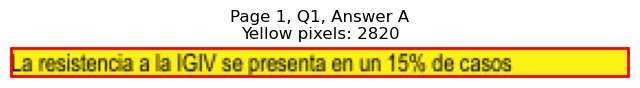

Page 1, Q1 - B: Detected box: x0=68.3, y0=102.0, x1=298.1, y1=114.7
Page 1, Q1, B: Yellow pixels: 0
Page 1, Q1, B: Total non-white pixels: 1400
Page 1, Q1, B: Yellow percentage: 0.0%


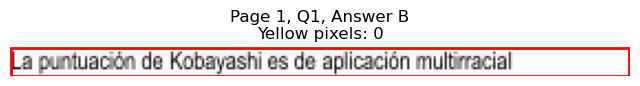

Page 1, Q1 - C: Detected box: x0=68.8, y0=114.6, x1=320.1, y1=127.3
Page 1, Q1, C: Yellow pixels: 0
Page 1, Q1, C: Total non-white pixels: 1168
Page 1, Q1, C: Yellow percentage: 0.0%


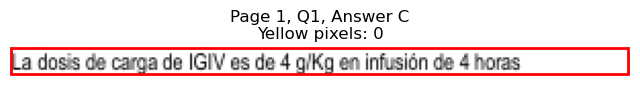

Page 1, Q1 - D: Detected box: x0=68.8, y0=127.2, x1=325.1, y1=139.9
Page 1, Q1, D: Yellow pixels: 0
Page 1, Q1, D: Total non-white pixels: 1175
Page 1, Q1, D: Yellow percentage: 0.0%


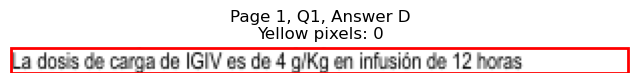


Page 1, Q1 - Selected Answer: A (based on yellow pixel count)




Page 1, Q2 - A: Detected box: x0=68.3, y0=165.1, x1=104.4, y1=177.8
Page 1, Q2, A: Yellow pixels: 0
Page 1, Q2, A: Total non-white pixels: 202
Page 1, Q2, A: Yellow percentage: 0.0%


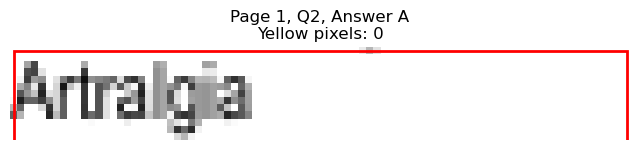

Page 1, Q2 - B: Detected box: x0=68.3, y0=177.7, x1=96.4, y1=190.4
Page 1, Q2, B: Yellow pixels: 0
Page 1, Q2, B: Total non-white pixels: 141
Page 1, Q2, B: Yellow percentage: 0.0%


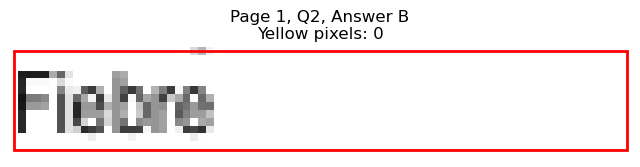

Page 1, Q2 - C: Detected box: x0=327.5, y0=165.1, x1=406.3, y1=177.8
Page 1, Q2, C: Yellow pixels: 1398
Page 1, Q2, C: Total non-white pixels: 1690
Page 1, Q2, C: Yellow percentage: 82.7%


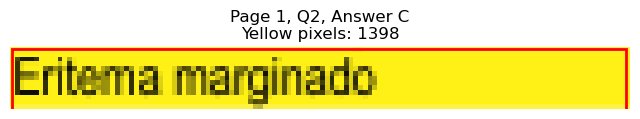

Page 1, Q2 - D: Detected box: x0=327.5, y0=177.7, x1=366.7, y1=190.4
Page 1, Q2, D: Yellow pixels: 88
Page 1, Q2, D: Total non-white pixels: 305
Page 1, Q2, D: Yellow percentage: 28.9%


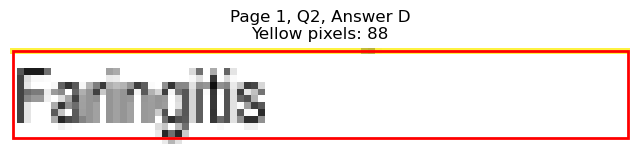


Page 1, Q2 - Selected Answer: C (based on yellow pixel count)




Page 1, Q3 - A: Detected box: x0=68.3, y0=253.5, x1=149.1, y1=266.1
Page 1, Q3, A: Yellow pixels: 0
Page 1, Q3, A: Total non-white pixels: 435
Page 1, Q3, A: Yellow percentage: 0.0%


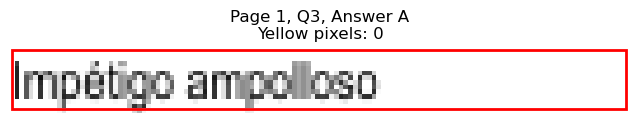

Page 1, Q3 - B: Detected box: x0=68.3, y0=266.1, x1=146.5, y1=278.7
Page 1, Q3, B: Yellow pixels: 0
Page 1, Q3, B: Total non-white pixels: 383
Page 1, Q3, B: Yellow percentage: 0.0%


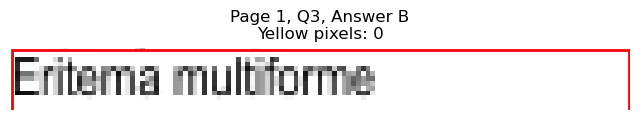

Page 1, Q3 - C: Detected box: x0=327.5, y0=253.5, x1=441.9, y1=266.1
Page 1, Q3, C: Yellow pixels: 165
Page 1, Q3, C: Total non-white pixels: 770
Page 1, Q3, C: Yellow percentage: 21.4%


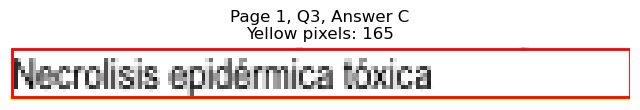

Page 1, Q3 - D: Detected box: x0=327.5, y0=266.1, x1=415.9, y1=278.7
Page 1, Q3, D: Yellow pixels: 1456
Page 1, Q3, D: Total non-white pixels: 1807
Page 1, Q3, D: Yellow percentage: 80.6%


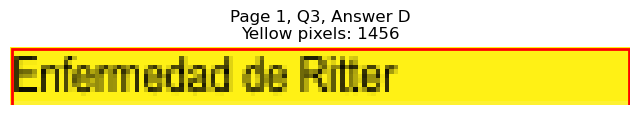


Page 1, Q3 - Selected Answer: D (based on yellow pixel count)




Page 1, Q4 - A: Detected box: x0=68.3, y0=316.6, x1=167.1, y1=329.3
Page 1, Q4, A: Yellow pixels: 150
Page 1, Q4, A: Total non-white pixels: 647
Page 1, Q4, A: Yellow percentage: 23.2%


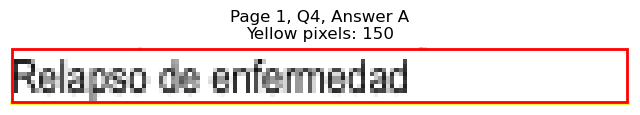

Page 1, Q4 - B: Detected box: x0=68.3, y0=329.2, x1=142.0, y1=341.9
Page 1, Q4, B: Yellow pixels: 1339
Page 1, Q4, B: Total non-white pixels: 1612
Page 1, Q4, B: Yellow percentage: 83.1%


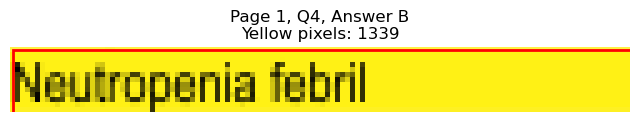

Page 1, Q4 - C: Detected box: x0=327.5, y0=316.6, x1=440.8, y1=329.3
Page 1, Q4, C: Yellow pixels: 0
Page 1, Q4, C: Total non-white pixels: 595
Page 1, Q4, C: Yellow percentage: 0.0%


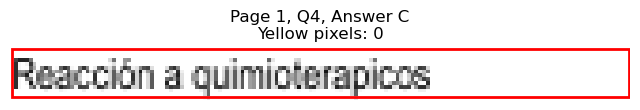

Page 1, Q4 - D: Detected box: x0=327.5, y0=329.2, x1=431.8, y1=341.9
Page 1, Q4, D: Yellow pixels: 0
Page 1, Q4, D: Total non-white pixels: 524
Page 1, Q4, D: Yellow percentage: 0.0%


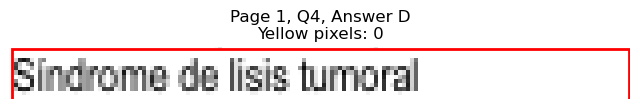


Page 1, Q4 - Selected Answer: B (based on yellow pixel count)




Page 1, Q5 - A: Detected box: x0=68.3, y0=392.3, x1=109.0, y1=405.0
Page 1, Q5, A: Yellow pixels: 0
Page 1, Q5, A: Total non-white pixels: 295
Page 1, Q5, A: Yellow percentage: 0.0%


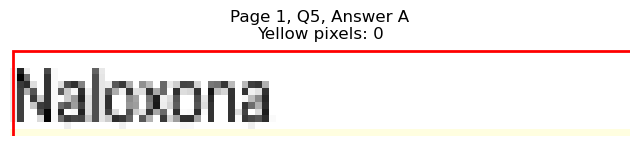

Page 1, Q5 - B: Detected box: x0=68.3, y0=404.9, x1=132.0, y1=417.6
Page 1, Q5, B: Yellow pixels: 1247
Page 1, Q5, B: Total non-white pixels: 1610
Page 1, Q5, B: Yellow percentage: 77.5%


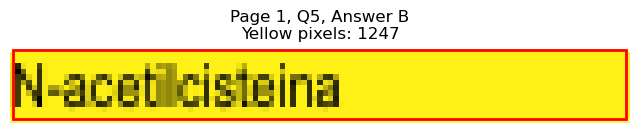

Page 1, Q5 - C: Detected box: x0=327.5, y0=392.3, x1=390.8, y1=405.0
Page 1, Q5, C: Yellow pixels: 0
Page 1, Q5, C: Total non-white pixels: 344
Page 1, Q5, C: Yellow percentage: 0.0%


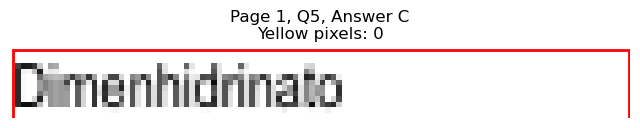

Page 1, Q5 - D: Detected box: x0=327.5, y0=404.9, x1=374.2, y1=417.6
Page 1, Q5, D: Yellow pixels: 0
Page 1, Q5, D: Total non-white pixels: 234
Page 1, Q5, D: Yellow percentage: 0.0%


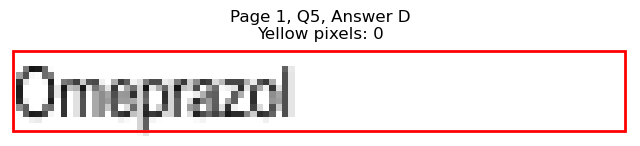


Page 1, Q5 - Selected Answer: B (based on yellow pixel count)




Page 1, Q6 - A: Detected box: x0=68.3, y0=468.1, x1=164.5, y1=480.7
Page 1, Q6, A: Yellow pixels: 0
Page 1, Q6, A: Total non-white pixels: 472
Page 1, Q6, A: Yellow percentage: 0.0%


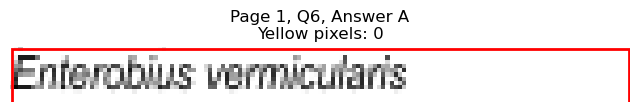

Page 1, Q6 - B: Detected box: x0=68.3, y0=480.8, x1=147.0, y1=493.4
Page 1, Q6, B: Yellow pixels: 0
Page 1, Q6, B: Total non-white pixels: 389
Page 1, Q6, B: Yellow percentage: 0.0%


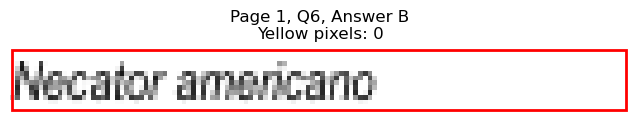

Page 1, Q6 - C: Detected box: x0=327.5, y0=468.1, x1=390.2, y1=480.7
Page 1, Q6, C: Yellow pixels: 0
Page 1, Q6, C: Total non-white pixels: 324
Page 1, Q6, C: Yellow percentage: 0.0%


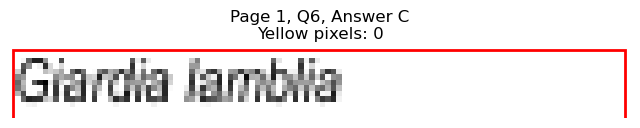

Page 1, Q6 - D: Detected box: x0=327.5, y0=480.8, x1=404.8, y1=493.4
Page 1, Q6, D: Yellow pixels: 1236
Page 1, Q6, D: Total non-white pixels: 1792
Page 1, Q6, D: Yellow percentage: 69.0%


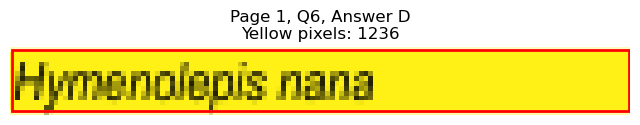


Page 1, Q6 - Selected Answer: D (based on yellow pixel count)




Page 1, Q7 - A: Detected box: x0=68.3, y0=543.8, x1=157.6, y1=556.4
Page 1, Q7, A: Yellow pixels: 0
Page 1, Q7, A: Total non-white pixels: 482
Page 1, Q7, A: Yellow percentage: 0.0%


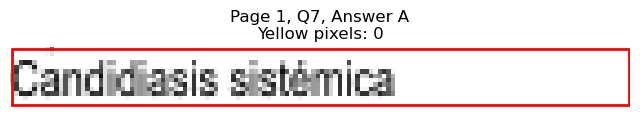

Page 1, Q7 - B: Detected box: x0=68.3, y0=556.5, x1=137.5, y1=569.2
Page 1, Q7, B: Yellow pixels: 0
Page 1, Q7, B: Total non-white pixels: 371
Page 1, Q7, B: Yellow percentage: 0.0%


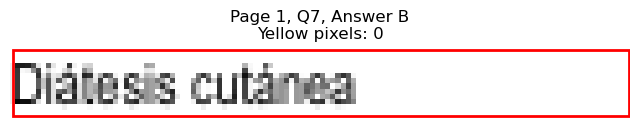

Page 1, Q7 - C: Detected box: x0=327.5, y0=543.8, x1=394.3, y1=556.4
Page 1, Q7, C: Yellow pixels: 0
Page 1, Q7, C: Total non-white pixels: 338
Page 1, Q7, C: Yellow percentage: 0.0%


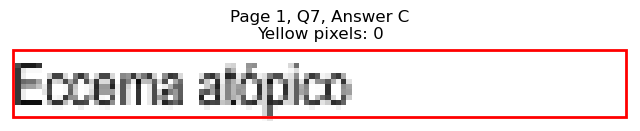

Page 1, Q7 - D: Detected box: x0=327.5, y0=556.5, x1=386.2, y1=569.2
Page 1, Q7, D: Yellow pixels: 1202
Page 1, Q7, D: Total non-white pixels: 1540
Page 1, Q7, D: Yellow percentage: 78.1%


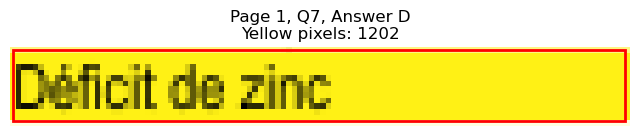


Page 1, Q7 - Selected Answer: D (based on yellow pixel count)




Page 1, Q8 - A: Detected box: x0=68.3, y0=594.3, x1=127.0, y1=607.0
Page 1, Q8, A: Yellow pixels: 0
Page 1, Q8, A: Total non-white pixels: 279
Page 1, Q8, A: Yellow percentage: 0.0%


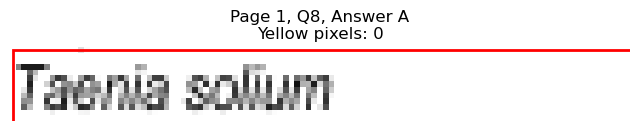

Page 1, Q8 - B: Detected box: x0=68.3, y0=606.9, x1=135.0, y1=619.6
Page 1, Q8, B: Yellow pixels: 0
Page 1, Q8, B: Total non-white pixels: 341
Page 1, Q8, B: Yellow percentage: 0.0%


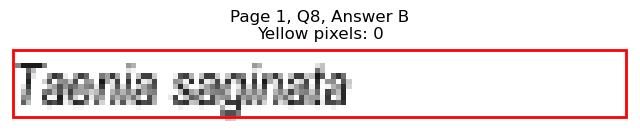

Page 1, Q8 - C: Detected box: x0=327.5, y0=594.3, x1=410.8, y1=607.0
Page 1, Q8, C: Yellow pixels: 0
Page 1, Q8, C: Total non-white pixels: 550
Page 1, Q8, C: Yellow percentage: 0.0%


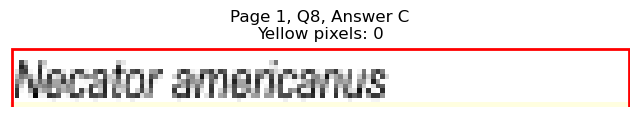

Page 1, Q8 - D: Detected box: x0=327.5, y0=606.9, x1=412.7, y1=619.6
Page 1, Q8, D: Yellow pixels: 1430
Page 1, Q8, D: Total non-white pixels: 1904
Page 1, Q8, D: Yellow percentage: 75.1%


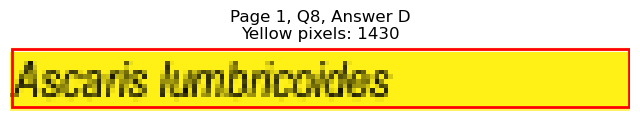


Page 1, Q8 - Selected Answer: D (based on yellow pixel count)




Page 1, Q9 - A: Detected box: x0=68.3, y0=657.5, x1=176.1, y1=670.1
Page 1, Q9, A: Yellow pixels: 159
Page 1, Q9, A: Total non-white pixels: 729
Page 1, Q9, A: Yellow percentage: 21.8%


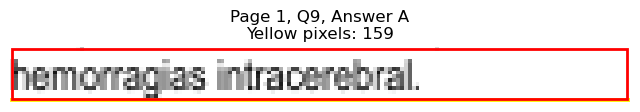

Page 1, Q9 - B: Detected box: x0=68.3, y0=670.1, x1=165.1, y1=682.7
Page 1, Q9, B: Yellow pixels: 1530
Page 1, Q9, B: Total non-white pixels: 1924
Page 1, Q9, B: Yellow percentage: 79.5%


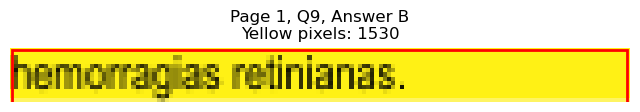

Page 1, Q9 - C: Detected box: x0=327.5, y0=657.5, x1=477.0, y1=670.1
Page 1, Q9, C: Yellow pixels: 0
Page 1, Q9, C: Total non-white pixels: 711
Page 1, Q9, C: Yellow percentage: 0.0%


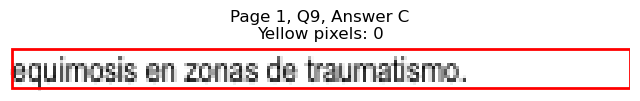

Page 1, Q9 - D: Detected box: x0=327.5, y0=670.1, x1=406.7, y1=682.7
Page 1, Q9, D: Yellow pixels: 0
Page 1, Q9, D: Total non-white pixels: 387
Page 1, Q9, D: Yellow percentage: 0.0%


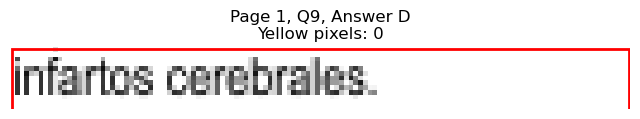


Page 1, Q9 - Selected Answer: B (based on yellow pixel count)




Page 1, Q10 - A: Detected box: x0=68.3, y0=745.8, x1=144.5, y1=758.4
Page 1, Q10, A: Yellow pixels: 1375
Page 1, Q10, A: Total non-white pixels: 1778
Page 1, Q10, A: Yellow percentage: 77.3%


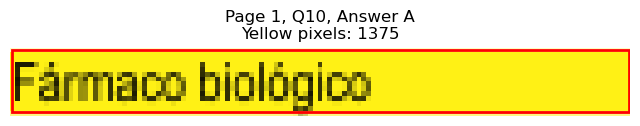

Page 1, Q10 - B: Detected box: x0=68.3, y0=758.5, x1=178.3, y1=771.2
Page 1, Q10, B: Yellow pixels: 159
Page 1, Q10, B: Total non-white pixels: 650
Page 1, Q10, B: Yellow percentage: 24.5%


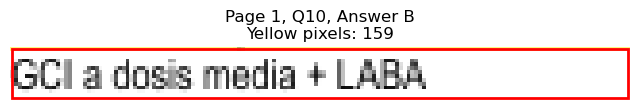

Page 1, Q10 - C: Detected box: x0=327.5, y0=745.8, x1=394.3, y1=758.4
Page 1, Q10, C: Yellow pixels: 0
Page 1, Q10, C: Total non-white pixels: 316
Page 1, Q10, C: Yellow percentage: 0.0%


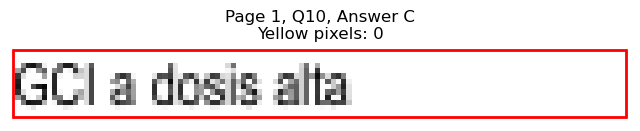

Page 1, Q10 - D: Detected box: x0=327.5, y0=758.5, x1=435.1, y1=771.2
Page 1, Q10, D: Yellow pixels: 0
Page 1, Q10, D: Total non-white pixels: 498
Page 1, Q10, D: Yellow percentage: 0.0%


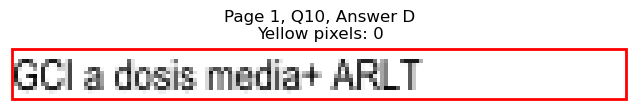


Page 1, Q10 - Selected Answer: A (based on yellow pixel count)





Page 2: Found 9 questions
Page 2, Q1 - A: Detected box: x0=68.3, y0=89.4, x1=113.4, y1=102.1
Page 2, Q1, A: Yellow pixels: 0
Page 2, Q1, A: Total non-white pixels: 238
Page 2, Q1, A: Yellow percentage: 0.0%


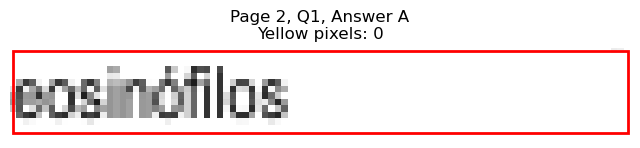

Page 2, Q1 - B: Detected box: x0=68.3, y0=102.0, x1=149.1, y1=114.7
Page 2, Q1, B: Yellow pixels: 0
Page 2, Q1, B: Total non-white pixels: 438
Page 2, Q1, B: Yellow percentage: 0.0%


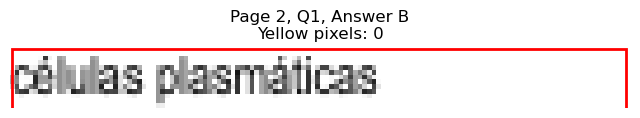

Page 2, Q1 - C: Detected box: x0=327.5, y0=89.4, x1=373.1, y1=102.1
Page 2, Q1, C: Yellow pixels: 97
Page 2, Q1, C: Total non-white pixels: 302
Page 2, Q1, C: Yellow percentage: 32.1%


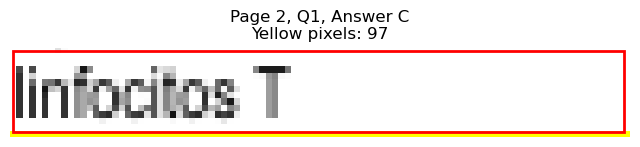

Page 2, Q1 - D: Detected box: x0=327.5, y0=102.0, x1=373.7, y1=114.7
Page 2, Q1, D: Yellow pixels: 1097
Page 2, Q1, D: Total non-white pixels: 1261
Page 2, Q1, D: Yellow percentage: 87.0%


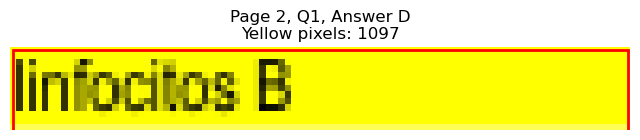


Page 2, Q1 - Selected Answer: D (based on yellow pixel count)




Page 2, Q2 - A: Detected box: x0=68.3, y0=139.9, x1=133.5, y1=152.6
Page 2, Q2, A: Yellow pixels: 116
Page 2, Q2, A: Total non-white pixels: 462
Page 2, Q2, A: Yellow percentage: 25.1%


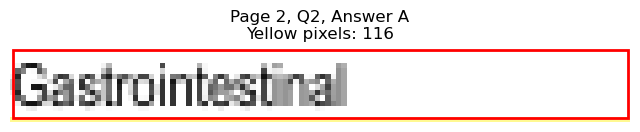

Page 2, Q2 - B: Detected box: x0=68.3, y0=152.5, x1=188.2, y1=165.2
Page 2, Q2, B: Yellow pixels: 1772
Page 2, Q2, B: Total non-white pixels: 2394
Page 2, Q2, B: Yellow percentage: 74.0%


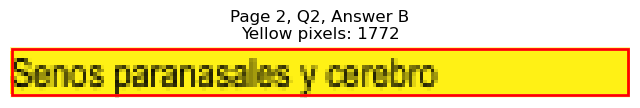

Page 2, Q2 - C: Detected box: x0=327.5, y0=139.9, x1=386.7, y1=152.6
Page 2, Q2, C: Yellow pixels: 0
Page 2, Q2, C: Total non-white pixels: 312
Page 2, Q2, C: Yellow percentage: 0.0%


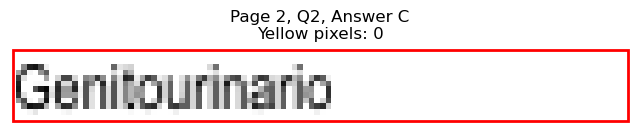

Page 2, Q2 - D: Detected box: x0=327.5, y0=152.5, x1=368.7, y1=165.2
Page 2, Q2, D: Yellow pixels: 0
Page 2, Q2, D: Total non-white pixels: 184
Page 2, Q2, D: Yellow percentage: 0.0%


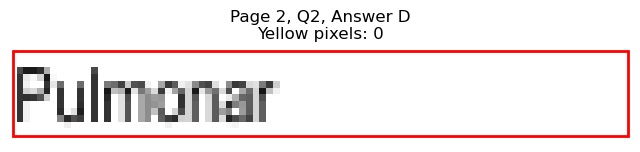


Page 2, Q2 - Selected Answer: B (based on yellow pixel count)




Page 2, Q3 - A: Detected box: x0=68.3, y0=215.7, x1=174.6, y1=228.3
Page 2, Q3, A: Yellow pixels: 0
Page 2, Q3, A: Total non-white pixels: 511
Page 2, Q3, A: Yellow percentage: 0.0%


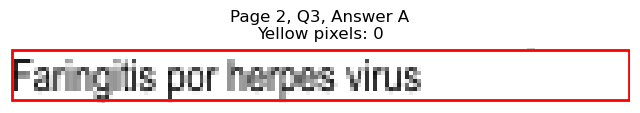

Page 2, Q3 - B: Detected box: x0=68.3, y0=228.3, x1=117.5, y1=240.9
Page 2, Q3, B: Yellow pixels: 0
Page 2, Q3, B: Total non-white pixels: 274
Page 2, Q3, B: Yellow percentage: 0.0%


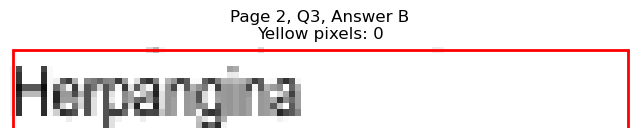

Page 2, Q3 - C: Detected box: x0=327.5, y0=215.7, x1=427.4, y1=228.3
Page 2, Q3, C: Yellow pixels: 1391
Page 2, Q3, C: Total non-white pixels: 2114
Page 2, Q3, C: Yellow percentage: 65.8%


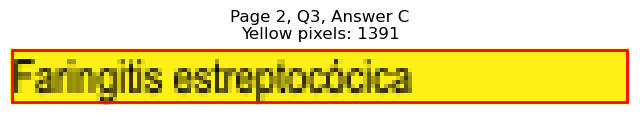

Page 2, Q3 - D: Detected box: x0=327.5, y0=228.3, x1=432.9, y1=240.9
Page 2, Q3, D: Yellow pixels: 0
Page 2, Q3, D: Total non-white pixels: 698
Page 2, Q3, D: Yellow percentage: 0.0%


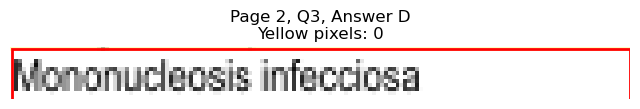


Page 2, Q3 - Selected Answer: C (based on yellow pixel count)




Page 2, Q4 - A: Detected box: x0=68.3, y0=278.8, x1=262.4, y1=291.5
Page 2, Q4, A: Yellow pixels: 0
Page 2, Q4, A: Total non-white pixels: 984
Page 2, Q4, A: Yellow percentage: 0.0%


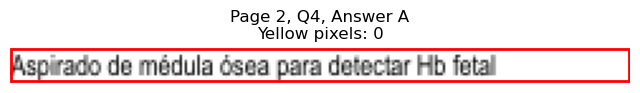

Page 2, Q4 - B: Detected box: x0=68.3, y0=291.4, x1=310.0, y1=304.1
Page 2, Q4, B: Yellow pixels: 0
Page 2, Q4, B: Total non-white pixels: 1145
Page 2, Q4, B: Yellow percentage: 0.0%


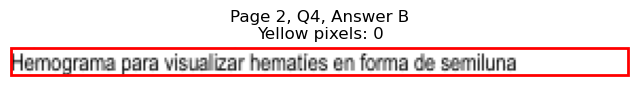

Page 2, Q4 - C: Detected box: x0=68.8, y0=304.0, x1=343.6, y1=316.7
Page 2, Q4, C: Yellow pixels: 1
Page 2, Q4, C: Total non-white pixels: 1692
Page 2, Q4, C: Yellow percentage: 0.1%


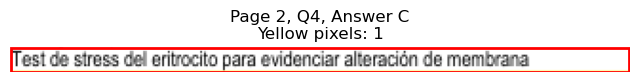

Page 2, Q4 - D: Detected box: x0=68.8, y0=316.6, x1=270.9, y1=329.3
Page 2, Q4, D: Yellow pixels: 2249
Page 2, Q4, D: Total non-white pixels: 3542
Page 2, Q4, D: Yellow percentage: 63.5%


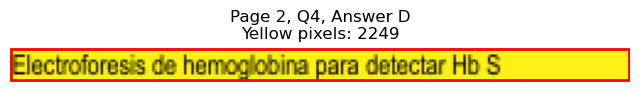


Page 2, Q4 - Selected Answer: D (based on yellow pixel count)




Page 2, Q5 - A: Detected box: x0=68.3, y0=354.5, x1=355.6, y1=367.2
Page 2, Q5, A: Yellow pixels: 338
Page 2, Q5, A: Total non-white pixels: 1686
Page 2, Q5, A: Yellow percentage: 20.0%


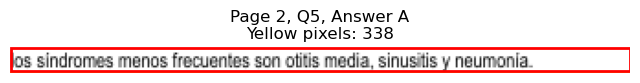

Page 2, Q5 - B: Detected box: x0=68.3, y0=367.1, x1=448.9, y1=379.8
Page 2, Q5, B: Yellow pixels: 4164
Page 2, Q5, B: Total non-white pixels: 5603
Page 2, Q5, B: Yellow percentage: 74.3%


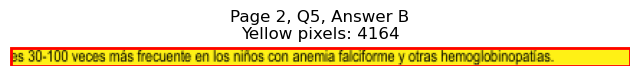

Page 2, Q5 - C: Detected box: x0=68.8, y0=379.7, x1=428.8, y1=392.4
Page 2, Q5, C: Yellow pixels: 410
Page 2, Q5, C: Total non-white pixels: 2080
Page 2, Q5, C: Yellow percentage: 19.7%


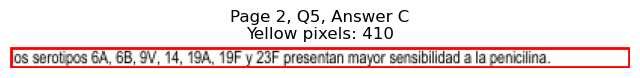

Page 2, Q5 - D: Detected box: x0=68.8, y0=392.3, x1=379.7, y1=405.0
Page 2, Q5, D: Yellow pixels: 0
Page 2, Q5, D: Total non-white pixels: 1541
Page 2, Q5, D: Yellow percentage: 0.0%


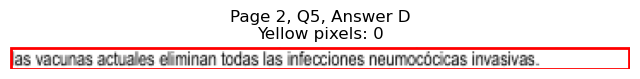


Page 2, Q5 - Selected Answer: B (based on yellow pixel count)




Page 2, Q6 - A: Detected box: x0=68.3, y0=442.8, x1=167.1, y1=455.5
Page 2, Q6, A: Yellow pixels: 0
Page 2, Q6, A: Total non-white pixels: 496
Page 2, Q6, A: Yellow percentage: 0.0%


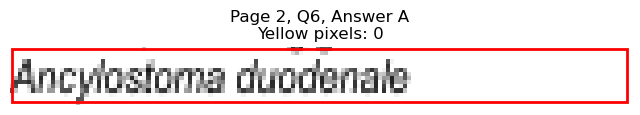

Page 2, Q6 - B: Detected box: x0=68.3, y0=455.5, x1=147.0, y1=468.1
Page 2, Q6, B: Yellow pixels: 0
Page 2, Q6, B: Total non-white pixels: 391
Page 2, Q6, B: Yellow percentage: 0.0%


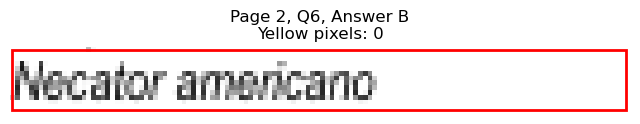

Page 2, Q6 - C: Detected box: x0=327.5, y0=442.8, x1=391.3, y1=455.5
Page 2, Q6, C: Yellow pixels: 1269
Page 2, Q6, C: Total non-white pixels: 1610
Page 2, Q6, C: Yellow percentage: 78.8%


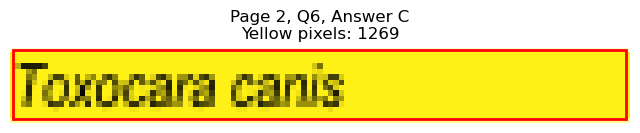

Page 2, Q6 - D: Detected box: x0=327.5, y0=455.5, x1=428.3, y1=468.1
Page 2, Q6, D: Yellow pixels: 0
Page 2, Q6, D: Total non-white pixels: 533
Page 2, Q6, D: Yellow percentage: 0.0%


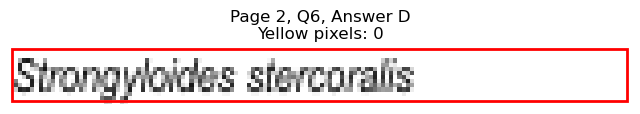


Page 2, Q6 - Selected Answer: C (based on yellow pixel count)




Page 2, Q7 - A: Detected box: x0=68.3, y0=531.2, x1=174.1, y1=543.8
Page 2, Q7, A: Yellow pixels: 0
Page 2, Q7, A: Total non-white pixels: 674
Page 2, Q7, A: Yellow percentage: 0.0%


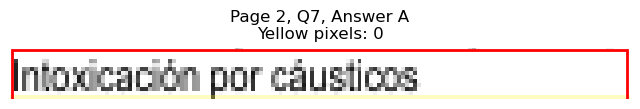

Page 2, Q7 - B: Detected box: x0=68.3, y0=543.8, x1=213.8, y1=556.4
Page 2, Q7, B: Yellow pixels: 1993
Page 2, Q7, B: Total non-white pixels: 2744
Page 2, Q7, B: Yellow percentage: 72.6%


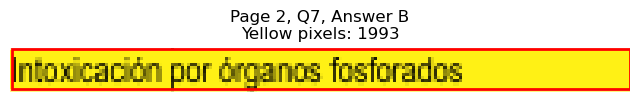

Page 2, Q7 - C: Detected box: x0=327.5, y0=531.2, x1=427.9, y1=543.8
Page 2, Q7, C: Yellow pixels: 0
Page 2, Q7, C: Total non-white pixels: 511
Page 2, Q7, C: Yellow percentage: 0.0%


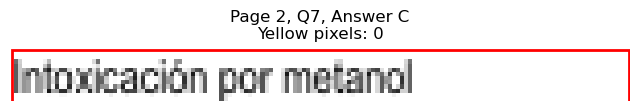

Page 2, Q7 - D: Detected box: x0=327.5, y0=543.8, x1=444.9, y1=556.4
Page 2, Q7, D: Yellow pixels: 0
Page 2, Q7, D: Total non-white pixels: 556
Page 2, Q7, D: Yellow percentage: 0.0%


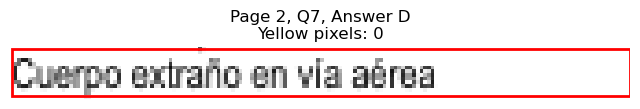


Page 2, Q7 - Selected Answer: B (based on yellow pixel count)




Page 2, Q8 - A: Detected box: x0=68.3, y0=606.9, x1=202.8, y1=619.6
Page 2, Q8, A: Yellow pixels: 0
Page 2, Q8, A: Total non-white pixels: 705
Page 2, Q8, A: Yellow percentage: 0.0%


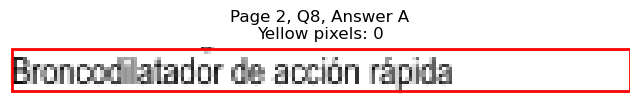

Page 2, Q8 - B: Detected box: x0=68.3, y0=619.6, x1=300.9, y1=632.3
Page 2, Q8, B: Yellow pixels: 0
Page 2, Q8, B: Total non-white pixels: 1156
Page 2, Q8, B: Yellow percentage: 0.0%


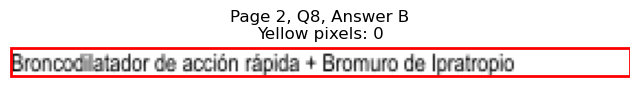

Page 2, Q8 - C: Detected box: x0=68.8, y0=632.2, x1=159.0, y1=644.9
Page 2, Q8, C: Yellow pixels: 0
Page 2, Q8, C: Total non-white pixels: 582
Page 2, Q8, C: Yellow percentage: 0.0%


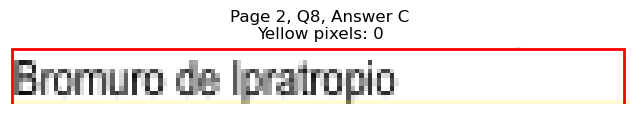

Page 2, Q8 - D: Detected box: x0=68.8, y0=644.9, x1=292.2, y1=657.5
Page 2, Q8, D: Yellow pixels: 2729
Page 2, Q8, D: Total non-white pixels: 3850
Page 2, Q8, D: Yellow percentage: 70.9%


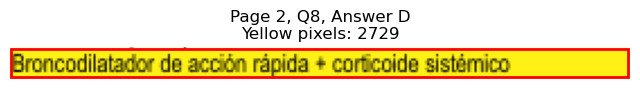


Page 2, Q8 - Selected Answer: D (based on yellow pixel count)




Page 2, Q9 - A: Detected box: x0=68.3, y0=695.4, x1=155.1, y1=708.0
Page 2, Q9, A: Yellow pixels: 1474
Page 2, Q9, A: Total non-white pixels: 1797
Page 2, Q9, A: Yellow percentage: 82.0%


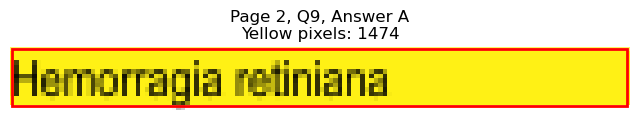

Page 2, Q9 - B: Detected box: x0=68.3, y0=708.0, x1=159.6, y1=720.6
Page 2, Q9, B: Yellow pixels: 138
Page 2, Q9, B: Total non-white pixels: 599
Page 2, Q9, B: Yellow percentage: 23.0%


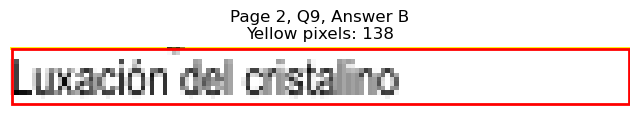

Page 2, Q9 - C: Detected box: x0=327.5, y0=695.4, x1=435.9, y1=708.0
Page 2, Q9, C: Yellow pixels: 0
Page 2, Q9, C: Total non-white pixels: 547
Page 2, Q9, C: Yellow percentage: 0.0%


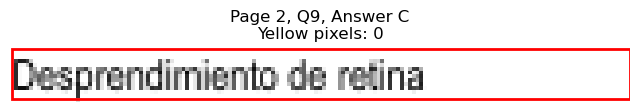

Page 2, Q9 - D: Detected box: x0=327.5, y0=708.0, x1=413.8, y1=720.6
Page 2, Q9, D: Yellow pixels: 0
Page 2, Q9, D: Total non-white pixels: 453
Page 2, Q9, D: Yellow percentage: 0.0%


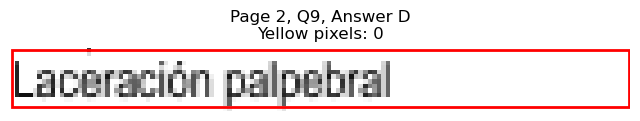


Page 2, Q9 - Selected Answer: A (based on yellow pixel count)





Page 3: Found 10 questions
Page 3, Q1 - A: Detected box: x0=68.3, y0=102.0, x1=116.9, y1=114.7
Page 3, Q1, A: Yellow pixels: 0
Page 3, Q1, A: Total non-white pixels: 236
Page 3, Q1, A: Yellow percentage: 0.0%


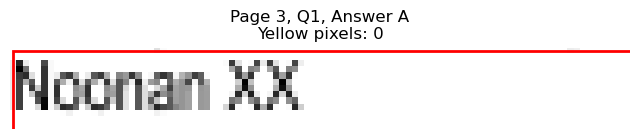

Page 3, Q1 - B: Detected box: x0=68.3, y0=114.6, x1=112.0, y1=127.3
Page 3, Q1, B: Yellow pixels: 0
Page 3, Q1, B: Total non-white pixels: 192
Page 3, Q1, B: Yellow percentage: 0.0%


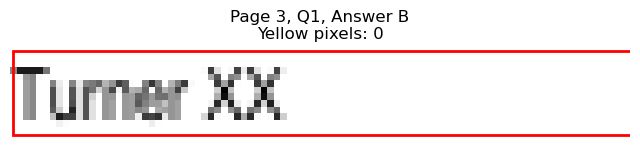

Page 3, Q1 - C: Detected box: x0=327.5, y0=102.0, x1=412.3, y1=114.7
Page 3, Q1, C: Yellow pixels: 2
Page 3, Q1, C: Total non-white pixels: 573
Page 3, Q1, C: Yellow percentage: 0.3%


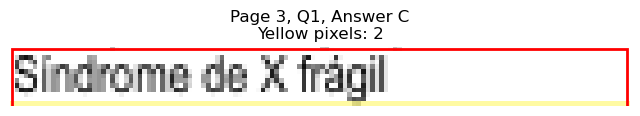

Page 3, Q1 - D: Detected box: x0=327.5, y0=114.6, x1=372.2, y1=127.3
Page 3, Q1, D: Yellow pixels: 988
Page 3, Q1, D: Total non-white pixels: 1344
Page 3, Q1, D: Yellow percentage: 73.5%


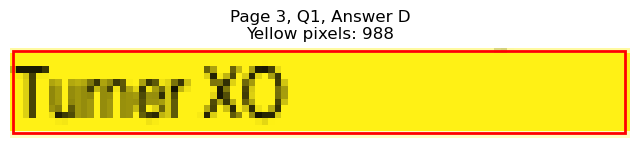


Page 3, Q1 - Selected Answer: D (based on yellow pixel count)




Page 3, Q2 - A: Detected box: x0=68.3, y0=190.3, x1=226.2, y1=203.0
Page 3, Q2, A: Yellow pixels: 2088
Page 3, Q2, A: Total non-white pixels: 2717
Page 3, Q2, A: Yellow percentage: 76.8%


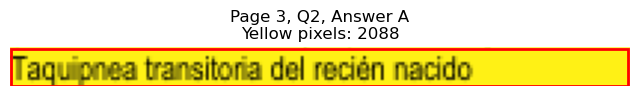

Page 3, Q2 - B: Detected box: x0=68.3, y0=202.9, x1=149.5, y1=215.6
Page 3, Q2, B: Yellow pixels: 129
Page 3, Q2, B: Total non-white pixels: 531
Page 3, Q2, B: Yellow percentage: 24.3%


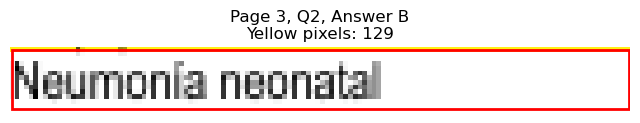

Page 3, Q2 - C: Detected box: x0=327.5, y0=190.3, x1=465.9, y1=203.0
Page 3, Q2, C: Yellow pixels: 0
Page 3, Q2, C: Total non-white pixels: 670
Page 3, Q2, C: Yellow percentage: 0.0%


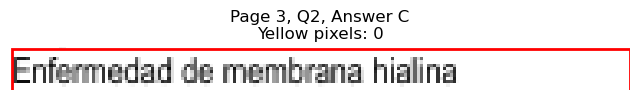

Page 3, Q2 - D: Detected box: x0=327.5, y0=202.9, x1=467.5, y1=215.6
Page 3, Q2, D: Yellow pixels: 0
Page 3, Q2, D: Total non-white pixels: 734
Page 3, Q2, D: Yellow percentage: 0.0%


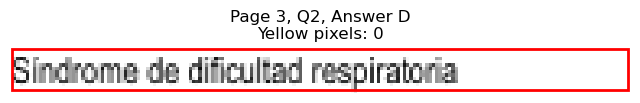


Page 3, Q2 - Selected Answer: A (based on yellow pixel count)




Page 3, Q3 - A: Detected box: x0=68.3, y0=266.1, x1=182.7, y1=278.7
Page 3, Q3, A: Yellow pixels: 0
Page 3, Q3, A: Total non-white pixels: 558
Page 3, Q3, A: Yellow percentage: 0.0%


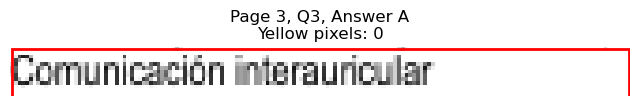

Page 3, Q3 - B: Detected box: x0=68.3, y0=278.8, x1=209.3, y1=291.5
Page 3, Q3, B: Yellow pixels: 1930
Page 3, Q3, B: Total non-white pixels: 2688
Page 3, Q3, B: Yellow percentage: 71.8%


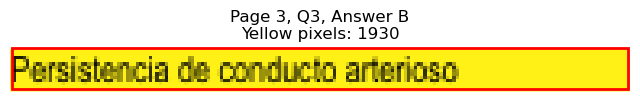

Page 3, Q3 - C: Detected box: x0=327.5, y0=266.1, x1=448.9, y1=278.7
Page 3, Q3, C: Yellow pixels: 0
Page 3, Q3, C: Total non-white pixels: 591
Page 3, Q3, C: Yellow percentage: 0.0%


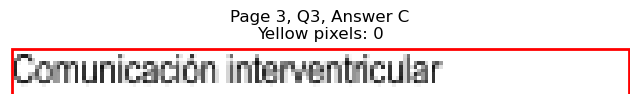

Page 3, Q3 - D: Detected box: x0=327.5, y0=278.8, x1=471.0, y1=291.5
Page 3, Q3, D: Yellow pixels: 0
Page 3, Q3, D: Total non-white pixels: 681
Page 3, Q3, D: Yellow percentage: 0.0%


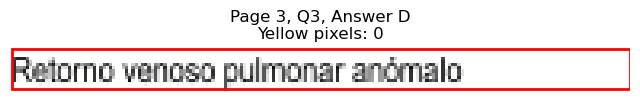


Page 3, Q3 - Selected Answer: B (based on yellow pixel count)




Page 3, Q4 - A: Detected box: x0=68.3, y0=341.9, x1=151.1, y1=354.6
Page 3, Q4, A: Yellow pixels: 134
Page 3, Q4, A: Total non-white pixels: 580
Page 3, Q4, A: Yellow percentage: 23.1%


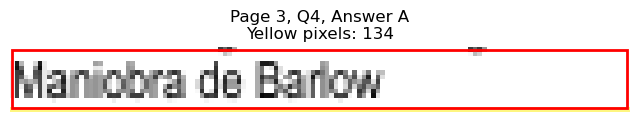

Page 3, Q4 - B: Detected box: x0=68.3, y0=354.5, x1=177.1, y1=367.2
Page 3, Q4, B: Yellow pixels: 1676
Page 3, Q4, B: Total non-white pixels: 2240
Page 3, Q4, B: Yellow percentage: 74.8%


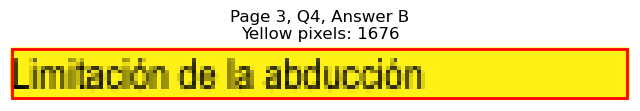

Page 3, Q4 - C: Detected box: x0=327.5, y0=341.9, x1=414.3, y1=354.6
Page 3, Q4, C: Yellow pixels: 0
Page 3, Q4, C: Total non-white pixels: 443
Page 3, Q4, C: Yellow percentage: 0.0%


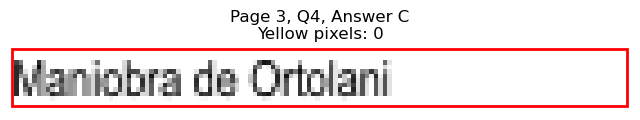

Page 3, Q4 - D: Detected box: x0=327.5, y0=354.5, x1=448.4, y1=367.2
Page 3, Q4, D: Yellow pixels: 0
Page 3, Q4, D: Total non-white pixels: 651
Page 3, Q4, D: Yellow percentage: 0.0%


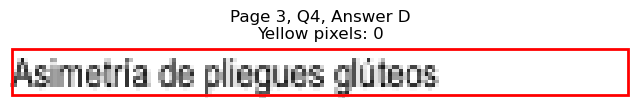


Page 3, Q4 - Selected Answer: B (based on yellow pixel count)




Page 3, Q5 - A: Detected box: x0=68.3, y0=417.6, x1=123.5, y1=430.3
Page 3, Q5, A: Yellow pixels: 0
Page 3, Q5, A: Total non-white pixels: 297
Page 3, Q5, A: Yellow percentage: 0.0%


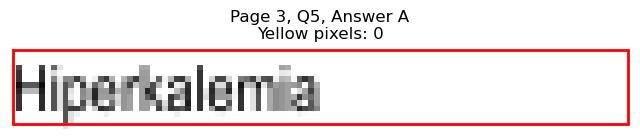

Page 3, Q5 - B: Detected box: x0=68.3, y0=430.2, x1=123.5, y1=442.9
Page 3, Q5, B: Yellow pixels: 0
Page 3, Q5, B: Total non-white pixels: 285
Page 3, Q5, B: Yellow percentage: 0.0%


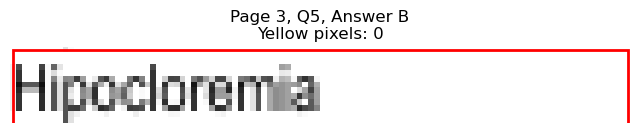

Page 3, Q5 - C: Detected box: x0=327.5, y0=417.6, x1=400.3, y1=430.3
Page 3, Q5, C: Yellow pixels: 124
Page 3, Q5, C: Total non-white pixels: 516
Page 3, Q5, C: Yellow percentage: 24.0%


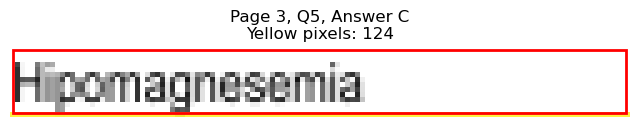

Page 3, Q5 - D: Detected box: x0=327.5, y0=430.2, x1=383.7, y1=442.9
Page 3, Q5, D: Yellow pixels: 1151
Page 3, Q5, D: Total non-white pixels: 1391
Page 3, Q5, D: Yellow percentage: 82.7%


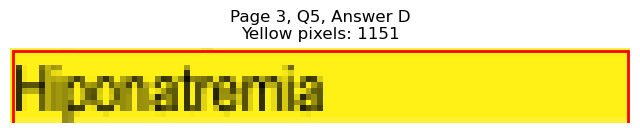


Page 3, Q5 - Selected Answer: D (based on yellow pixel count)




Page 3, Q6 - A: Detected box: x0=68.3, y0=480.8, x1=233.3, y1=493.4
Page 3, Q6, A: Yellow pixels: 213
Page 3, Q6, A: Total non-white pixels: 1023
Page 3, Q6, A: Yellow percentage: 20.8%


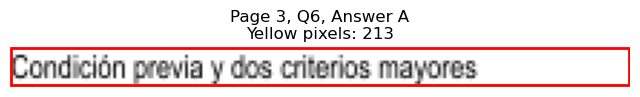

Page 3, Q6 - B: Detected box: x0=68.3, y0=493.4, x1=282.4, y1=506.0
Page 3, Q6, B: Yellow pixels: 1983
Page 3, Q6, B: Total non-white pixels: 2856
Page 3, Q6, B: Yellow percentage: 69.4%


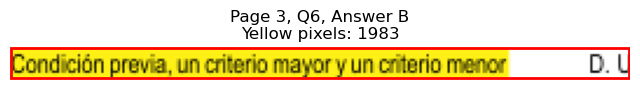

Page 3, Q6 - C: Detected box: x0=327.5, y0=480.8, x1=493.1, y1=493.4
Page 3, Q6, C: Yellow pixels: 0
Page 3, Q6, C: Total non-white pixels: 835
Page 3, Q6, C: Yellow percentage: 0.0%


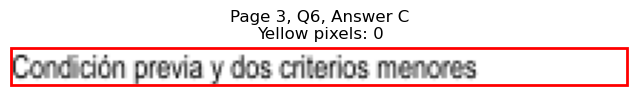

Page 3, Q6 - D: Detected box: x0=327.5, y0=493.4, x1=476.0, y1=506.0
Page 3, Q6, D: Yellow pixels: 0
Page 3, Q6, D: Total non-white pixels: 691
Page 3, Q6, D: Yellow percentage: 0.0%


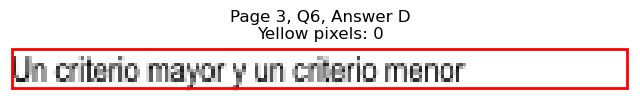


Page 3, Q6 - Selected Answer: B (based on yellow pixel count)




Page 3, Q7 - A: Detected box: x0=68.3, y0=531.2, x1=306.0, y1=543.8
Page 3, Q7, A: Yellow pixels: 0
Page 3, Q7, A: Total non-white pixels: 1502
Page 3, Q7, A: Yellow percentage: 0.0%


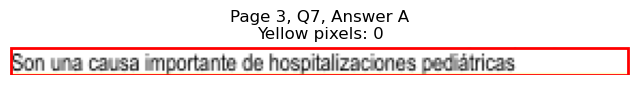

Page 3, Q7 - B: Detected box: x0=68.3, y0=543.8, x1=283.5, y1=556.4
Page 3, Q7, B: Yellow pixels: 2622
Page 3, Q7, B: Total non-white pixels: 3724
Page 3, Q7, B: Yellow percentage: 70.4%


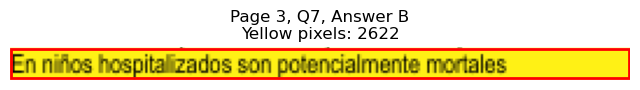

Page 3, Q7 - C: Detected box: x0=68.8, y0=556.5, x1=253.8, y1=569.2
Page 3, Q7, C: Yellow pixels: 236
Page 3, Q7, C: Total non-white pixels: 1124
Page 3, Q7, C: Yellow percentage: 21.0%


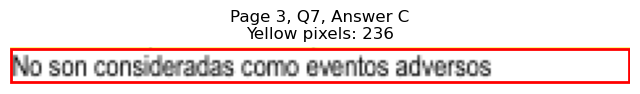

Page 3, Q7 - D: Detected box: x0=68.8, y0=569.1, x1=255.4, y1=581.8
Page 3, Q7, D: Yellow pixels: 0
Page 3, Q7, D: Total non-white pixels: 907
Page 3, Q7, D: Yellow percentage: 0.0%


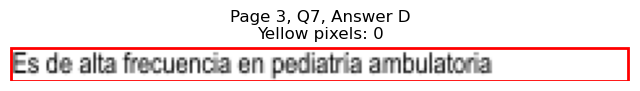


Page 3, Q7 - Selected Answer: B (based on yellow pixel count)




Page 3, Q8 - A: Detected box: x0=68.3, y0=619.6, x1=211.7, y1=632.3
Page 3, Q8, A: Yellow pixels: 194
Page 3, Q8, A: Total non-white pixels: 899
Page 3, Q8, A: Yellow percentage: 21.6%


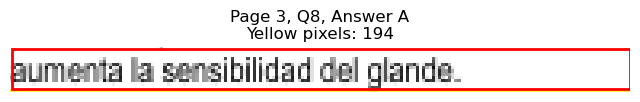

Page 3, Q8 - B: Detected box: x0=68.3, y0=632.2, x1=182.2, y1=644.9
Page 3, Q8, B: Yellow pixels: 1713
Page 3, Q8, B: Total non-white pixels: 2145
Page 3, Q8, B: Yellow percentage: 79.9%


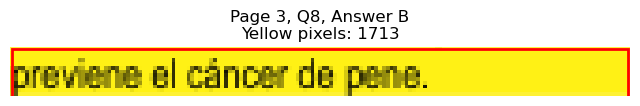

Page 3, Q8 - C: Detected box: x0=327.5, y0=619.6, x1=439.4, y1=632.3
Page 3, Q8, C: Yellow pixels: 0
Page 3, Q8, C: Total non-white pixels: 537
Page 3, Q8, C: Yellow percentage: 0.0%


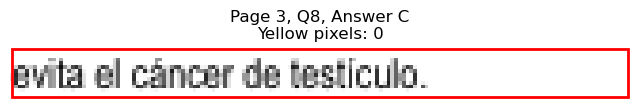

Page 3, Q8 - D: Detected box: x0=327.5, y0=632.2, x1=421.4, y1=644.9
Page 3, Q8, D: Yellow pixels: 0
Page 3, Q8, D: Total non-white pixels: 486
Page 3, Q8, D: Yellow percentage: 0.0%


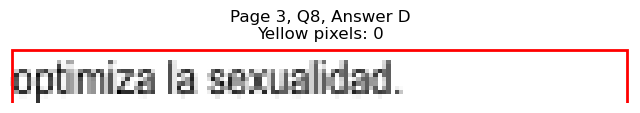


Page 3, Q8 - Selected Answer: B (based on yellow pixel count)




Page 3, Q9 - A: Detected box: x0=68.3, y0=682.7, x1=137.1, y1=695.3
Page 3, Q9, A: Yellow pixels: 1190
Page 3, Q9, A: Total non-white pixels: 1680
Page 3, Q9, A: Yellow percentage: 70.8%


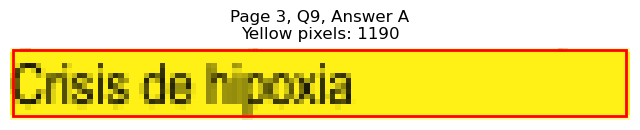

Page 3, Q9 - B: Detected box: x0=68.3, y0=695.4, x1=153.6, y1=708.0
Page 3, Q9, B: Yellow pixels: 1
Page 3, Q9, B: Total non-white pixels: 548
Page 3, Q9, B: Yellow percentage: 0.2%


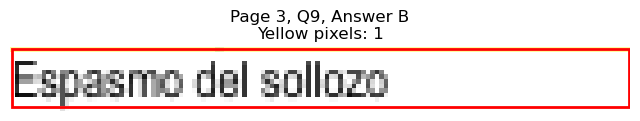

Page 3, Q9 - C: Detected box: x0=327.5, y0=682.7, x1=416.3, y1=695.3
Page 3, Q9, C: Yellow pixels: 0
Page 3, Q9, C: Total non-white pixels: 467
Page 3, Q9, C: Yellow percentage: 0.0%


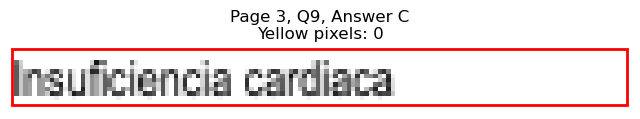

Page 3, Q9 - D: Detected box: x0=327.5, y0=695.4, x1=374.7, y1=708.0
Page 3, Q9, D: Yellow pixels: 0
Page 3, Q9, D: Total non-white pixels: 252
Page 3, Q9, D: Yellow percentage: 0.0%


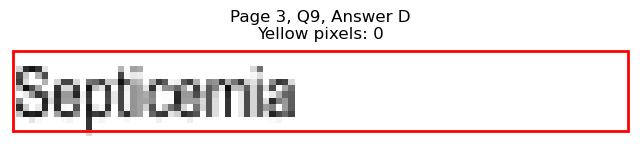


Page 3, Q9 - Selected Answer: A (based on yellow pixel count)




Page 3, Q10 - A: Detected box: x0=68.3, y0=745.8, x1=157.6, y1=758.4
Page 3, Q10, A: Yellow pixels: 0
Page 3, Q10, A: Total non-white pixels: 442
Page 3, Q10, A: Yellow percentage: 0.0%


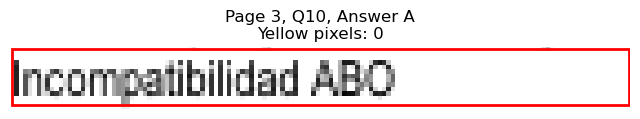

Page 3, Q10 - B: Detected box: x0=68.3, y0=758.5, x1=177.1, y1=771.2
Page 3, Q10, B: Yellow pixels: 0
Page 3, Q10, B: Total non-white pixels: 511
Page 3, Q10, B: Yellow percentage: 0.0%


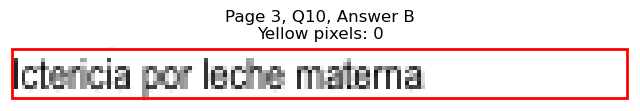

Page 3, Q10 - C: Detected box: x0=327.5, y0=745.8, x1=485.0, y1=758.4
Page 3, Q10, C: Yellow pixels: 2099
Page 3, Q10, C: Total non-white pixels: 2926
Page 3, Q10, C: Yellow percentage: 71.7%


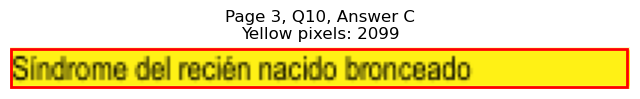

Page 3, Q10 - D: Detected box: x0=327.5, y0=758.5, x1=434.9, y1=771.2
Page 3, Q10, D: Yellow pixels: 158
Page 3, Q10, D: Total non-white pixels: 732
Page 3, Q10, D: Yellow percentage: 21.6%


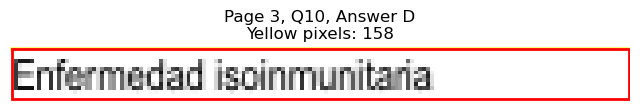


Page 3, Q10 - Selected Answer: C (based on yellow pixel count)





Page 4: Found 9 questions
Page 4, Q1 - A: Detected box: x0=68.3, y0=102.0, x1=177.1, y1=114.7
Page 4, Q1, A: Yellow pixels: 0
Page 4, Q1, A: Total non-white pixels: 506
Page 4, Q1, A: Yellow percentage: 0.0%


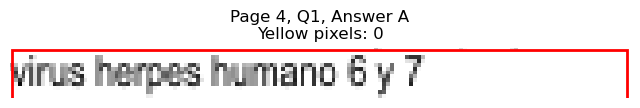

Page 4, Q1 - B: Detected box: x0=68.3, y0=114.6, x1=155.1, y1=127.3
Page 4, Q1, B: Yellow pixels: 0
Page 4, Q1, B: Total non-white pixels: 421
Page 4, Q1, B: Yellow percentage: 0.0%


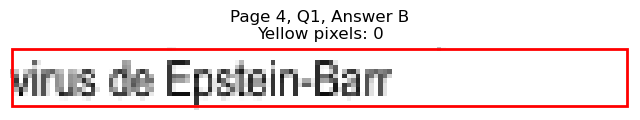

Page 4, Q1 - C: Detected box: x0=327.5, y0=102.0, x1=390.2, y1=114.7
Page 4, Q1, C: Yellow pixels: 1259
Page 4, Q1, C: Total non-white pixels: 1482
Page 4, Q1, C: Yellow percentage: 85.0%


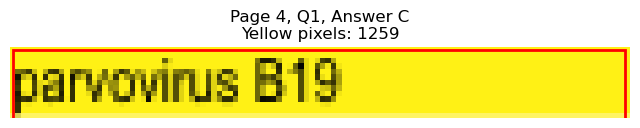

Page 4, Q1 - D: Detected box: x0=327.5, y0=114.6, x1=392.7, y1=127.3
Page 4, Q1, D: Yellow pixels: 116
Page 4, Q1, D: Total non-white pixels: 464
Page 4, Q1, D: Yellow percentage: 25.0%


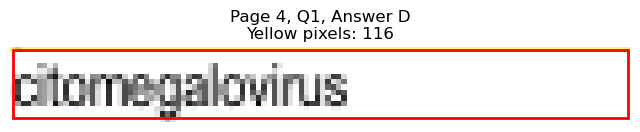


Page 4, Q1 - Selected Answer: C (based on yellow pixel count)




Page 4, Q2 - A: Detected box: x0=68.3, y0=165.1, x1=100.5, y1=177.8
Page 4, Q2, A: Yellow pixels: 973
Page 4, Q2, A: Total non-white pixels: 1079
Page 4, Q2, A: Yellow percentage: 90.2%


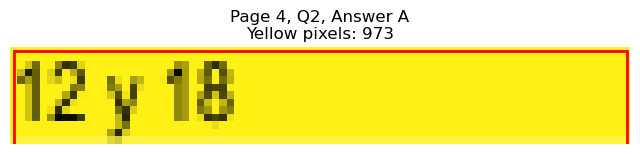

Page 4, Q2 - B: Detected box: x0=68.3, y0=177.7, x1=100.5, y1=190.4
Page 4, Q2, B: Yellow pixels: 83
Page 4, Q2, B: Total non-white pixels: 205
Page 4, Q2, B: Yellow percentage: 40.5%


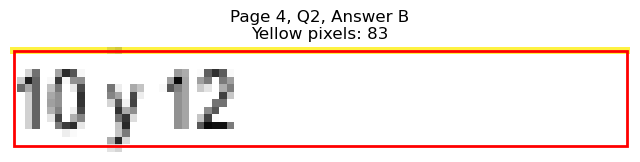

Page 4, Q2 - C: Detected box: x0=327.5, y0=165.1, x1=359.7, y1=177.8
Page 4, Q2, C: Yellow pixels: 0
Page 4, Q2, C: Total non-white pixels: 116
Page 4, Q2, C: Yellow percentage: 0.0%


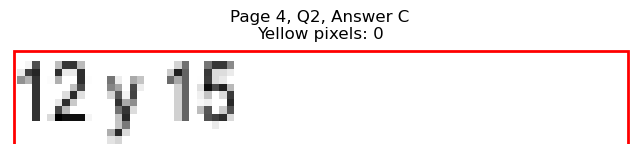

Page 4, Q2 - D: Detected box: x0=327.5, y0=177.7, x1=354.7, y1=190.4
Page 4, Q2, D: Yellow pixels: 0
Page 4, Q2, D: Total non-white pixels: 111
Page 4, Q2, D: Yellow percentage: 0.0%


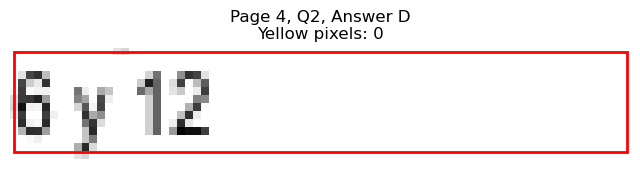


Page 4, Q2 - Selected Answer: A (based on yellow pixel count)




Page 4, Q3 - A: Detected box: x0=68.3, y0=240.9, x1=313.0, y1=253.5
Page 4, Q3, A: Yellow pixels: 0
Page 4, Q3, A: Total non-white pixels: 1267
Page 4, Q3, A: Yellow percentage: 0.0%


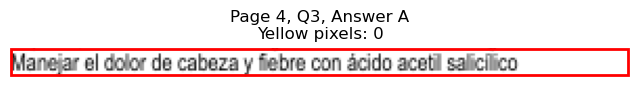

Page 4, Q3 - B: Detected box: x0=68.3, y0=253.5, x1=363.2, y1=266.1
Page 4, Q3, B: Yellow pixels: 346
Page 4, Q3, B: Total non-white pixels: 1782
Page 4, Q3, B: Yellow percentage: 19.4%


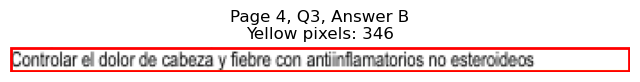

Page 4, Q3 - C: Detected box: x0=68.8, y0=266.1, x1=439.9, y1=278.7
Page 4, Q3, C: Yellow pixels: 4000
Page 4, Q3, C: Total non-white pixels: 5486
Page 4, Q3, C: Yellow percentage: 72.9%


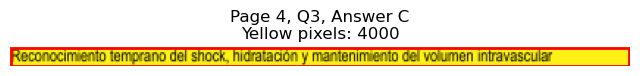

Page 4, Q3 - D: Detected box: x0=68.8, y0=278.8, x1=292.0, y1=291.5
Page 4, Q3, D: Yellow pixels: 274
Page 4, Q3, D: Total non-white pixels: 1411
Page 4, Q3, D: Yellow percentage: 19.4%


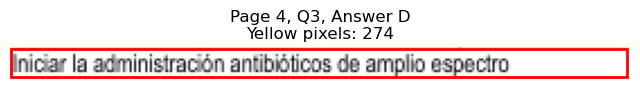


Page 4, Q3 - Selected Answer: C (based on yellow pixel count)




Page 4, Q4 - A: Detected box: x0=68.3, y0=354.5, x1=130.9, y1=367.2
Page 4, Q4, A: Yellow pixels: 113
Page 4, Q4, A: Total non-white pixels: 421
Page 4, Q4, A: Yellow percentage: 26.8%


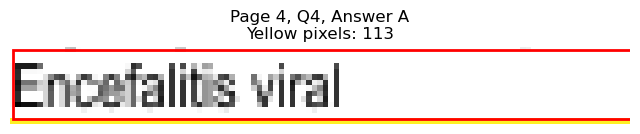

Page 4, Q4 - B: Detected box: x0=68.3, y0=367.1, x1=156.0, y1=379.8
Page 4, Q4, B: Yellow pixels: 1444
Page 4, Q4, B: Total non-white pixels: 1807
Page 4, Q4, B: Yellow percentage: 79.9%


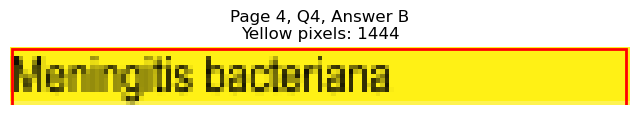

Page 4, Q4 - C: Detected box: x0=327.5, y0=354.5, x1=419.8, y1=367.2
Page 4, Q4, C: Yellow pixels: 0
Page 4, Q4, C: Total non-white pixels: 502
Page 4, Q4, C: Yellow percentage: 0.0%


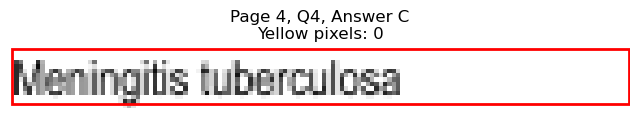

Page 4, Q4 - D: Detected box: x0=327.5, y0=367.1, x1=402.3, y1=379.8
Page 4, Q4, D: Yellow pixels: 0
Page 4, Q4, D: Total non-white pixels: 422
Page 4, Q4, D: Yellow percentage: 0.0%


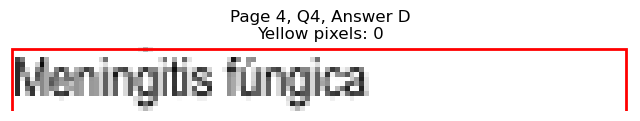


Page 4, Q4 - Selected Answer: B (based on yellow pixel count)




Page 4, Q5 - A: Detected box: x0=68.3, y0=404.9, x1=337.0, y1=417.6
Page 4, Q5, A: Yellow pixels: 3195
Page 4, Q5, A: Total non-white pixels: 4480
Page 4, Q5, A: Yellow percentage: 71.3%


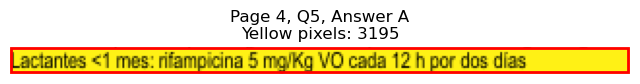

Page 4, Q5 - B: Detected box: x0=68.3, y0=417.6, x1=306.8, y1=430.3
Page 4, Q5, B: Yellow pixels: 286
Page 4, Q5, B: Total non-white pixels: 1417
Page 4, Q5, B: Yellow percentage: 20.2%


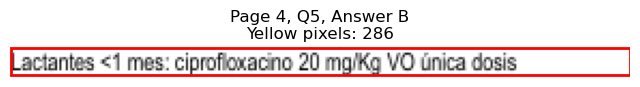

Page 4, Q5 - C: Detected box: x0=68.8, y0=430.2, x1=292.7, y1=442.9
Page 4, Q5, C: Yellow pixels: 0
Page 4, Q5, C: Total non-white pixels: 1080
Page 4, Q5, C: Yellow percentage: 0.0%


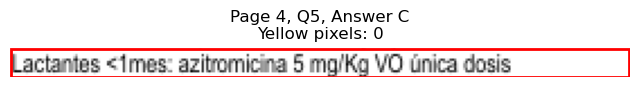

Page 4, Q5 - D: Detected box: x0=68.8, y0=442.8, x1=256.1, y1=455.5
Page 4, Q5, D: Yellow pixels: 0
Page 4, Q5, D: Total non-white pixels: 913
Page 4, Q5, D: Yellow percentage: 0.0%


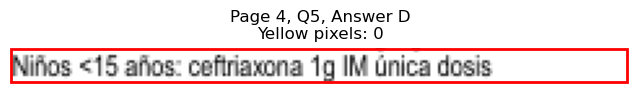


Page 4, Q5 - Selected Answer: A (based on yellow pixel count)




Page 4, Q6 - A: Detected box: x0=68.3, y0=480.8, x1=101.4, y1=493.4
Page 4, Q6, A: Yellow pixels: 0
Page 4, Q6, A: Total non-white pixels: 163
Page 4, Q6, A: Yellow percentage: 0.0%


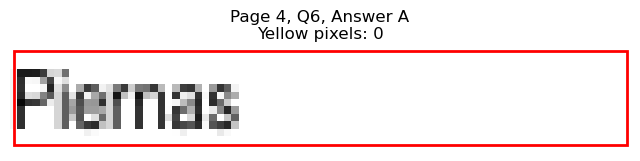

Page 4, Q6 - B: Detected box: x0=68.3, y0=493.4, x1=90.4, y1=506.0
Page 4, Q6, B: Yellow pixels: 0
Page 4, Q6, B: Total non-white pixels: 103
Page 4, Q6, B: Yellow percentage: 0.0%


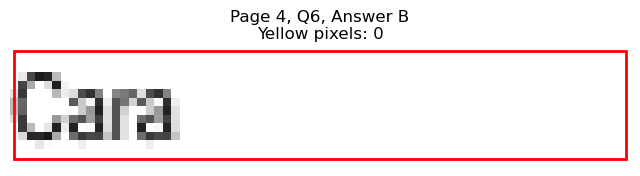

Page 4, Q6 - C: Detected box: x0=327.5, y0=480.8, x1=355.6, y1=493.4
Page 4, Q6, C: Yellow pixels: 79
Page 4, Q6, C: Total non-white pixels: 224
Page 4, Q6, C: Yellow percentage: 35.3%


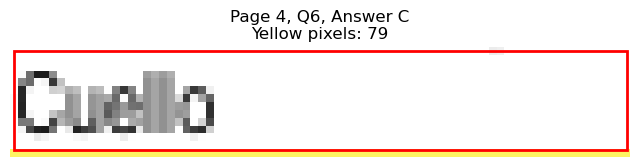

Page 4, Q6 - D: Detected box: x0=327.5, y0=493.4, x1=368.7, y1=506.0
Page 4, Q6, D: Yellow pixels: 1046
Page 4, Q6, D: Total non-white pixels: 1196
Page 4, Q6, D: Yellow percentage: 87.5%


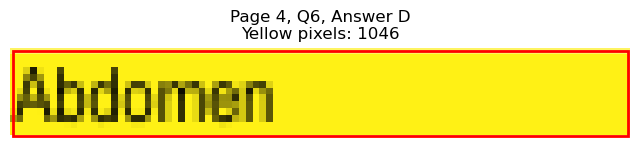


Page 4, Q6 - Selected Answer: D (based on yellow pixel count)




Page 4, Q7 - A: Detected box: x0=68.3, y0=543.8, x1=331.6, y1=556.4
Page 4, Q7, A: Yellow pixels: 3067
Page 4, Q7, A: Total non-white pixels: 4396
Page 4, Q7, A: Yellow percentage: 69.8%


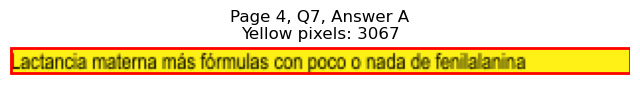

Page 4, Q7 - B: Detected box: x0=68.3, y0=556.5, x1=351.7, y1=569.2
Page 4, Q7, B: Yellow pixels: 334
Page 4, Q7, B: Total non-white pixels: 1716
Page 4, Q7, B: Yellow percentage: 19.5%


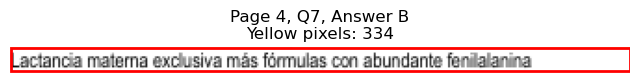

Page 4, Q7 - C: Detected box: x0=68.8, y0=569.1, x1=189.1, y1=581.8
Page 4, Q7, C: Yellow pixels: 0
Page 4, Q7, C: Total non-white pixels: 586
Page 4, Q7, C: Yellow percentage: 0.0%


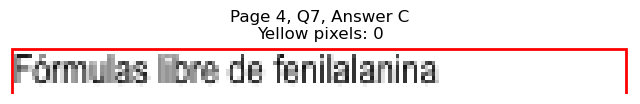

Page 4, Q7 - D: Detected box: x0=68.8, y0=581.7, x1=196.7, y1=594.4
Page 4, Q7, D: Yellow pixels: 0
Page 4, Q7, D: Total non-white pixels: 657
Page 4, Q7, D: Yellow percentage: 0.0%


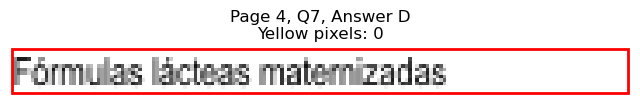


Page 4, Q7 - Selected Answer: A (based on yellow pixel count)




Page 4, Q8 - A: Detected box: x0=68.3, y0=632.2, x1=119.9, y1=644.9
Page 4, Q8, A: Yellow pixels: 0
Page 4, Q8, A: Total non-white pixels: 369
Page 4, Q8, A: Yellow percentage: 0.0%


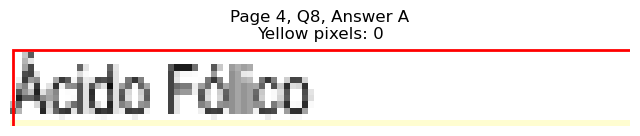

Page 4, Q8 - B: Detected box: x0=68.3, y0=644.9, x1=95.4, y1=657.5
Page 4, Q8, B: Yellow pixels: 921
Page 4, Q8, B: Total non-white pixels: 1092
Page 4, Q8, B: Yellow percentage: 84.3%


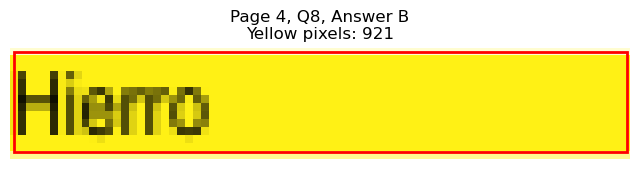

Page 4, Q8 - C: Detected box: x0=327.5, y0=632.2, x1=383.7, y1=644.9
Page 4, Q8, C: Yellow pixels: 0
Page 4, Q8, C: Total non-white pixels: 272
Page 4, Q8, C: Yellow percentage: 0.0%


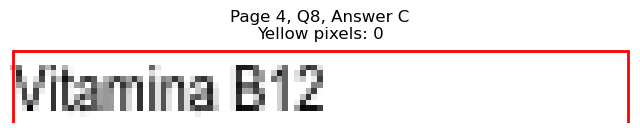

Page 4, Q8 - D: Detected box: x0=327.5, y0=644.9, x1=347.1, y1=657.5
Page 4, Q8, D: Yellow pixels: 0
Page 4, Q8, D: Total non-white pixels: 91
Page 4, Q8, D: Yellow percentage: 0.0%


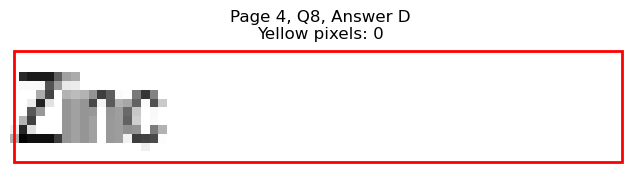


Page 4, Q8 - Selected Answer: B (based on yellow pixel count)




Page 4, Q9 - A: Detected box: x0=68.3, y0=708.0, x1=446.9, y1=720.6
Page 4, Q9, A: Yellow pixels: 429
Page 4, Q9, A: Total non-white pixels: 2325
Page 4, Q9, A: Yellow percentage: 18.5%


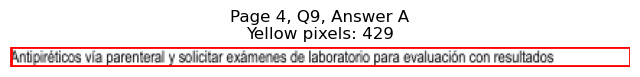

Page 4, Q9 - B: Detected box: x0=68.3, y0=720.6, x1=481.1, y1=733.2
Page 4, Q9, B: Yellow pixels: 4424
Page 4, Q9, B: Total non-white pixels: 6496
Page 4, Q9, B: Yellow percentage: 68.1%


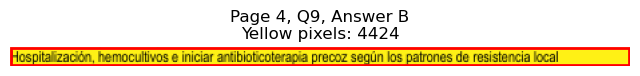

Page 4, Q9 - C: Detected box: x0=68.8, y0=733.2, x1=478.1, y1=745.8
Page 4, Q9, C: Yellow pixels: 0
Page 4, Q9, C: Total non-white pixels: 2532
Page 4, Q9, C: Yellow percentage: 0.0%


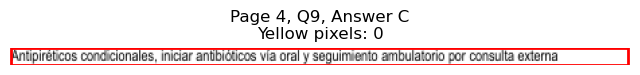

Page 4, Q9 - D: Detected box: x0=68.8, y0=745.8, x1=196.2, y1=758.4
Page 4, Q9, D: Yellow pixels: 0
Page 4, Q9, D: Total non-white pixels: 622
Page 4, Q9, D: Yellow percentage: 0.0%


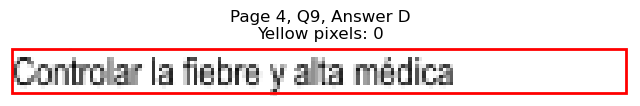


Page 4, Q9 - Selected Answer: B (based on yellow pixel count)





Page 5: Found 9 questions
Page 5, Q1 - A: Detected box: x0=68.3, y0=114.6, x1=253.5, y1=127.3
Page 5, Q1, A: Yellow pixels: 0
Page 5, Q1, A: Total non-white pixels: 950
Page 5, Q1, A: Yellow percentage: 0.0%


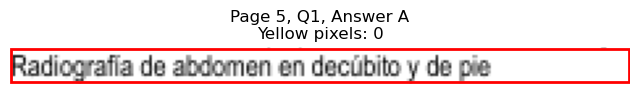

Page 5, Q1 - B: Detected box: x0=68.3, y0=127.2, x1=206.2, y1=139.9
Page 5, Q1, B: Yellow pixels: 0
Page 5, Q1, B: Total non-white pixels: 661
Page 5, Q1, B: Yellow percentage: 0.0%


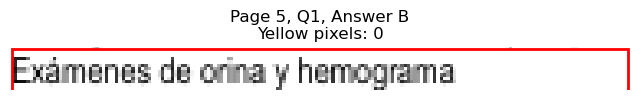

Page 5, Q1 - C: Detected box: x0=68.8, y0=139.9, x1=301.6, y1=152.6
Page 5, Q1, C: Yellow pixels: 284
Page 5, Q1, C: Total non-white pixels: 1453
Page 5, Q1, C: Yellow percentage: 19.5%


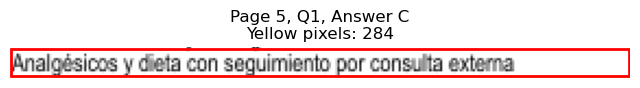

Page 5, Q1 - D: Detected box: x0=68.8, y0=152.5, x1=169.6, y1=165.2
Page 5, Q1, D: Yellow pixels: 1589
Page 5, Q1, D: Total non-white pixels: 2128
Page 5, Q1, D: Yellow percentage: 74.7%


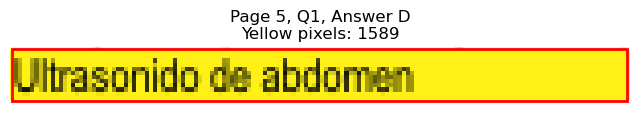


Page 5, Q1 - Selected Answer: D (based on yellow pixel count)




Page 5, Q2 - A: Detected box: x0=68.3, y0=202.9, x1=123.0, y1=215.6
Page 5, Q2, A: Yellow pixels: 0
Page 5, Q2, A: Total non-white pixels: 270
Page 5, Q2, A: Yellow percentage: 0.0%


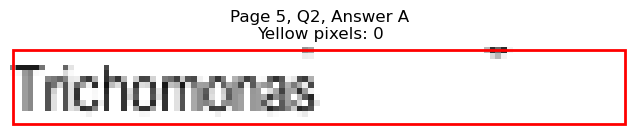

Page 5, Q2 - B: Detected box: x0=68.3, y0=215.7, x1=118.0, y1=228.3
Page 5, Q2, B: Yellow pixels: 0
Page 5, Q2, B: Total non-white pixels: 229
Page 5, Q2, B: Yellow percentage: 0.0%


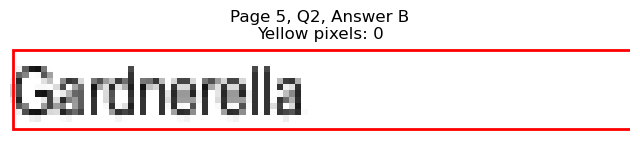

Page 5, Q2 - C: Detected box: x0=327.5, y0=202.9, x1=372.7, y1=215.6
Page 5, Q2, C: Yellow pixels: 0
Page 5, Q2, C: Total non-white pixels: 239
Page 5, Q2, C: Yellow percentage: 0.0%


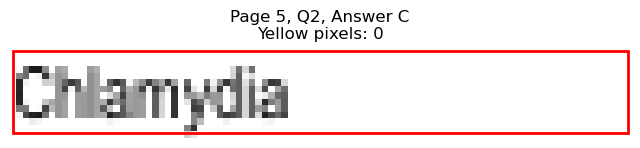

Page 5, Q2 - D: Detected box: x0=327.5, y0=215.7, x1=363.7, y1=228.3
Page 5, Q2, D: Yellow pixels: 887
Page 5, Q2, D: Total non-white pixels: 1218
Page 5, Q2, D: Yellow percentage: 72.8%


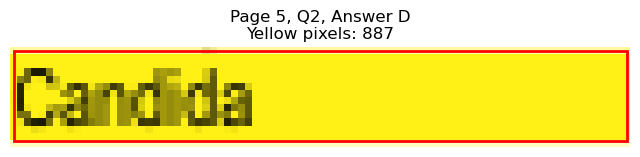


Page 5, Q2 - Selected Answer: D (based on yellow pixel count)




Page 5, Q3 - A: Detected box: x0=68.3, y0=278.8, x1=173.7, y1=291.5
Page 5, Q3, A: Yellow pixels: 0
Page 5, Q3, A: Total non-white pixels: 562
Page 5, Q3, A: Yellow percentage: 0.0%


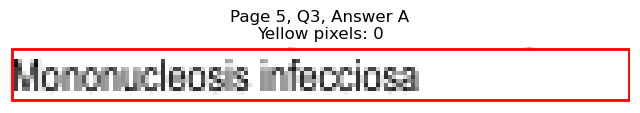

Page 5, Q3 - B: Detected box: x0=68.3, y0=291.4, x1=102.4, y1=304.1
Page 5, Q3, B: Yellow pixels: 0
Page 5, Q3, B: Total non-white pixels: 180
Page 5, Q3, B: Yellow percentage: 0.0%


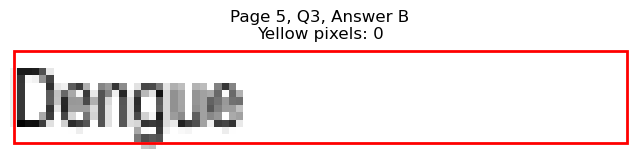

Page 5, Q3 - C: Detected box: x0=327.5, y0=278.8, x1=374.7, y1=291.5
Page 5, Q3, C: Yellow pixels: 98
Page 5, Q3, C: Total non-white pixels: 350
Page 5, Q3, C: Yellow percentage: 28.0%


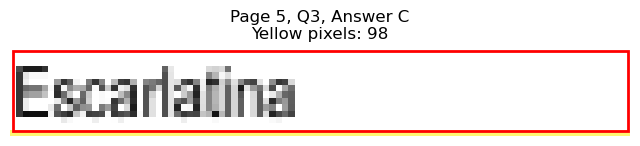

Page 5, Q3 - D: Detected box: x0=327.5, y0=291.4, x1=462.9, y1=304.1
Page 5, Q3, D: Yellow pixels: 1893
Page 5, Q3, D: Total non-white pixels: 2604
Page 5, Q3, D: Yellow percentage: 72.7%


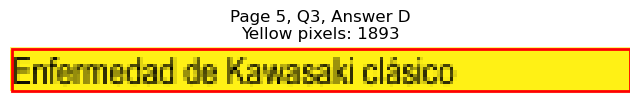


Page 5, Q3 - Selected Answer: D (based on yellow pixel count)




Page 5, Q4 - A: Detected box: x0=68.3, y0=341.9, x1=180.6, y1=354.6
Page 5, Q4, A: Yellow pixels: 0
Page 5, Q4, A: Total non-white pixels: 556
Page 5, Q4, A: Yellow percentage: 0.0%


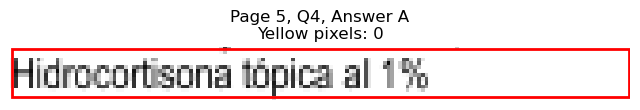

Page 5, Q4 - B: Detected box: x0=68.3, y0=354.5, x1=216.5, y1=367.2
Page 5, Q4, B: Yellow pixels: 0
Page 5, Q4, B: Total non-white pixels: 719
Page 5, Q4, B: Yellow percentage: 0.0%


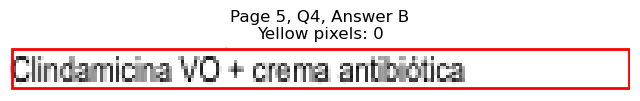

Page 5, Q4 - C: Detected box: x0=327.5, y0=341.9, x1=467.3, y1=354.6
Page 5, Q4, C: Yellow pixels: 191
Page 5, Q4, C: Total non-white pixels: 890
Page 5, Q4, C: Yellow percentage: 21.5%


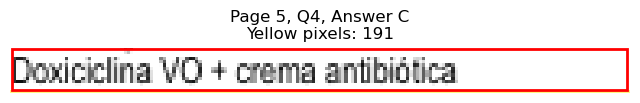

Page 5, Q4 - D: Detected box: x0=327.5, y0=354.5, x1=506.9, y1=367.2
Page 5, Q4, D: Yellow pixels: 2098
Page 5, Q4, D: Total non-white pixels: 2995
Page 5, Q4, D: Yellow percentage: 70.1%


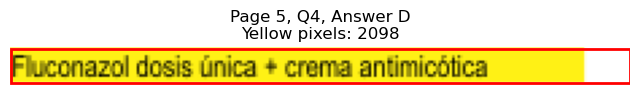


Page 5, Q4 - Selected Answer: D (based on yellow pixel count)




Page 5, Q5 - A: Detected box: x0=68.3, y0=404.9, x1=189.1, y1=417.6
Page 5, Q5, A: Yellow pixels: 0
Page 5, Q5, A: Total non-white pixels: 586
Page 5, Q5, A: Yellow percentage: 0.0%


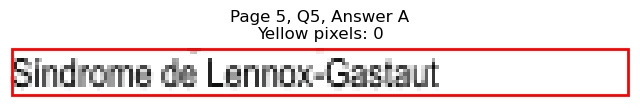

Page 5, Q5 - B: Detected box: x0=68.3, y0=417.6, x1=197.2, y1=430.3
Page 5, Q5, B: Yellow pixels: 0
Page 5, Q5, B: Total non-white pixels: 660
Page 5, Q5, B: Yellow percentage: 0.0%


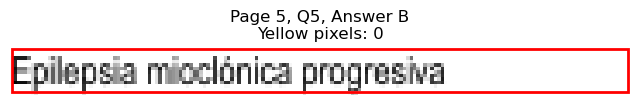

Page 5, Q5 - C: Detected box: x0=327.5, y0=404.9, x1=404.8, y1=417.6
Page 5, Q5, C: Yellow pixels: 1339
Page 5, Q5, C: Total non-white pixels: 1792
Page 5, Q5, C: Yellow percentage: 74.7%


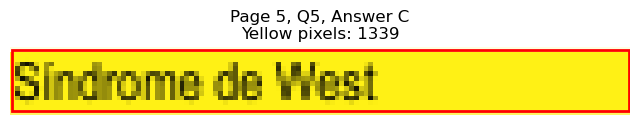

Page 5, Q5 - D: Detected box: x0=327.5, y0=417.6, x1=448.4, y1=430.3
Page 5, Q5, D: Yellow pixels: 172
Page 5, Q5, D: Total non-white pixels: 792
Page 5, Q5, D: Yellow percentage: 21.7%


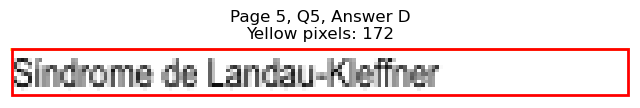


Page 5, Q5 - Selected Answer: C (based on yellow pixel count)




Page 5, Q6 - A: Detected box: x0=68.3, y0=493.4, x1=115.9, y1=506.0
Page 5, Q6, A: Yellow pixels: 1073
Page 5, Q6, A: Total non-white pixels: 1274
Page 5, Q6, A: Yellow percentage: 84.2%


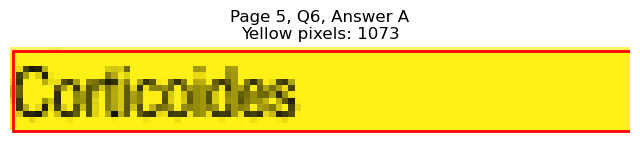

Page 5, Q6 - B: Detected box: x0=68.3, y0=506.0, x1=115.9, y1=518.6
Page 5, Q6, B: Yellow pixels: 98
Page 5, Q6, B: Total non-white pixels: 341
Page 5, Q6, B: Yellow percentage: 28.7%


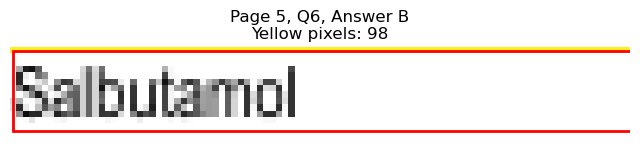

Page 5, Q6 - C: Detected box: x0=327.5, y0=493.4, x1=368.2, y1=506.0
Page 5, Q6, C: Yellow pixels: 0
Page 5, Q6, C: Total non-white pixels: 211
Page 5, Q6, C: Yellow percentage: 0.0%


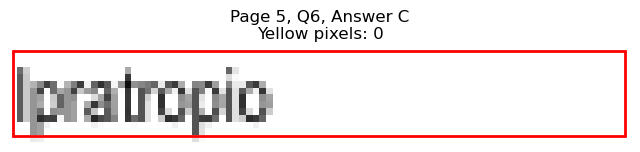

Page 5, Q6 - D: Detected box: x0=327.5, y0=506.0, x1=395.7, y1=518.6
Page 5, Q6, D: Yellow pixels: 0
Page 5, Q6, D: Total non-white pixels: 373
Page 5, Q6, D: Yellow percentage: 0.0%


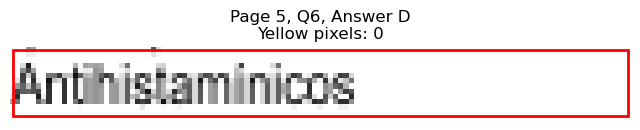


Page 5, Q6 - Selected Answer: A (based on yellow pixel count)




Page 5, Q7 - A: Detected box: x0=68.3, y0=543.8, x1=238.8, y1=556.4
Page 5, Q7, A: Yellow pixels: 0
Page 5, Q7, A: Total non-white pixels: 837
Page 5, Q7, A: Yellow percentage: 0.0%


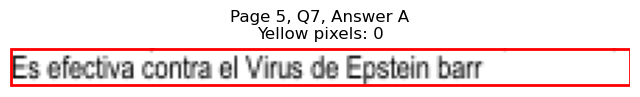

Page 5, Q7 - B: Detected box: x0=68.3, y0=556.5, x1=238.8, y1=569.2
Page 5, Q7, B: Yellow pixels: 0
Page 5, Q7, B: Total non-white pixels: 855
Page 5, Q7, B: Yellow percentage: 0.0%


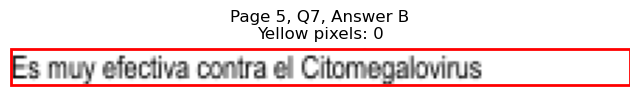

Page 5, Q7 - C: Detected box: x0=327.5, y0=543.8, x1=497.0, y1=556.4
Page 5, Q7, C: Yellow pixels: 0
Page 5, Q7, C: Total non-white pixels: 850
Page 5, Q7, C: Yellow percentage: 0.0%


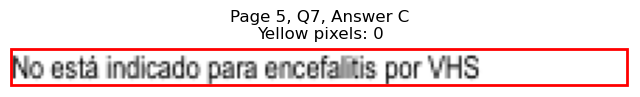

Page 5, Q7 - D: Detected box: x0=327.5, y0=556.5, x1=463.9, y1=569.2
Page 5, Q7, D: Yellow pixels: 1906
Page 5, Q7, D: Total non-white pixels: 2618
Page 5, Q7, D: Yellow percentage: 72.8%


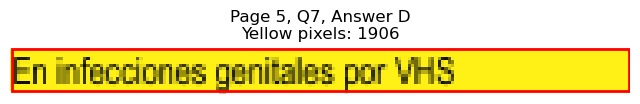


Page 5, Q7 - Selected Answer: D (based on yellow pixel count)




Page 5, Q8 - A: Detected box: x0=68.3, y0=619.6, x1=149.1, y1=632.3
Page 5, Q8, A: Yellow pixels: 132
Page 5, Q8, A: Total non-white pixels: 546
Page 5, Q8, A: Yellow percentage: 24.2%


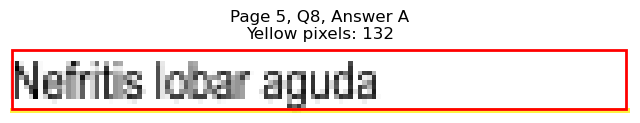

Page 5, Q8 - B: Detected box: x0=68.3, y0=632.2, x1=145.1, y1=644.9
Page 5, Q8, B: Yellow pixels: 1360
Page 5, Q8, B: Total non-white pixels: 1664
Page 5, Q8, B: Yellow percentage: 81.7%


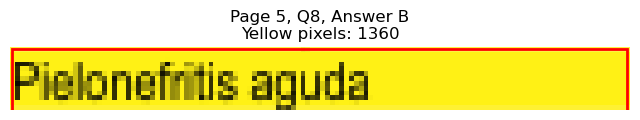

Page 5, Q8 - C: Detected box: x0=327.5, y0=619.6, x1=356.6, y1=632.3
Page 5, Q8, C: Yellow pixels: 0
Page 5, Q8, C: Total non-white pixels: 161
Page 5, Q8, C: Yellow percentage: 0.0%


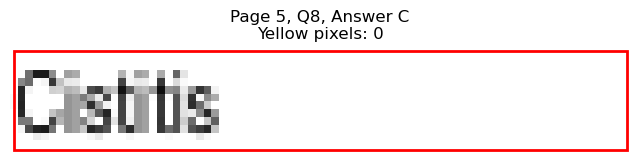

Page 5, Q8 - D: Detected box: x0=327.5, y0=632.2, x1=380.2, y1=644.9
Page 5, Q8, D: Yellow pixels: 0
Page 5, Q8, D: Total non-white pixels: 289
Page 5, Q8, D: Yellow percentage: 0.0%


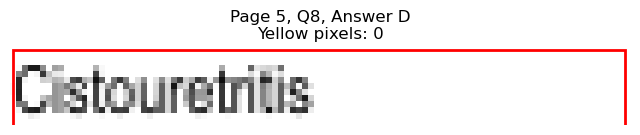


Page 5, Q8 - Selected Answer: B (based on yellow pixel count)




Page 5, Q9 - A: Detected box: x0=68.3, y0=695.4, x1=168.1, y1=708.0
Page 5, Q9, A: Yellow pixels: 0
Page 5, Q9, A: Total non-white pixels: 536
Page 5, Q9, A: Yellow percentage: 0.0%


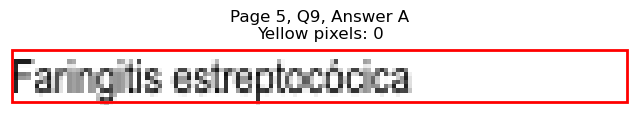

Page 5, Q9 - B: Detected box: x0=68.3, y0=708.0, x1=181.6, y1=720.6
Page 5, Q9, B: Yellow pixels: 0
Page 5, Q9, B: Total non-white pixels: 581
Page 5, Q9, B: Yellow percentage: 0.0%


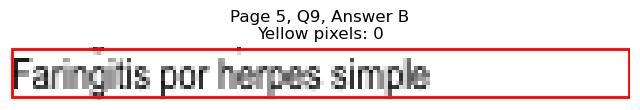

Page 5, Q9 - C: Detected box: x0=327.5, y0=695.4, x1=428.8, y1=708.0
Page 5, Q9, C: Yellow pixels: 152
Page 5, Q9, C: Total non-white pixels: 817
Page 5, Q9, C: Yellow percentage: 18.6%


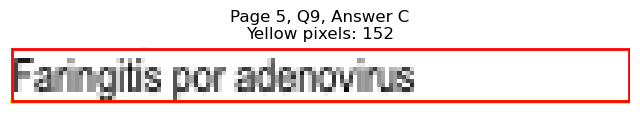

Page 5, Q9 - D: Detected box: x0=327.5, y0=708.0, x1=374.3, y1=720.6
Page 5, Q9, D: Yellow pixels: 1053
Page 5, Q9, D: Total non-white pixels: 1372
Page 5, Q9, D: Yellow percentage: 76.7%


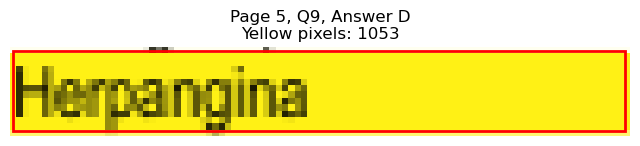


Page 5, Q9 - Selected Answer: D (based on yellow pixel count)





Page 6: Found 9 questions
Page 6, Q1 - A: Detected box: x0=68.3, y0=114.6, x1=145.6, y1=127.3
Page 6, Q1, A: Yellow pixels: 0
Page 6, Q1, A: Total non-white pixels: 355
Page 6, Q1, A: Yellow percentage: 0.0%


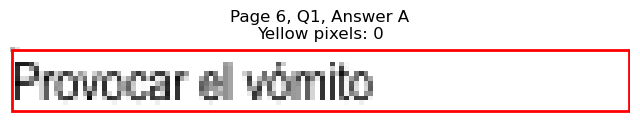

Page 6, Q1 - B: Detected box: x0=68.3, y0=127.2, x1=136.5, y1=139.9
Page 6, Q1, B: Yellow pixels: 0
Page 6, Q1, B: Total non-white pixels: 340
Page 6, Q1, B: Yellow percentage: 0.0%


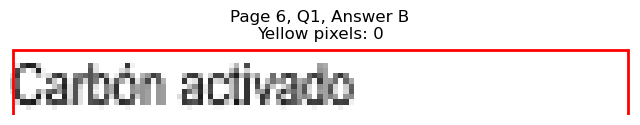

Page 6, Q1 - C: Detected box: x0=327.5, y0=114.6, x1=454.5, y1=127.3
Page 6, Q1, C: Yellow pixels: 1681
Page 6, Q1, C: Total non-white pixels: 2492
Page 6, Q1, C: Yellow percentage: 67.5%


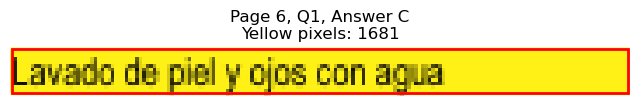

Page 6, Q1 - D: Detected box: x0=327.5, y0=127.2, x1=393.8, y1=139.9
Page 6, Q1, D: Yellow pixels: 0
Page 6, Q1, D: Total non-white pixels: 432
Page 6, Q1, D: Yellow percentage: 0.0%


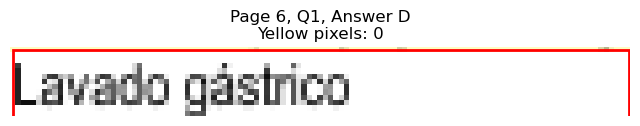


Page 6, Q1 - Selected Answer: C (based on yellow pixel count)




Page 6, Q2 - A: Detected box: x0=68.3, y0=190.3, x1=156.0, y1=203.0
Page 6, Q2, A: Yellow pixels: 0
Page 6, Q2, A: Total non-white pixels: 600
Page 6, Q2, A: Yellow percentage: 0.0%


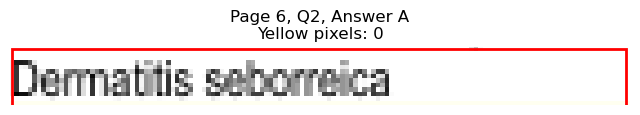

Page 6, Q2 - B: Detected box: x0=68.3, y0=202.9, x1=143.1, y1=215.6
Page 6, Q2, B: Yellow pixels: 1334
Page 6, Q2, B: Total non-white pixels: 1764
Page 6, Q2, B: Yellow percentage: 75.6%


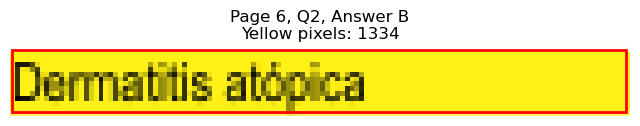

Page 6, Q2 - C: Detected box: x0=327.5, y0=190.3, x1=397.7, y1=203.0
Page 6, Q2, C: Yellow pixels: 0
Page 6, Q2, C: Total non-white pixels: 339
Page 6, Q2, C: Yellow percentage: 0.0%


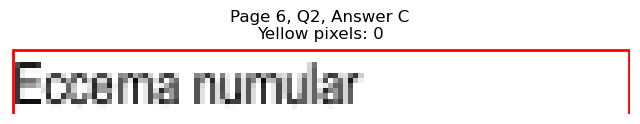

Page 6, Q2 - D: Detected box: x0=327.5, y0=202.9, x1=384.7, y1=215.6
Page 6, Q2, D: Yellow pixels: 0
Page 6, Q2, D: Total non-white pixels: 304
Page 6, Q2, D: Yellow percentage: 0.0%


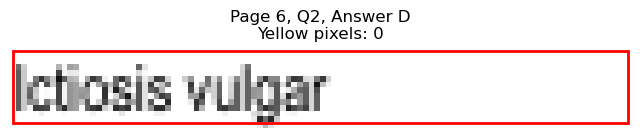


Page 6, Q2 - Selected Answer: B (based on yellow pixel count)




Page 6, Q3 - A: Detected box: x0=68.3, y0=253.5, x1=232.8, y1=266.1
Page 6, Q3, A: Yellow pixels: 0
Page 6, Q3, A: Total non-white pixels: 825
Page 6, Q3, A: Yellow percentage: 0.0%


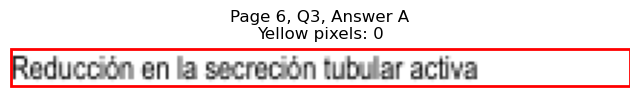

Page 6, Q3 - B: Detected box: x0=68.3, y0=266.1, x1=231.9, y1=278.7
Page 6, Q3, B: Yellow pixels: 0
Page 6, Q3, B: Total non-white pixels: 833
Page 6, Q3, B: Yellow percentage: 0.0%


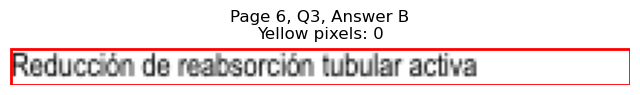

Page 6, Q3 - C: Detected box: x0=327.5, y0=253.5, x1=478.5, y1=266.1
Page 6, Q3, C: Yellow pixels: 2020
Page 6, Q3, C: Total non-white pixels: 2828
Page 6, Q3, C: Yellow percentage: 71.4%


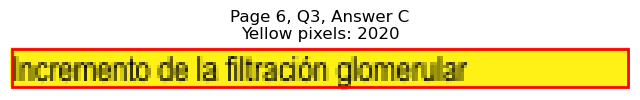

Page 6, Q3 - D: Detected box: x0=327.5, y0=266.1, x1=523.7, y1=278.7
Page 6, Q3, D: Yellow pixels: 0
Page 6, Q3, D: Total non-white pixels: 1171
Page 6, Q3, D: Yellow percentage: 0.0%


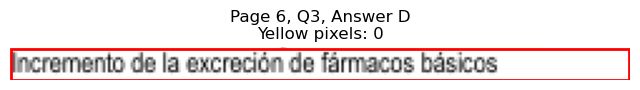


Page 6, Q3 - Selected Answer: C (based on yellow pixel count)




Page 6, Q4 - A: Detected box: x0=68.3, y0=341.9, x1=159.6, y1=354.6
Page 6, Q4, A: Yellow pixels: 1475
Page 6, Q4, A: Total non-white pixels: 1988
Page 6, Q4, A: Yellow percentage: 74.2%


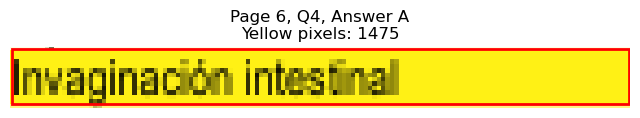

Page 6, Q4 - B: Detected box: x0=68.3, y0=354.5, x1=135.0, y1=367.2
Page 6, Q4, B: Yellow pixels: 116
Page 6, Q4, B: Total non-white pixels: 457
Page 6, Q4, B: Yellow percentage: 25.4%


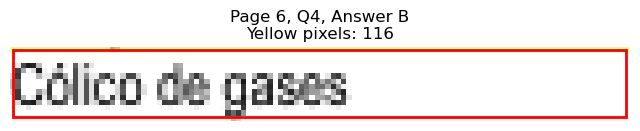

Page 6, Q4 - C: Detected box: x0=327.5, y0=341.9, x1=401.3, y1=354.6
Page 6, Q4, C: Yellow pixels: 0
Page 6, Q4, C: Total non-white pixels: 382
Page 6, Q4, C: Yellow percentage: 0.0%


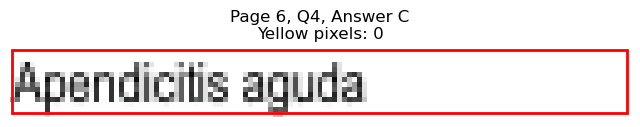

Page 6, Q4 - D: Detected box: x0=327.5, y0=354.5, x1=414.8, y1=367.2
Page 6, Q4, D: Yellow pixels: 0
Page 6, Q4, D: Total non-white pixels: 480
Page 6, Q4, D: Yellow percentage: 0.0%


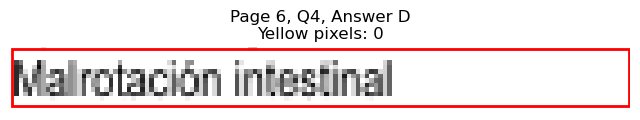


Page 6, Q4 - Selected Answer: A (based on yellow pixel count)




Page 6, Q5 - A: Detected box: x0=68.3, y0=392.3, x1=112.9, y1=405.0
Page 6, Q5, A: Yellow pixels: 1067
Page 6, Q5, A: Total non-white pixels: 1235
Page 6, Q5, A: Yellow percentage: 86.4%


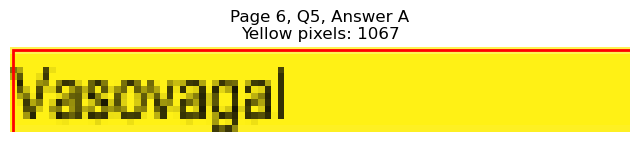

Page 6, Q5 - B: Detected box: x0=68.3, y0=404.9, x1=118.5, y1=417.6
Page 6, Q5, B: Yellow pixels: 97
Page 6, Q5, B: Total non-white pixels: 373
Page 6, Q5, B: Yellow percentage: 26.0%


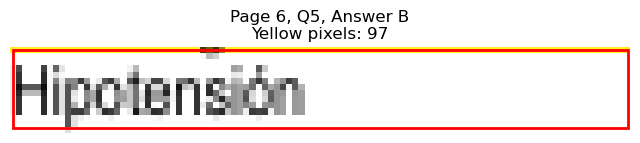

Page 6, Q5 - C: Detected box: x0=327.5, y0=392.3, x1=365.1, y1=405.0
Page 6, Q5, C: Yellow pixels: 0
Page 6, Q5, C: Total non-white pixels: 180
Page 6, Q5, C: Yellow percentage: 0.0%


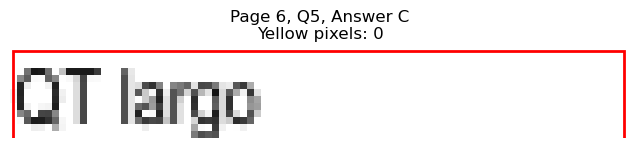

Page 6, Q5 - D: Detected box: x0=327.5, y0=404.9, x1=398.8, y1=417.6
Page 6, Q5, D: Yellow pixels: 0
Page 6, Q5, D: Total non-white pixels: 364
Page 6, Q5, D: Yellow percentage: 0.0%


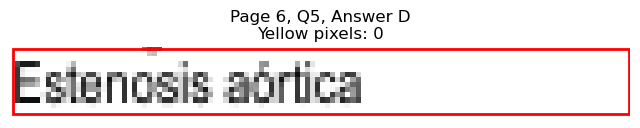


Page 6, Q5 - Selected Answer: A (based on yellow pixel count)




Page 6, Q6 - A: Detected box: x0=68.3, y0=442.8, x1=240.3, y1=455.5
Page 6, Q6, A: Yellow pixels: 2256
Page 6, Q6, A: Total non-white pixels: 3122
Page 6, Q6, A: Yellow percentage: 72.3%


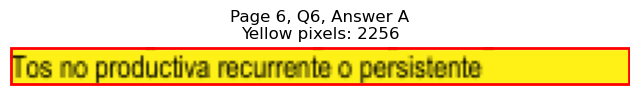

Page 6, Q6 - B: Detected box: x0=68.3, y0=455.5, x1=174.1, y1=468.1
Page 6, Q6, B: Yellow pixels: 0
Page 6, Q6, B: Total non-white pixels: 510
Page 6, Q6, B: Yellow percentage: 0.0%


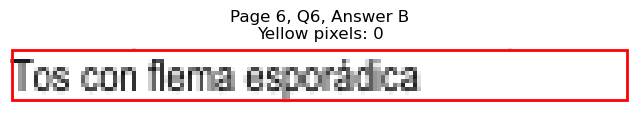

Page 6, Q6 - C: Detected box: x0=68.8, y0=468.1, x1=356.7, y1=480.7
Page 6, Q6, C: Yellow pixels: 0
Page 6, Q6, C: Total non-white pixels: 1383
Page 6, Q6, C: Yellow percentage: 0.0%


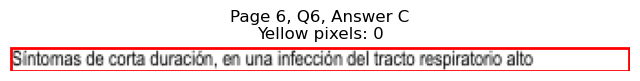

Page 6, Q6 - D: Detected box: x0=68.8, y0=480.8, x1=189.6, y1=493.4
Page 6, Q6, D: Yellow pixels: 0
Page 6, Q6, D: Total non-white pixels: 584
Page 6, Q6, D: Yellow percentage: 0.0%


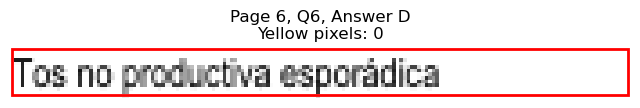


Page 6, Q6 - Selected Answer: A (based on yellow pixel count)




Page 6, Q7 - A: Detected box: x0=68.3, y0=543.8, x1=169.6, y1=556.4
Page 6, Q7, A: Yellow pixels: 0
Page 6, Q7, A: Total non-white pixels: 528
Page 6, Q7, A: Yellow percentage: 0.0%


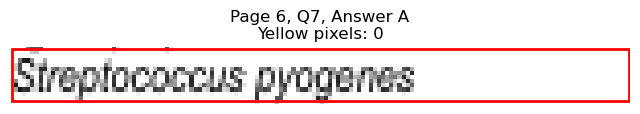

Page 6, Q7 - B: Detected box: x0=68.3, y0=556.5, x1=121.5, y1=569.2
Page 6, Q7, B: Yellow pixels: 0
Page 6, Q7, B: Total non-white pixels: 254
Page 6, Q7, B: Yellow percentage: 0.0%


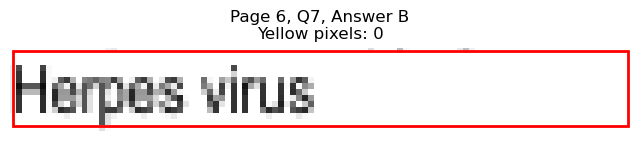

Page 6, Q7 - C: Detected box: x0=327.5, y0=543.8, x1=375.2, y1=556.4
Page 6, Q7, C: Yellow pixels: 1109
Page 6, Q7, C: Total non-white pixels: 1386
Page 6, Q7, C: Yellow percentage: 80.0%


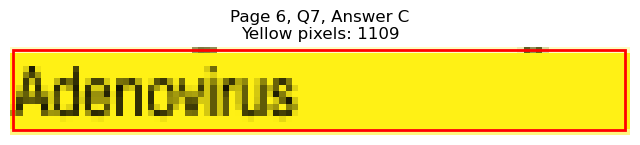

Page 6, Q7 - D: Detected box: x0=327.5, y0=556.5, x1=390.8, y1=569.2
Page 6, Q7, D: Yellow pixels: 114
Page 6, Q7, D: Total non-white pixels: 442
Page 6, Q7, D: Yellow percentage: 25.8%


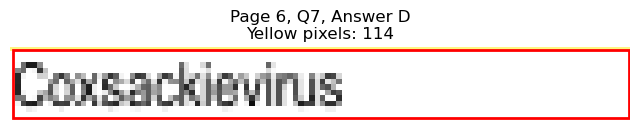


Page 6, Q7 - Selected Answer: C (based on yellow pixel count)




Page 6, Q8 - A: Detected box: x0=68.3, y0=619.6, x1=161.5, y1=632.3
Page 6, Q8, A: Yellow pixels: 0
Page 6, Q8, A: Total non-white pixels: 492
Page 6, Q8, A: Yellow percentage: 0.0%


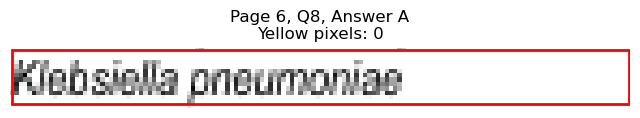

Page 6, Q8 - B: Detected box: x0=68.3, y0=632.2, x1=175.6, y1=644.9
Page 6, Q8, B: Yellow pixels: 0
Page 6, Q8, B: Total non-white pixels: 525
Page 6, Q8, B: Yellow percentage: 0.0%


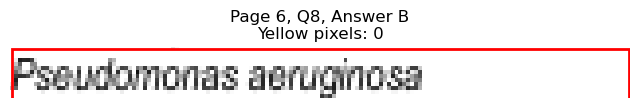

Page 6, Q8 - C: Detected box: x0=327.5, y0=619.6, x1=399.8, y1=632.3
Page 6, Q8, C: Yellow pixels: 123
Page 6, Q8, C: Total non-white pixels: 495
Page 6, Q8, C: Yellow percentage: 24.8%


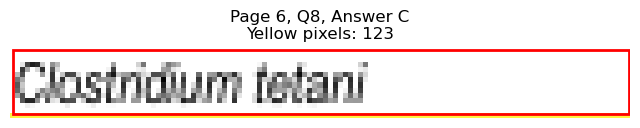

Page 6, Q8 - D: Detected box: x0=327.5, y0=632.2, x1=423.3, y1=644.9
Page 6, Q8, D: Yellow pixels: 1542
Page 6, Q8, D: Total non-white pixels: 1911
Page 6, Q8, D: Yellow percentage: 80.7%


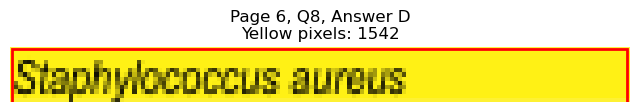


Page 6, Q8 - Selected Answer: D (based on yellow pixel count)




Page 6, Q9 - A: Detected box: x0=68.3, y0=695.4, x1=134.5, y1=708.0
Page 6, Q9, A: Yellow pixels: 1299
Page 6, Q9, A: Total non-white pixels: 1521
Page 6, Q9, A: Yellow percentage: 85.4%


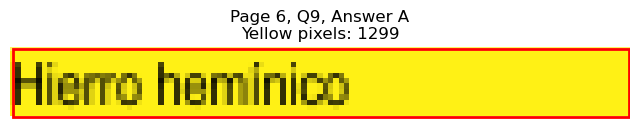

Page 6, Q9 - B: Detected box: x0=68.3, y0=708.0, x1=142.6, y1=720.6
Page 6, Q9, B: Yellow pixels: 125
Page 6, Q9, B: Total non-white pixels: 490
Page 6, Q9, B: Yellow percentage: 25.5%


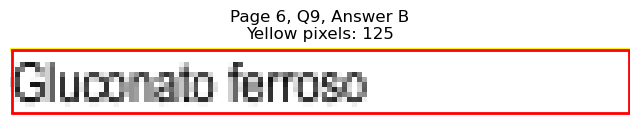

Page 6, Q9 - C: Detected box: x0=327.5, y0=695.4, x1=388.7, y1=708.0
Page 6, Q9, C: Yellow pixels: 0
Page 6, Q9, C: Total non-white pixels: 283
Page 6, Q9, C: Yellow percentage: 0.0%


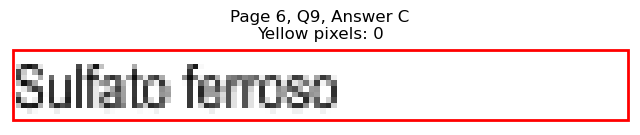

Page 6, Q9 - D: Detected box: x0=327.5, y0=708.0, x1=410.3, y1=720.6
Page 6, Q9, D: Yellow pixels: 0
Page 6, Q9, D: Total non-white pixels: 441
Page 6, Q9, D: Yellow percentage: 0.0%


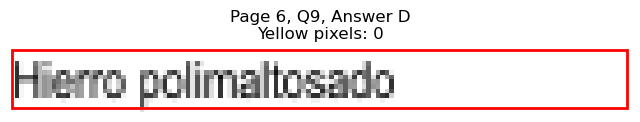


Page 6, Q9 - Selected Answer: A (based on yellow pixel count)





Page 7: Found 9 questions
Page 7, Q1 - A: Detected box: x0=68.3, y0=114.6, x1=146.5, y1=127.3
Page 7, Q1, A: Yellow pixels: 1246
Page 7, Q1, A: Total non-white pixels: 1806
Page 7, Q1, A: Yellow percentage: 69.0%


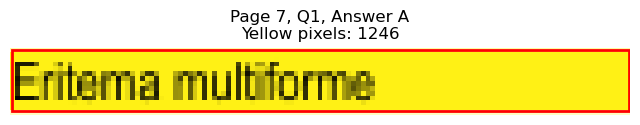

Page 7, Q1 - B: Detected box: x0=68.3, y0=127.2, x1=173.7, y1=139.9
Page 7, Q1, B: Yellow pixels: 0
Page 7, Q1, B: Total non-white pixels: 685
Page 7, Q1, B: Yellow percentage: 0.0%


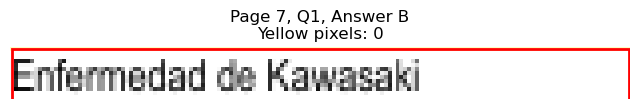

Page 7, Q1 - C: Detected box: x0=327.5, y0=114.6, x1=453.9, y1=127.3
Page 7, Q1, C: Yellow pixels: 0
Page 7, Q1, C: Total non-white pixels: 636
Page 7, Q1, C: Yellow percentage: 0.0%


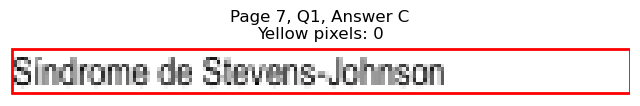

Page 7, Q1 - D: Detected box: x0=327.5, y0=127.2, x1=415.9, y1=139.9
Page 7, Q1, D: Yellow pixels: 0
Page 7, Q1, D: Total non-white pixels: 440
Page 7, Q1, D: Yellow percentage: 0.0%


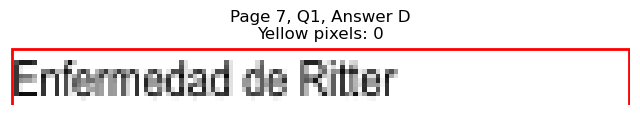


Page 7, Q1 - Selected Answer: A (based on yellow pixel count)




Page 7, Q2 - A: Detected box: x0=68.3, y0=190.3, x1=158.5, y1=203.0
Page 7, Q2, A: Yellow pixels: 0
Page 7, Q2, A: Total non-white pixels: 423
Page 7, Q2, A: Yellow percentage: 0.0%


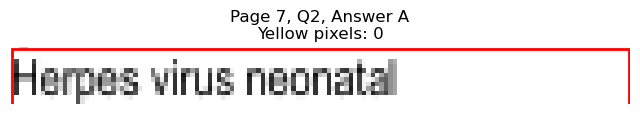

Page 7, Q2 - B: Detected box: x0=68.3, y0=202.9, x1=187.7, y1=215.6
Page 7, Q2, B: Yellow pixels: 0
Page 7, Q2, B: Total non-white pixels: 594
Page 7, Q2, B: Yellow percentage: 0.0%


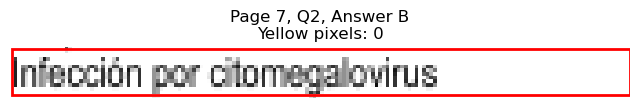

Page 7, Q2 - C: Detected box: x0=327.5, y0=190.3, x1=455.9, y1=203.0
Page 7, Q2, C: Yellow pixels: 1795
Page 7, Q2, C: Total non-white pixels: 2327
Page 7, Q2, C: Yellow percentage: 77.1%


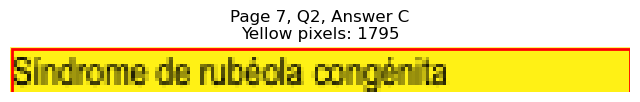

Page 7, Q2 - D: Detected box: x0=327.5, y0=202.9, x1=431.8, y1=215.6
Page 7, Q2, D: Yellow pixels: 151
Page 7, Q2, D: Total non-white pixels: 709
Page 7, Q2, D: Yellow percentage: 21.3%


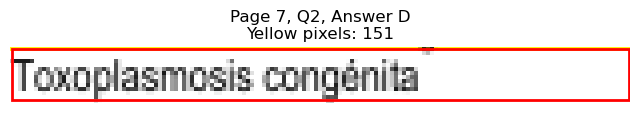


Page 7, Q2 - Selected Answer: C (based on yellow pixel count)




Page 7, Q3 - A: Detected box: x0=68.3, y0=240.9, x1=244.1, y1=253.5
Page 7, Q3, A: Yellow pixels: 2243
Page 7, Q3, A: Total non-white pixels: 3178
Page 7, Q3, A: Yellow percentage: 70.6%


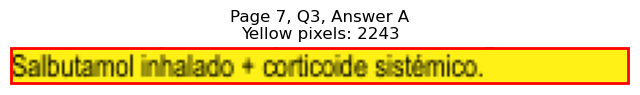

Page 7, Q3 - B: Detected box: x0=68.3, y0=253.5, x1=251.7, y1=266.1
Page 7, Q3, B: Yellow pixels: 234
Page 7, Q3, B: Total non-white pixels: 1124
Page 7, Q3, B: Yellow percentage: 20.8%


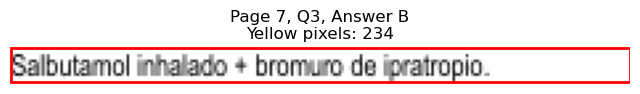

Page 7, Q3 - C: Detected box: x0=68.8, y0=266.1, x1=246.5, y1=278.7
Page 7, Q3, C: Yellow pixels: 0
Page 7, Q3, C: Total non-white pixels: 860
Page 7, Q3, C: Yellow percentage: 0.0%


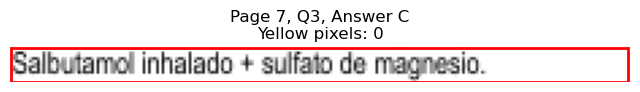

Page 7, Q3 - D: Detected box: x0=68.8, y0=278.8, x1=339.7, y1=291.5
Page 7, Q3, D: Yellow pixels: 0
Page 7, Q3, D: Total non-white pixels: 1296
Page 7, Q3, D: Yellow percentage: 0.0%


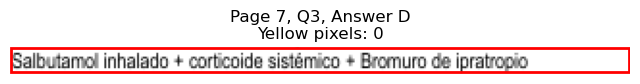


Page 7, Q3 - Selected Answer: A (based on yellow pixel count)




Page 7, Q4 - A: Detected box: x0=68.3, y0=354.5, x1=104.4, y1=367.2
Page 7, Q4, A: Yellow pixels: 0
Page 7, Q4, A: Total non-white pixels: 200
Page 7, Q4, A: Yellow percentage: 0.0%


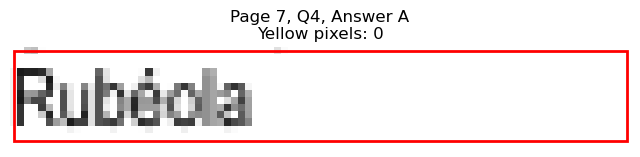

Page 7, Q4 - B: Detected box: x0=68.3, y0=367.1, x1=138.0, y1=379.8
Page 7, Q4, B: Yellow pixels: 0
Page 7, Q4, B: Total non-white pixels: 367
Page 7, Q4, B: Yellow percentage: 0.0%


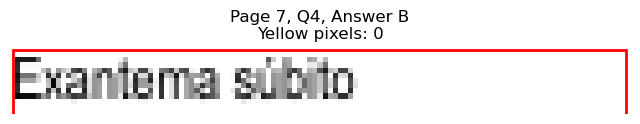

Page 7, Q4 - C: Detected box: x0=327.5, y0=354.5, x1=373.7, y1=367.2
Page 7, Q4, C: Yellow pixels: 1080
Page 7, Q4, C: Total non-white pixels: 1358
Page 7, Q4, C: Yellow percentage: 79.5%


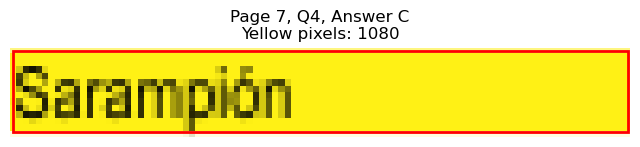

Page 7, Q4 - D: Detected box: x0=327.5, y0=367.1, x1=403.7, y1=379.8
Page 7, Q4, D: Yellow pixels: 0
Page 7, Q4, D: Total non-white pixels: 497
Page 7, Q4, D: Yellow percentage: 0.0%


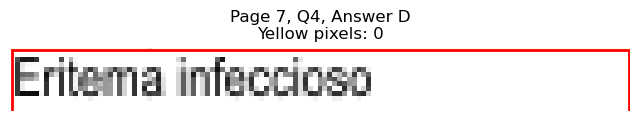


Page 7, Q4 - Selected Answer: C (based on yellow pixel count)




Page 7, Q5 - A: Detected box: x0=68.3, y0=430.2, x1=281.4, y1=442.9
Page 7, Q5, A: Yellow pixels: 2616
Page 7, Q5, A: Total non-white pixels: 3432
Page 7, Q5, A: Yellow percentage: 76.2%


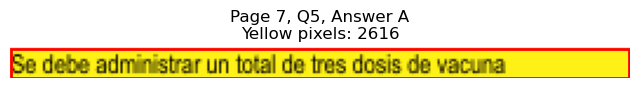

Page 7, Q5 - B: Detected box: x0=68.3, y0=442.8, x1=358.3, y1=455.5
Page 7, Q5, B: Yellow pixels: 341
Page 7, Q5, B: Total non-white pixels: 1755
Page 7, Q5, B: Yellow percentage: 19.4%


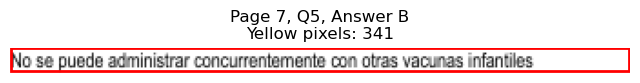

Page 7, Q5 - C: Detected box: x0=68.8, y0=455.5, x1=319.5, y1=468.1
Page 7, Q5, C: Yellow pixels: 0
Page 7, Q5, C: Total non-white pixels: 1189
Page 7, Q5, C: Yellow percentage: 0.0%


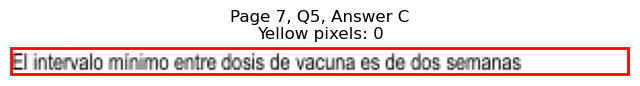

Page 7, Q5 - D: Detected box: x0=68.8, y0=468.1, x1=384.8, y1=480.7
Page 7, Q5, D: Yellow pixels: 0
Page 7, Q5, D: Total non-white pixels: 1536
Page 7, Q5, D: Yellow percentage: 0.0%


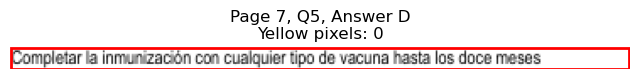


Page 7, Q5 - Selected Answer: A (based on yellow pixel count)




Page 7, Q6 - A: Detected box: x0=68.3, y0=518.6, x1=145.0, y1=531.2
Page 7, Q6, A: Yellow pixels: 127
Page 7, Q6, A: Total non-white pixels: 503
Page 7, Q6, A: Yellow percentage: 25.2%


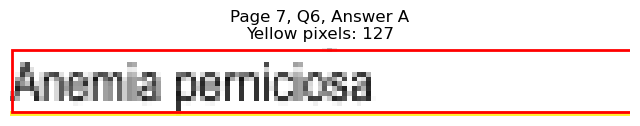

Page 7, Q6 - B: Detected box: x0=68.3, y0=531.2, x1=149.1, y1=543.8
Page 7, Q6, B: Yellow pixels: 1368
Page 7, Q6, B: Total non-white pixels: 1716
Page 7, Q6, B: Yellow percentage: 79.7%


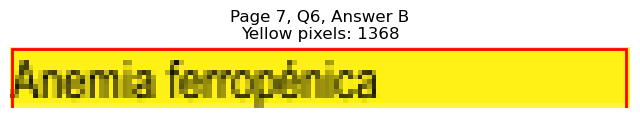

Page 7, Q6 - C: Detected box: x0=327.5, y0=518.6, x1=369.2, y1=531.2
Page 7, Q6, C: Yellow pixels: 0
Page 7, Q6, C: Total non-white pixels: 221
Page 7, Q6, C: Yellow percentage: 0.0%


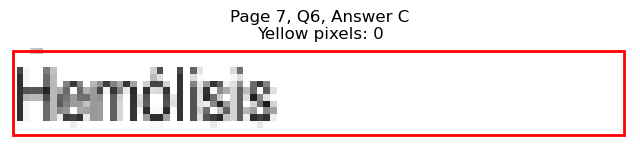

Page 7, Q6 - D: Detected box: x0=327.5, y0=531.2, x1=386.7, y1=543.8
Page 7, Q6, D: Yellow pixels: 0
Page 7, Q6, D: Total non-white pixels: 344
Page 7, Q6, D: Yellow percentage: 0.0%


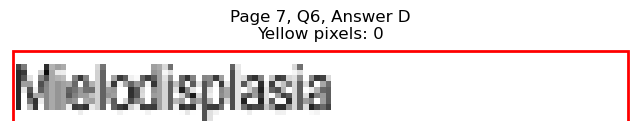


Page 7, Q6 - Selected Answer: B (based on yellow pixel count)




Page 7, Q7 - A: Detected box: x0=68.3, y0=569.1, x1=260.0, y1=581.8
Page 7, Q7, A: Yellow pixels: 2054
Page 7, Q7, A: Total non-white pixels: 2782
Page 7, Q7, A: Yellow percentage: 73.8%


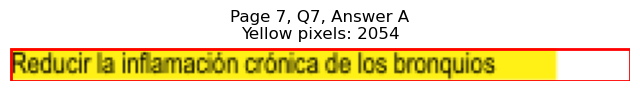

Page 7, Q7 - B: Detected box: x0=68.3, y0=581.7, x1=265.4, y1=594.4
Page 7, Q7, B: Yellow pixels: 213
Page 7, Q7, B: Total non-white pixels: 1216
Page 7, Q7, B: Yellow percentage: 17.5%


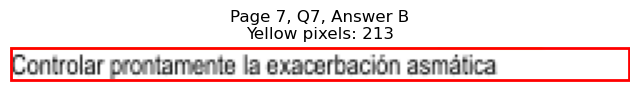

Page 7, Q7 - C: Detected box: x0=327.5, y0=569.1, x1=481.4, y1=581.8
Page 7, Q7, C: Yellow pixels: 0
Page 7, Q7, C: Total non-white pixels: 770
Page 7, Q7, C: Yellow percentage: 0.0%


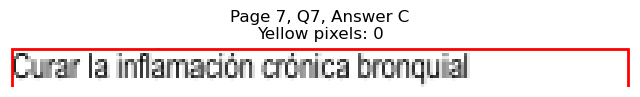

Page 7, Q7 - D: Detected box: x0=327.5, y0=581.7, x1=464.0, y1=594.4
Page 7, Q7, D: Yellow pixels: 0
Page 7, Q7, D: Total non-white pixels: 637
Page 7, Q7, D: Yellow percentage: 0.0%


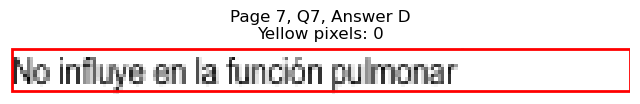


Page 7, Q7 - Selected Answer: A (based on yellow pixel count)




Page 7, Q8 - A: Detected box: x0=68.3, y0=619.6, x1=121.9, y1=632.3
Page 7, Q8, A: Yellow pixels: 0
Page 7, Q8, A: Total non-white pixels: 287
Page 7, Q8, A: Yellow percentage: 0.0%


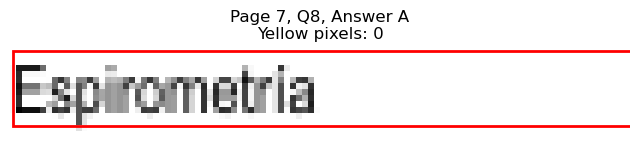

Page 7, Q8 - B: Detected box: x0=68.3, y0=632.2, x1=128.5, y1=644.9
Page 7, Q8, B: Yellow pixels: 0
Page 7, Q8, B: Total non-white pixels: 337
Page 7, Q8, B: Yellow percentage: 0.0%


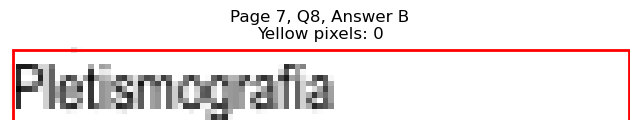

Page 7, Q8 - C: Detected box: x0=327.5, y0=619.6, x1=431.3, y1=632.3
Page 7, Q8, C: Yellow pixels: 155
Page 7, Q8, C: Total non-white pixels: 668
Page 7, Q8, C: Yellow percentage: 23.2%


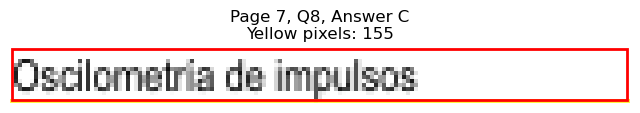

Page 7, Q8 - D: Detected box: x0=327.5, y0=632.2, x1=475.4, y1=644.9
Page 7, Q8, D: Yellow pixels: 2000
Page 7, Q8, D: Total non-white pixels: 2587
Page 7, Q8, D: Yellow percentage: 77.3%


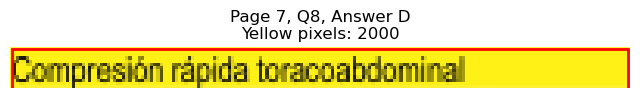


Page 7, Q8 - Selected Answer: D (based on yellow pixel count)




Page 7, Q9 - A: Detected box: x0=68.3, y0=695.4, x1=103.5, y1=708.0
Page 7, Q9, A: Yellow pixels: 0
Page 7, Q9, A: Total non-white pixels: 179
Page 7, Q9, A: Yellow percentage: 0.0%


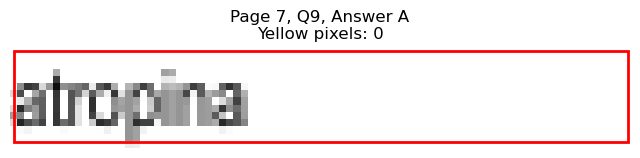

Page 7, Q9 - B: Detected box: x0=68.3, y0=708.0, x1=119.4, y1=720.6
Page 7, Q9, B: Yellow pixels: 0
Page 7, Q9, B: Total non-white pixels: 265
Page 7, Q9, B: Yellow percentage: 0.0%


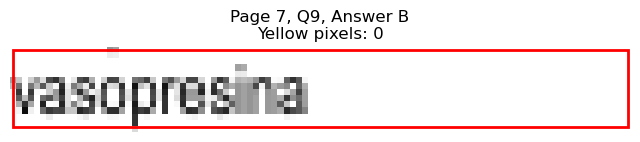

Page 7, Q9 - C: Detected box: x0=327.5, y0=695.4, x1=371.7, y1=708.0
Page 7, Q9, C: Yellow pixels: 95
Page 7, Q9, C: Total non-white pixels: 414
Page 7, Q9, C: Yellow percentage: 22.9%


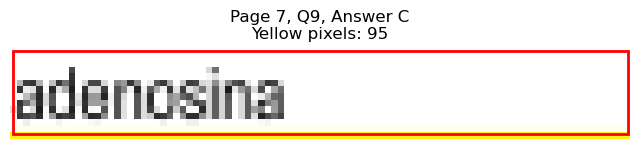

Page 7, Q9 - D: Detected box: x0=327.5, y0=708.0, x1=375.3, y1=720.6
Page 7, Q9, D: Yellow pixels: 1085
Page 7, Q9, D: Total non-white pixels: 1386
Page 7, Q9, D: Yellow percentage: 78.3%


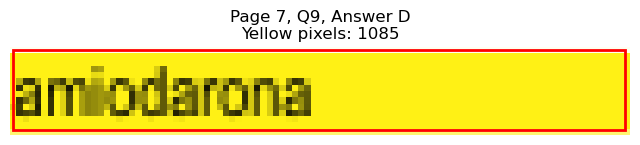


Page 7, Q9 - Selected Answer: D (based on yellow pixel count)





Page 8: Found 9 questions
Page 8, Q1 - A: Detected box: x0=68.3, y0=127.2, x1=93.9, y1=139.9
Page 8, Q1, A: Yellow pixels: 0
Page 8, Q1, A: Total non-white pixels: 137
Page 8, Q1, A: Yellow percentage: 0.0%


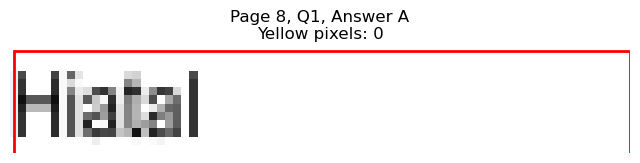

Page 8, Q1 - B: Detected box: x0=68.3, y0=139.9, x1=128.5, y1=152.6
Page 8, Q1, B: Yellow pixels: 0
Page 8, Q1, B: Total non-white pixels: 328
Page 8, Q1, B: Yellow percentage: 0.0%


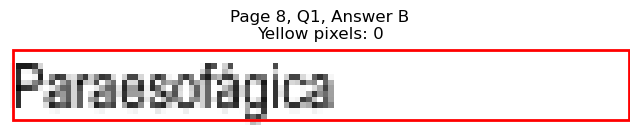

Page 8, Q1 - C: Detected box: x0=327.5, y0=127.2, x1=384.2, y1=139.9
Page 8, Q1, C: Yellow pixels: 0
Page 8, Q1, C: Total non-white pixels: 301
Page 8, Q1, C: Yellow percentage: 0.0%


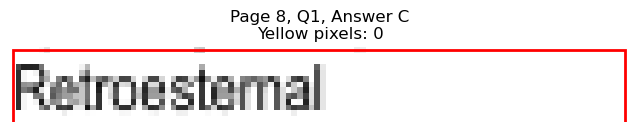

Page 8, Q1 - D: Detected box: x0=327.5, y0=139.9, x1=371.2, y1=152.6
Page 8, Q1, D: Yellow pixels: 1049
Page 8, Q1, D: Total non-white pixels: 1330
Page 8, Q1, D: Yellow percentage: 78.9%


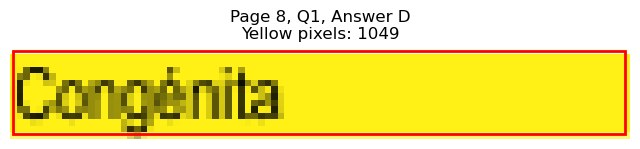


Page 8, Q1 - Selected Answer: D (based on yellow pixel count)




Page 8, Q2 - A: Detected box: x0=68.3, y0=177.7, x1=153.9, y1=190.4
Page 8, Q2, A: Yellow pixels: 0
Page 8, Q2, A: Total non-white pixels: 387
Page 8, Q2, A: Yellow percentage: 0.0%


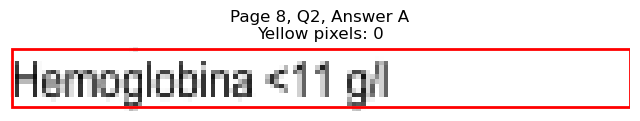

Page 8, Q2 - B: Detected box: x0=68.3, y0=190.3, x1=148.8, y1=203.0
Page 8, Q2, B: Yellow pixels: 0
Page 8, Q2, B: Total non-white pixels: 383
Page 8, Q2, B: Yellow percentage: 0.0%


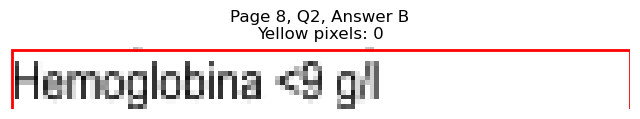

Page 8, Q2 - C: Detected box: x0=68.8, y0=202.9, x1=399.4, y1=215.6
Page 8, Q2, C: Yellow pixels: 0
Page 8, Q2, C: Total non-white pixels: 1667
Page 8, Q2, C: Yellow percentage: 0.0%


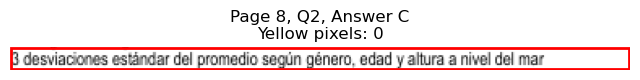

Page 8, Q2 - D: Detected box: x0=68.8, y0=215.7, x1=399.4, y1=228.3
Page 8, Q2, D: Yellow pixels: 3354
Page 8, Q2, D: Total non-white pixels: 5348
Page 8, Q2, D: Yellow percentage: 62.7%


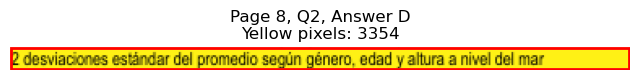


Page 8, Q2 - Selected Answer: D (based on yellow pixel count)




Page 8, Q3 - A: Detected box: x0=68.3, y0=278.8, x1=145.0, y1=291.5
Page 8, Q3, A: Yellow pixels: 0
Page 8, Q3, A: Total non-white pixels: 365
Page 8, Q3, A: Yellow percentage: 0.0%


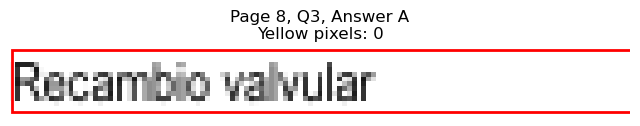

Page 8, Q3 - B: Detected box: x0=68.3, y0=291.4, x1=149.5, y1=304.1
Page 8, Q3, B: Yellow pixels: 0
Page 8, Q3, B: Total non-white pixels: 398
Page 8, Q3, B: Yellow percentage: 0.0%


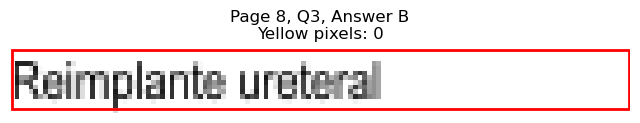

Page 8, Q3 - C: Detected box: x0=327.5, y0=278.8, x1=418.9, y1=291.5
Page 8, Q3, C: Yellow pixels: 1499
Page 8, Q3, C: Total non-white pixels: 1988
Page 8, Q3, C: Yellow percentage: 75.4%


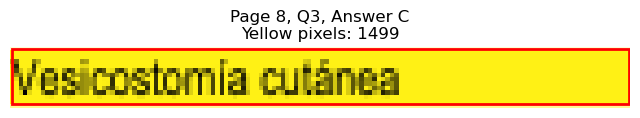

Page 8, Q3 - D: Detected box: x0=327.5, y0=291.4, x1=379.1, y1=304.1
Page 8, Q3, D: Yellow pixels: 103
Page 8, Q3, D: Total non-white pixels: 354
Page 8, Q3, D: Yellow percentage: 29.1%


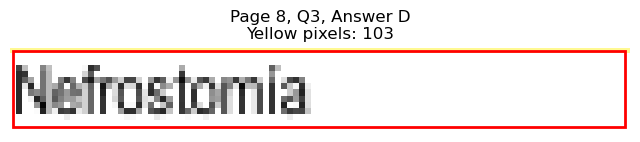


Page 8, Q3 - Selected Answer: C (based on yellow pixel count)




Page 8, Q4 - A: Detected box: x0=68.3, y0=354.5, x1=188.2, y1=367.2
Page 8, Q4, A: Yellow pixels: 1748
Page 8, Q4, A: Total non-white pixels: 2394
Page 8, Q4, A: Yellow percentage: 73.0%


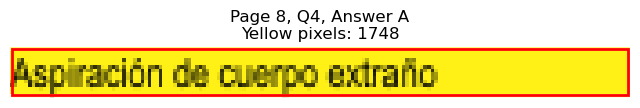

Page 8, Q4 - B: Detected box: x0=68.3, y0=367.1, x1=220.7, y1=379.8
Page 8, Q4, B: Yellow pixels: 0
Page 8, Q4, B: Total non-white pixels: 933
Page 8, Q4, B: Yellow percentage: 0.0%


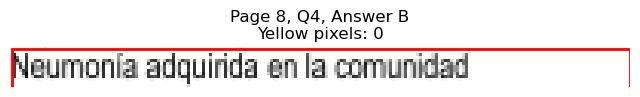

Page 8, Q4 - C: Detected box: x0=327.5, y0=354.5, x1=420.8, y1=367.2
Page 8, Q4, C: Yellow pixels: 0
Page 8, Q4, C: Total non-white pixels: 477
Page 8, Q4, C: Yellow percentage: 0.0%


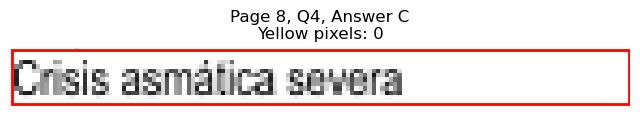

Page 8, Q4 - D: Detected box: x0=327.5, y0=367.1, x1=380.7, y1=379.8
Page 8, Q4, D: Yellow pixels: 0
Page 8, Q4, D: Total non-white pixels: 290
Page 8, Q4, D: Yellow percentage: 0.0%


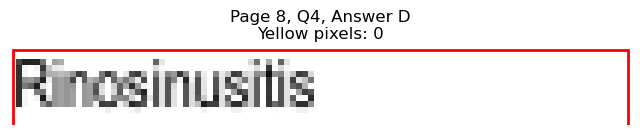


Page 8, Q4 - Selected Answer: A (based on yellow pixel count)




Page 8, Q5 - A: Detected box: x0=68.3, y0=404.9, x1=163.6, y1=417.6
Page 8, Q5, A: Yellow pixels: 0
Page 8, Q5, A: Total non-white pixels: 476
Page 8, Q5, A: Yellow percentage: 0.0%


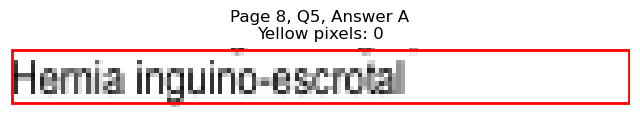

Page 8, Q5 - B: Detected box: x0=68.3, y0=417.6, x1=148.6, y1=430.3
Page 8, Q5, B: Yellow pixels: 0
Page 8, Q5, B: Total non-white pixels: 410
Page 8, Q5, B: Yellow percentage: 0.0%


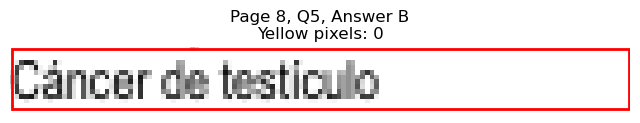

Page 8, Q5 - C: Detected box: x0=327.5, y0=404.9, x1=390.2, y1=417.6
Page 8, Q5, C: Yellow pixels: 1241
Page 8, Q5, C: Total non-white pixels: 1596
Page 8, Q5, C: Yellow percentage: 77.8%


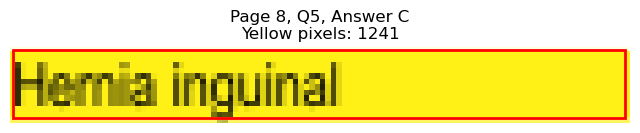

Page 8, Q5 - D: Detected box: x0=327.5, y0=417.6, x1=403.7, y1=430.3
Page 8, Q5, D: Yellow pixels: 125
Page 8, Q5, D: Total non-white pixels: 495
Page 8, Q5, D: Yellow percentage: 25.3%


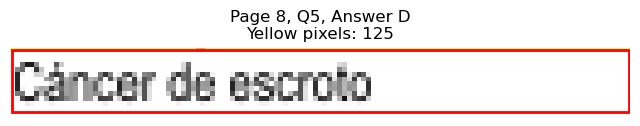


Page 8, Q5 - Selected Answer: C (based on yellow pixel count)




Page 8, Q6 - A: Detected box: x0=68.3, y0=493.4, x1=233.3, y1=506.0
Page 8, Q6, A: Yellow pixels: 2082
Page 8, Q6, A: Total non-white pixels: 2787
Page 8, Q6, A: Yellow percentage: 74.7%


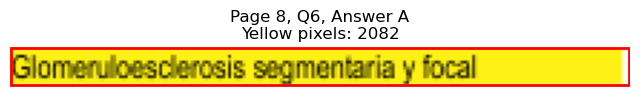

Page 8, Q6 - B: Detected box: x0=68.3, y0=506.0, x1=232.4, y1=518.6
Page 8, Q6, B: Yellow pixels: 207
Page 8, Q6, B: Total non-white pixels: 1028
Page 8, Q6, B: Yellow percentage: 20.1%


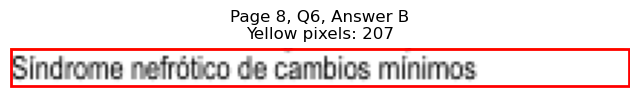

Page 8, Q6 - C: Detected box: x0=327.5, y0=493.4, x1=468.5, y1=506.0
Page 8, Q6, C: Yellow pixels: 0
Page 8, Q6, C: Total non-white pixels: 723
Page 8, Q6, C: Yellow percentage: 0.0%


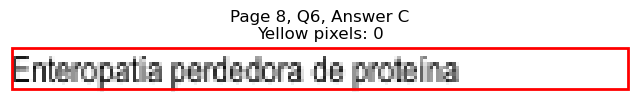

Page 8, Q6 - D: Detected box: x0=327.5, y0=506.0, x1=425.8, y1=518.6
Page 8, Q6, D: Yellow pixels: 0
Page 8, Q6, D: Total non-white pixels: 527
Page 8, Q6, D: Yellow percentage: 0.0%


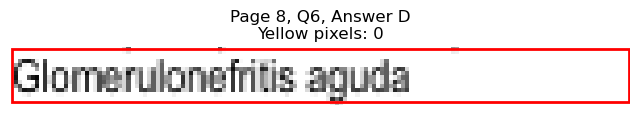


Page 8, Q6 - Selected Answer: A (based on yellow pixel count)




Page 8, Q7 - A: Detected box: x0=68.3, y0=556.5, x1=104.4, y1=569.2
Page 8, Q7, A: Yellow pixels: 87
Page 8, Q7, A: Total non-white pixels: 297
Page 8, Q7, A: Yellow percentage: 29.3%


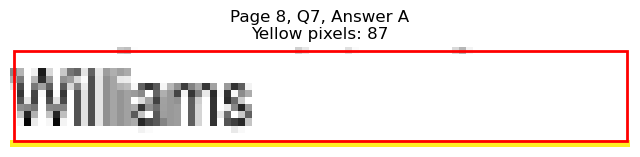

Page 8, Q7 - B: Detected box: x0=68.3, y0=569.1, x1=158.1, y1=581.8
Page 8, Q7, B: Yellow pixels: 1448
Page 8, Q7, B: Total non-white pixels: 1833
Page 8, Q7, B: Yellow percentage: 79.0%


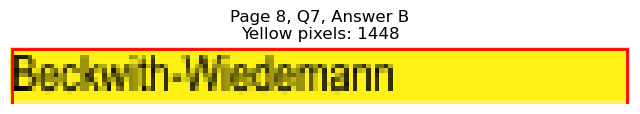

Page 8, Q7 - C: Detected box: x0=327.5, y0=556.5, x1=368.7, y1=569.2
Page 8, Q7, C: Yellow pixels: 0
Page 8, Q7, C: Total non-white pixels: 227
Page 8, Q7, C: Yellow percentage: 0.0%


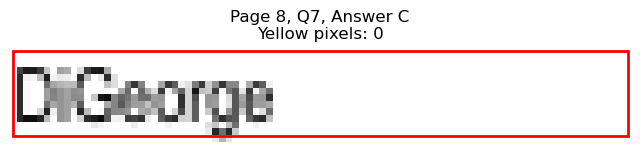

Page 8, Q7 - D: Detected box: x0=327.5, y0=569.1, x1=365.1, y1=581.8
Page 8, Q7, D: Yellow pixels: 0
Page 8, Q7, D: Total non-white pixels: 192
Page 8, Q7, D: Yellow percentage: 0.0%


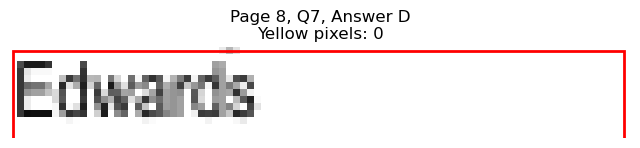


Page 8, Q7 - Selected Answer: B (based on yellow pixel count)




Page 8, Q8 - A: Detected box: x0=68.3, y0=606.9, x1=290.0, y1=619.6
Page 8, Q8, A: Yellow pixels: 0
Page 8, Q8, A: Total non-white pixels: 1104
Page 8, Q8, A: Yellow percentage: 0.0%


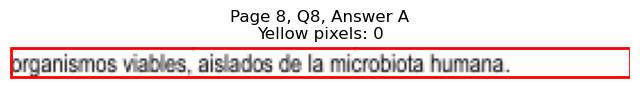

Page 8, Q8 - B: Detected box: x0=68.3, y0=619.6, x1=118.0, y1=632.3
Page 8, Q8, B: Yellow pixels: 1022
Page 8, Q8, B: Total non-white pixels: 1400
Page 8, Q8, B: Yellow percentage: 73.0%


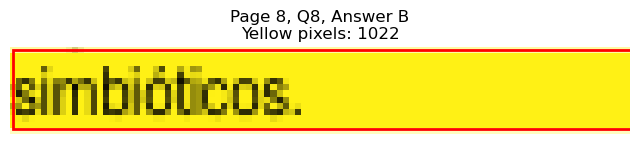

Page 8, Q8 - C: Detected box: x0=68.8, y0=632.2, x1=295.0, y1=644.9
Page 8, Q8, C: Yellow pixels: 0
Page 8, Q8, C: Total non-white pixels: 1423
Page 8, Q8, C: Yellow percentage: 0.0%


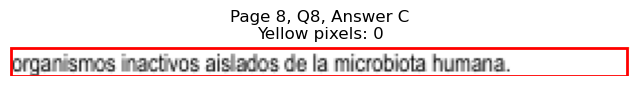

Page 8, Q8 - D: Detected box: x0=68.8, y0=644.9, x1=318.2, y1=657.5
Page 8, Q8, D: Yellow pixels: 0
Page 8, Q8, D: Total non-white pixels: 1244
Page 8, Q8, D: Yellow percentage: 0.0%


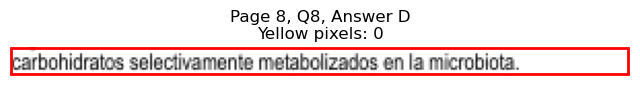


Page 8, Q8 - Selected Answer: B (based on yellow pixel count)




Page 8, Q9 - A: Detected box: x0=68.3, y0=720.6, x1=218.8, y1=733.2
Page 8, Q9, A: Yellow pixels: 0
Page 8, Q9, A: Total non-white pixels: 761
Page 8, Q9, A: Yellow percentage: 0.0%


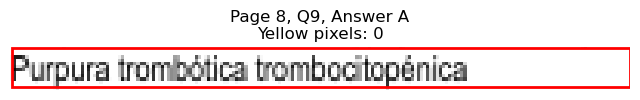

Page 8, Q9 - B: Detected box: x0=68.3, y0=733.2, x1=185.2, y1=745.8
Page 8, Q9, B: Yellow pixels: 0
Page 8, Q9, B: Total non-white pixels: 607
Page 8, Q9, B: Yellow percentage: 0.0%


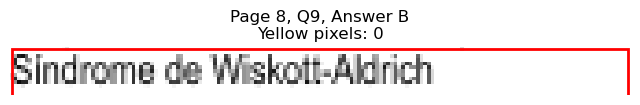

Page 8, Q9 - C: Detected box: x0=327.5, y0=720.6, x1=464.3, y1=733.2
Page 8, Q9, C: Yellow pixels: 1927
Page 8, Q9, C: Total non-white pixels: 2632
Page 8, Q9, C: Yellow percentage: 73.2%


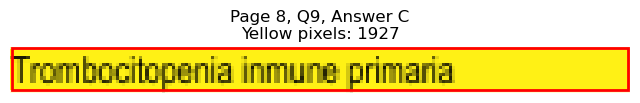

Page 8, Q9 - D: Detected box: x0=327.5, y0=733.2, x1=488.5, y1=745.8
Page 8, Q9, D: Yellow pixels: 0
Page 8, Q9, D: Total non-white pixels: 1010
Page 8, Q9, D: Yellow percentage: 0.0%


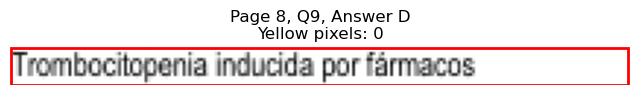


Page 8, Q9 - Selected Answer: C (based on yellow pixel count)





Page 9: Found 10 questions
Page 9, Q1 - A: Detected box: x0=68.3, y0=114.6, x1=158.1, y1=127.3
Page 9, Q1, A: Yellow pixels: 0
Page 9, Q1, A: Total non-white pixels: 454
Page 9, Q1, A: Yellow percentage: 0.0%


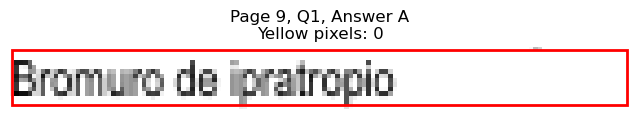

Page 9, Q1 - B: Detected box: x0=68.3, y0=127.2, x1=151.6, y1=139.9
Page 9, Q1, B: Yellow pixels: 0
Page 9, Q1, B: Total non-white pixels: 438
Page 9, Q1, B: Yellow percentage: 0.0%


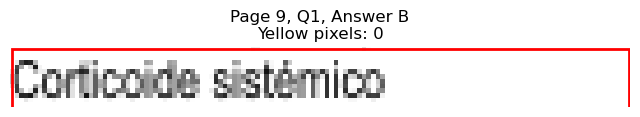

Page 9, Q1 - C: Detected box: x0=327.5, y0=114.6, x1=463.0, y1=127.3
Page 9, Q1, C: Yellow pixels: 187
Page 9, Q1, C: Total non-white pixels: 884
Page 9, Q1, C: Yellow percentage: 21.2%


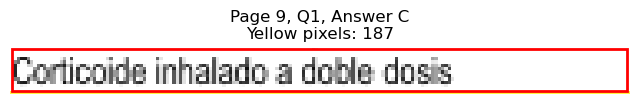

Page 9, Q1 - D: Detected box: x0=327.5, y0=127.2, x1=462.1, y1=139.9
Page 9, Q1, D: Yellow pixels: 1908
Page 9, Q1, D: Total non-white pixels: 2418
Page 9, Q1, D: Yellow percentage: 78.9%


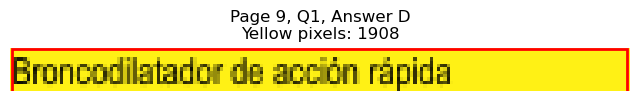


Page 9, Q1 - Selected Answer: D (based on yellow pixel count)




Page 9, Q2 - A: Detected box: x0=68.3, y0=165.1, x1=217.2, y1=177.8
Page 9, Q2, A: Yellow pixels: 0
Page 9, Q2, A: Total non-white pixels: 739
Page 9, Q2, A: Yellow percentage: 0.0%


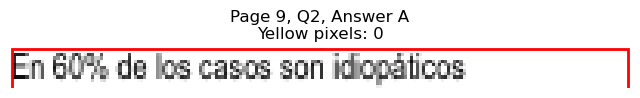

Page 9, Q2 - B: Detected box: x0=68.3, y0=177.7, x1=338.1, y1=190.4
Page 9, Q2, B: Yellow pixels: 321
Page 9, Q2, B: Total non-white pixels: 1610
Page 9, Q2, B: Yellow percentage: 19.9%


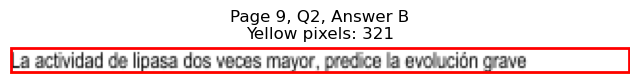

Page 9, Q2 - C: Detected box: x0=68.8, y0=190.3, x1=290.9, y1=203.0
Page 9, Q2, C: Yellow pixels: 2667
Page 9, Q2, C: Total non-white pixels: 3549
Page 9, Q2, C: Yellow percentage: 75.1%


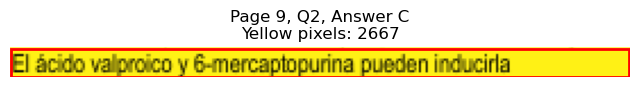

Page 9, Q2 - D: Detected box: x0=68.8, y0=202.9, x1=256.8, y1=215.6
Page 9, Q2, D: Yellow pixels: 230
Page 9, Q2, D: Total non-white pixels: 1131
Page 9, Q2, D: Yellow percentage: 20.3%


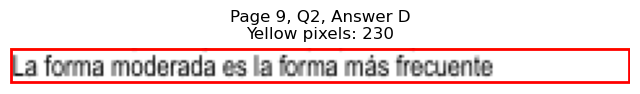


Page 9, Q2 - Selected Answer: C (based on yellow pixel count)




Page 9, Q3 - A: Detected box: x0=68.3, y0=266.1, x1=220.7, y1=278.7
Page 9, Q3, A: Yellow pixels: 0
Page 9, Q3, A: Total non-white pixels: 738
Page 9, Q3, A: Yellow percentage: 0.0%


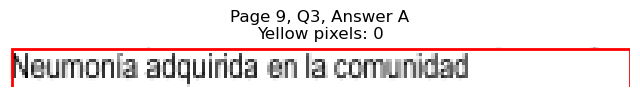

Page 9, Q3 - B: Detected box: x0=68.3, y0=278.8, x1=143.1, y1=291.5
Page 9, Q3, B: Yellow pixels: 1333
Page 9, Q3, B: Total non-white pixels: 1764
Page 9, Q3, B: Yellow percentage: 75.6%


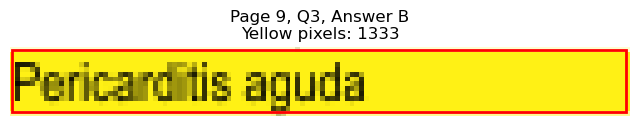

Page 9, Q3 - C: Detected box: x0=327.5, y0=266.1, x1=416.8, y1=278.7
Page 9, Q3, C: Yellow pixels: 0
Page 9, Q3, C: Total non-white pixels: 470
Page 9, Q3, C: Yellow percentage: 0.0%


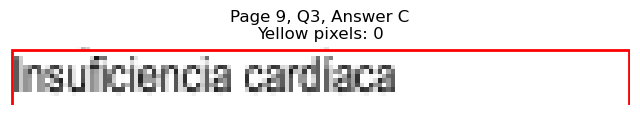

Page 9, Q3 - D: Detected box: x0=327.5, y0=278.8, x1=387.2, y1=291.5
Page 9, Q3, D: Yellow pixels: 0
Page 9, Q3, D: Total non-white pixels: 319
Page 9, Q3, D: Yellow percentage: 0.0%


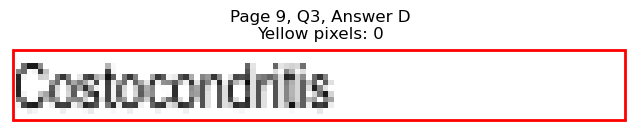


Page 9, Q3 - Selected Answer: B (based on yellow pixel count)




Page 9, Q4 - A: Detected box: x0=68.3, y0=341.9, x1=135.0, y1=354.6
Page 9, Q4, A: Yellow pixels: 118
Page 9, Q4, A: Total non-white pixels: 472
Page 9, Q4, A: Yellow percentage: 25.0%


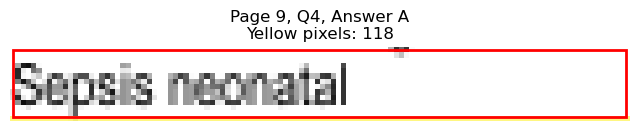

Page 9, Q4 - B: Detected box: x0=68.3, y0=354.5, x1=127.0, y1=367.2
Page 9, Q4, B: Yellow pixels: 1188
Page 9, Q4, B: Total non-white pixels: 1526
Page 9, Q4, B: Yellow percentage: 77.9%


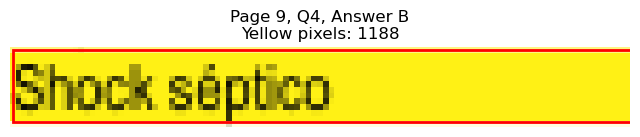

Page 9, Q4 - C: Detected box: x0=327.5, y0=341.9, x1=398.8, y1=354.6
Page 9, Q4, C: Yellow pixels: 0
Page 9, Q4, C: Total non-white pixels: 367
Page 9, Q4, C: Yellow percentage: 0.0%


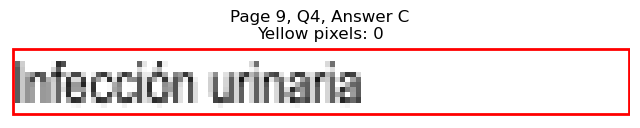

Page 9, Q4 - D: Detected box: x0=327.5, y0=354.5, x1=371.7, y1=367.2
Page 9, Q4, D: Yellow pixels: 0
Page 9, Q4, D: Total non-white pixels: 221
Page 9, Q4, D: Yellow percentage: 0.0%


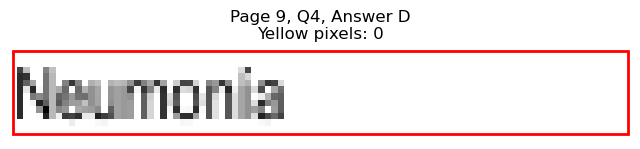


Page 9, Q4 - Selected Answer: B (based on yellow pixel count)




Page 9, Q5 - A: Detected box: x0=68.3, y0=404.9, x1=132.0, y1=417.6
Page 9, Q5, A: Yellow pixels: 0
Page 9, Q5, A: Total non-white pixels: 338
Page 9, Q5, A: Yellow percentage: 0.0%


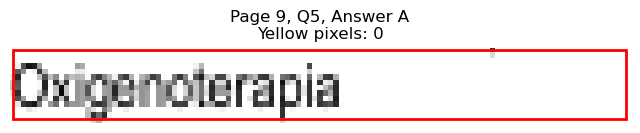

Page 9, Q5 - B: Detected box: x0=68.3, y0=417.6, x1=155.5, y1=430.3
Page 9, Q5, B: Yellow pixels: 1289
Page 9, Q5, B: Total non-white pixels: 1932
Page 9, Q5, B: Yellow percentage: 66.7%


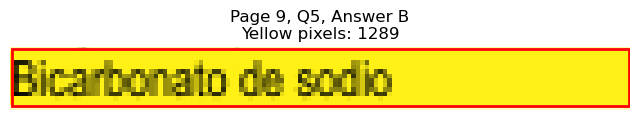

Page 9, Q5 - C: Detected box: x0=327.5, y0=404.9, x1=360.2, y1=417.6
Page 9, Q5, C: Yellow pixels: 0
Page 9, Q5, C: Total non-white pixels: 172
Page 9, Q5, C: Yellow percentage: 0.0%


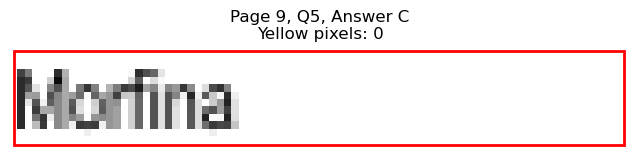

Page 9, Q5 - D: Detected box: x0=327.5, y0=417.6, x1=385.7, y1=430.3
Page 9, Q5, D: Yellow pixels: 0
Page 9, Q5, D: Total non-white pixels: 299
Page 9, Q5, D: Yellow percentage: 0.0%


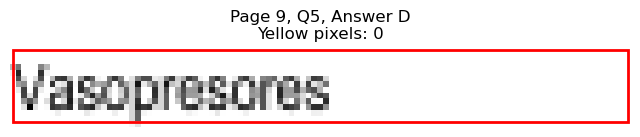


Page 9, Q5 - Selected Answer: B (based on yellow pixel count)




Page 9, Q6 - A: Detected box: x0=68.3, y0=480.8, x1=209.2, y1=493.4
Page 9, Q6, A: Yellow pixels: 1771
Page 9, Q6, A: Total non-white pixels: 2688
Page 9, Q6, A: Yellow percentage: 65.9%


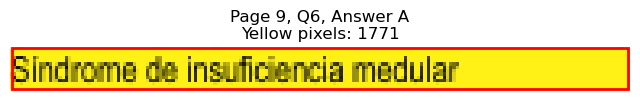

Page 9, Q6 - B: Detected box: x0=68.3, y0=493.4, x1=200.2, y1=506.0
Page 9, Q6, B: Yellow pixels: 0
Page 9, Q6, B: Total non-white pixels: 835
Page 9, Q6, B: Yellow percentage: 0.0%


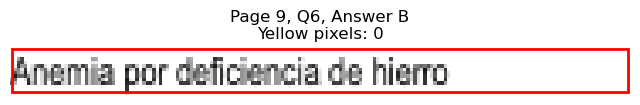

Page 9, Q6 - C: Detected box: x0=327.5, y0=480.8, x1=423.3, y1=493.4
Page 9, Q6, C: Yellow pixels: 0
Page 9, Q6, C: Total non-white pixels: 516
Page 9, Q6, C: Yellow percentage: 0.0%


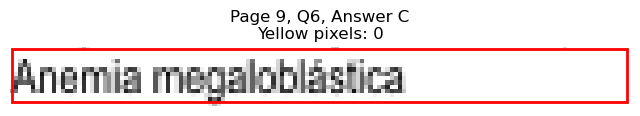

Page 9, Q6 - D: Detected box: x0=327.5, y0=493.4, x1=453.9, y1=506.0
Page 9, Q6, D: Yellow pixels: 0
Page 9, Q6, D: Total non-white pixels: 620
Page 9, Q6, D: Yellow percentage: 0.0%


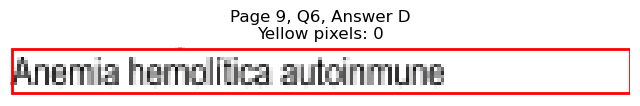


Page 9, Q6 - Selected Answer: A (based on yellow pixel count)




Page 9, Q7 - A: Detected box: x0=68.3, y0=531.2, x1=167.7, y1=543.8
Page 9, Q7, A: Yellow pixels: 0
Page 9, Q7, A: Total non-white pixels: 660
Page 9, Q7, A: Yellow percentage: 0.0%


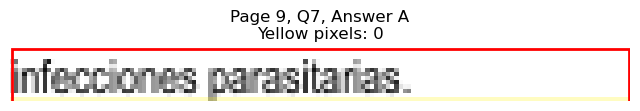

Page 9, Q7 - B: Detected box: x0=68.3, y0=543.8, x1=134.5, y1=556.4
Page 9, Q7, B: Yellow pixels: 1285
Page 9, Q7, B: Total non-white pixels: 1638
Page 9, Q7, B: Yellow percentage: 78.4%


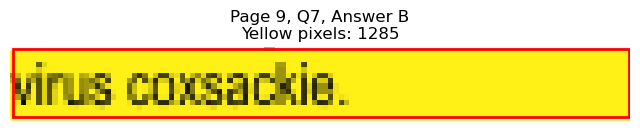

Page 9, Q7 - C: Detected box: x0=327.5, y0=531.2, x1=413.8, y1=543.8
Page 9, Q7, C: Yellow pixels: 0
Page 9, Q7, C: Total non-white pixels: 430
Page 9, Q7, C: Yellow percentage: 0.0%


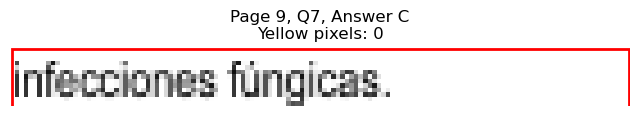

Page 9, Q7 - D: Detected box: x0=327.5, y0=543.8, x1=395.7, y1=556.4
Page 9, Q7, D: Yellow pixels: 0
Page 9, Q7, D: Total non-white pixels: 313
Page 9, Q7, D: Yellow percentage: 0.0%


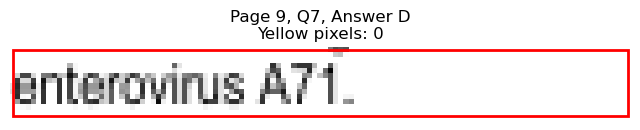


Page 9, Q7 - Selected Answer: B (based on yellow pixel count)




Page 9, Q8 - A: Detected box: x0=68.3, y0=606.9, x1=182.7, y1=619.6
Page 9, Q8, A: Yellow pixels: 0
Page 9, Q8, A: Total non-white pixels: 592
Page 9, Q8, A: Yellow percentage: 0.0%


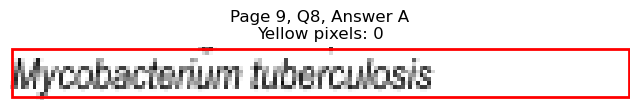

Page 9, Q8 - B: Detected box: x0=68.3, y0=619.6, x1=158.5, y1=632.3
Page 9, Q8, B: Yellow pixels: 0
Page 9, Q8, B: Total non-white pixels: 449
Page 9, Q8, B: Yellow percentage: 0.0%


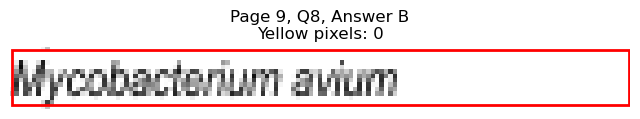

Page 9, Q8 - C: Detected box: x0=327.5, y0=606.9, x1=420.3, y1=619.6
Page 9, Q8, C: Yellow pixels: 0
Page 9, Q8, C: Total non-white pixels: 501
Page 9, Q8, C: Yellow percentage: 0.0%


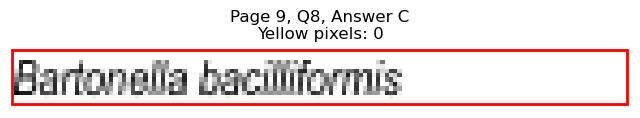

Page 9, Q8 - D: Detected box: x0=327.5, y0=619.6, x1=409.9, y1=632.3
Page 9, Q8, D: Yellow pixels: 1252
Page 9, Q8, D: Total non-white pixels: 1862
Page 9, Q8, D: Yellow percentage: 67.2%


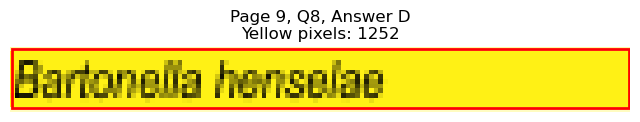


Page 9, Q8 - Selected Answer: D (based on yellow pixel count)




Page 9, Q9 - A: Detected box: x0=68.3, y0=657.5, x1=172.6, y1=670.1
Page 9, Q9, A: Yellow pixels: 0
Page 9, Q9, A: Total non-white pixels: 519
Page 9, Q9, A: Yellow percentage: 0.0%


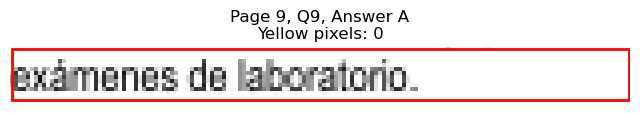

Page 9, Q9 - B: Detected box: x0=68.3, y0=670.1, x1=91.8, y1=682.7
Page 9, Q9, B: Yellow pixels: 0
Page 9, Q9, B: Total non-white pixels: 109
Page 9, Q9, B: Yellow percentage: 0.0%


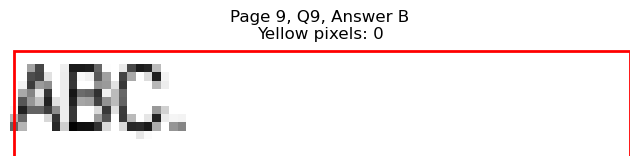

Page 9, Q9 - C: Detected box: x0=327.5, y0=657.5, x1=475.5, y1=670.1
Page 9, Q9, C: Yellow pixels: 2048
Page 9, Q9, C: Total non-white pixels: 2786
Page 9, Q9, C: Yellow percentage: 73.5%


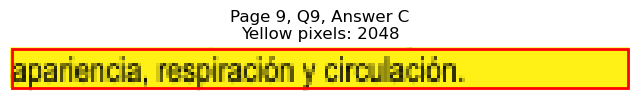

Page 9, Q9 - D: Detected box: x0=327.5, y0=670.1, x1=363.7, y1=682.7
Page 9, Q9, D: Yellow pixels: 0
Page 9, Q9, D: Total non-white pixels: 260
Page 9, Q9, D: Yellow percentage: 0.0%


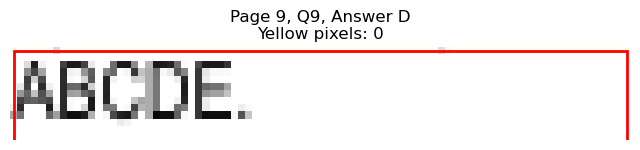


Page 9, Q9 - Selected Answer: C (based on yellow pixel count)




Page 9, Q10 - A: Detected box: x0=68.3, y0=708.0, x1=359.2, y1=720.6
Page 9, Q10, A: Yellow pixels: 342
Page 9, Q10, A: Total non-white pixels: 1811
Page 9, Q10, A: Yellow percentage: 18.9%


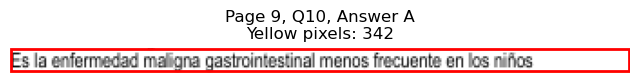

Page 9, Q10 - B: Detected box: x0=68.3, y0=720.6, x1=384.3, y1=733.2
Page 9, Q10, B: Yellow pixels: 3583
Page 9, Q10, B: Total non-white pixels: 5138
Page 9, Q10, B: Yellow percentage: 69.7%


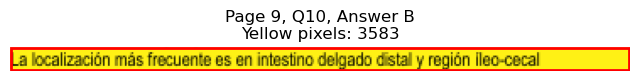

Page 9, Q10 - C: Detected box: x0=68.8, y0=733.2, x1=338.1, y1=745.8
Page 9, Q10, C: Yellow pixels: 0
Page 9, Q10, C: Total non-white pixels: 1651
Page 9, Q10, C: Yellow percentage: 0.0%


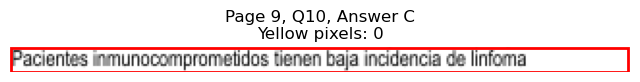

Page 9, Q10 - D: Detected box: x0=68.8, y0=745.8, x1=444.5, y1=758.4
Page 9, Q10, D: Yellow pixels: 0
Page 9, Q10, D: Total non-white pixels: 1854
Page 9, Q10, D: Yellow percentage: 0.0%


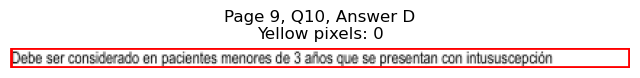


Page 9, Q10 - Selected Answer: B (based on yellow pixel count)





Page 10: Found 9 questions
Page 10, Q1 - A: Detected box: x0=68.3, y0=114.6, x1=170.7, y1=127.3
Page 10, Q1, A: Yellow pixels: 1452
Page 10, Q1, A: Total non-white pixels: 2142
Page 10, Q1, A: Yellow percentage: 67.8%


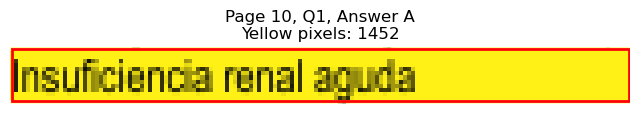

Page 10, Q1 - B: Detected box: x0=68.3, y0=127.2, x1=211.7, y1=139.9
Page 10, Q1, B: Yellow pixels: 0
Page 10, Q1, B: Total non-white pixels: 900
Page 10, Q1, B: Yellow percentage: 0.0%


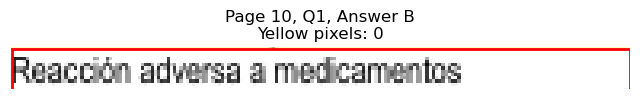

Page 10, Q1 - C: Detected box: x0=327.5, y0=114.6, x1=440.8, y1=127.3
Page 10, Q1, C: Yellow pixels: 0
Page 10, Q1, C: Total non-white pixels: 588
Page 10, Q1, C: Yellow percentage: 0.0%


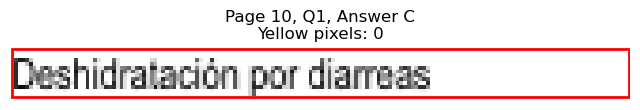

Page 10, Q1 - D: Detected box: x0=327.5, y0=127.2, x1=369.2, y1=139.9
Page 10, Q1, D: Yellow pixels: 0
Page 10, Q1, D: Total non-white pixels: 218
Page 10, Q1, D: Yellow percentage: 0.0%


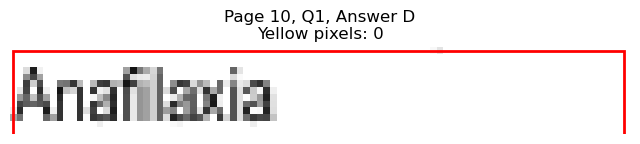


Page 10, Q1 - Selected Answer: A (based on yellow pixel count)




Page 10, Q2 - A: Detected box: x0=68.3, y0=190.3, x1=149.1, y1=203.0
Page 10, Q2, A: Yellow pixels: 0
Page 10, Q2, A: Total non-white pixels: 420
Page 10, Q2, A: Yellow percentage: 0.0%


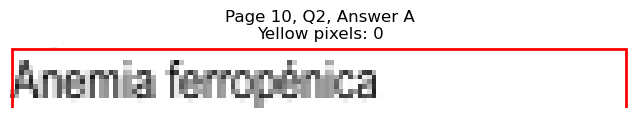

Page 10, Q2 - B: Detected box: x0=68.3, y0=202.9, x1=145.0, y1=215.6
Page 10, Q2, B: Yellow pixels: 0
Page 10, Q2, B: Total non-white pixels: 395
Page 10, Q2, B: Yellow percentage: 0.0%


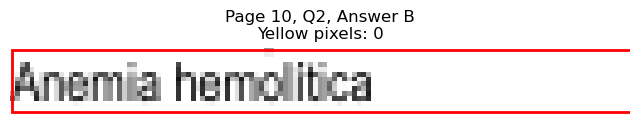

Page 10, Q2 - C: Detected box: x0=327.5, y0=190.3, x1=423.3, y1=203.0
Page 10, Q2, C: Yellow pixels: 1508
Page 10, Q2, C: Total non-white pixels: 1911
Page 10, Q2, C: Yellow percentage: 78.9%


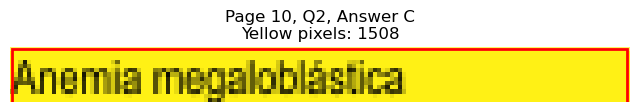

Page 10, Q2 - D: Detected box: x0=327.5, y0=202.9, x1=426.3, y1=215.6
Page 10, Q2, D: Yellow pixels: 146
Page 10, Q2, D: Total non-white pixels: 674
Page 10, Q2, D: Yellow percentage: 21.7%


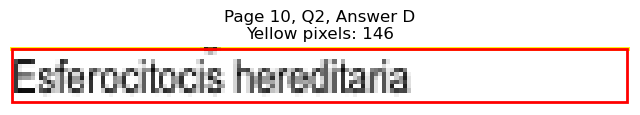


Page 10, Q2 - Selected Answer: C (based on yellow pixel count)




Page 10, Q3 - A: Detected box: x0=68.3, y0=266.1, x1=146.5, y1=278.7
Page 10, Q3, A: Yellow pixels: 0
Page 10, Q3, A: Total non-white pixels: 441
Page 10, Q3, A: Yellow percentage: 0.0%


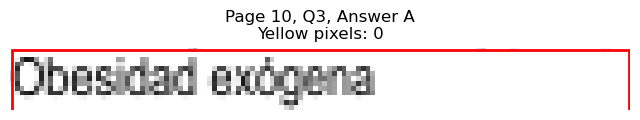

Page 10, Q3 - B: Detected box: x0=68.3, y0=278.8, x1=169.6, y1=291.5
Page 10, Q3, B: Yellow pixels: 0
Page 10, Q3, B: Total non-white pixels: 514
Page 10, Q3, B: Yellow percentage: 0.0%


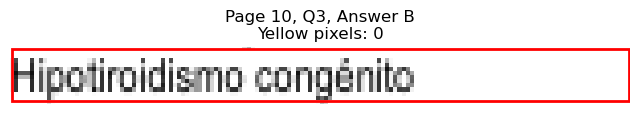

Page 10, Q3 - C: Detected box: x0=327.5, y0=266.1, x1=430.9, y1=278.7
Page 10, Q3, C: Yellow pixels: 1569
Page 10, Q3, C: Total non-white pixels: 2002
Page 10, Q3, C: Yellow percentage: 78.4%


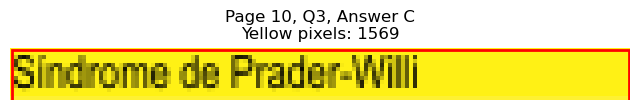

Page 10, Q3 - D: Detected box: x0=327.5, y0=278.8, x1=424.9, y1=291.5
Page 10, Q3, D: Yellow pixels: 148
Page 10, Q3, D: Total non-white pixels: 646
Page 10, Q3, D: Yellow percentage: 22.9%


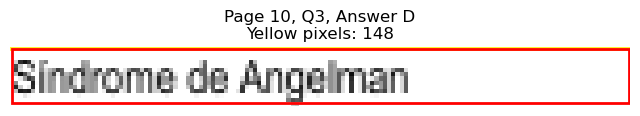


Page 10, Q3 - Selected Answer: C (based on yellow pixel count)




Page 10, Q4 - A: Detected box: x0=68.3, y0=316.6, x1=157.6, y1=329.3
Page 10, Q4, A: Yellow pixels: 140
Page 10, Q4, A: Total non-white pixels: 584
Page 10, Q4, A: Yellow percentage: 24.0%


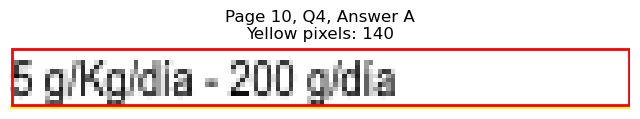

Page 10, Q4 - B: Detected box: x0=68.3, y0=329.2, x1=162.6, y1=341.9
Page 10, Q4, B: Yellow pixels: 1534
Page 10, Q4, B: Total non-white pixels: 1885
Page 10, Q4, B: Yellow percentage: 81.4%


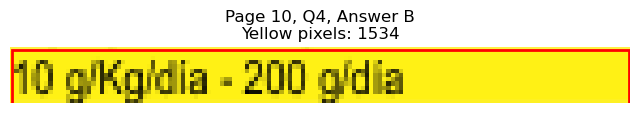

Page 10, Q4 - C: Detected box: x0=327.5, y0=316.6, x1=416.8, y1=329.3
Page 10, Q4, C: Yellow pixels: 0
Page 10, Q4, C: Total non-white pixels: 441
Page 10, Q4, C: Yellow percentage: 0.0%


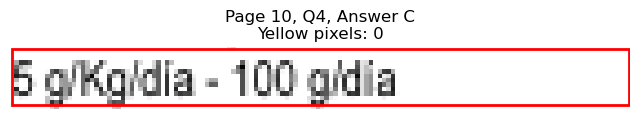

Page 10, Q4 - D: Detected box: x0=327.5, y0=329.2, x1=421.9, y1=341.9
Page 10, Q4, D: Yellow pixels: 0
Page 10, Q4, D: Total non-white pixels: 451
Page 10, Q4, D: Yellow percentage: 0.0%


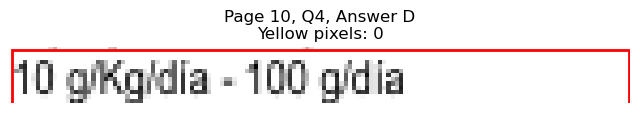


Page 10, Q4 - Selected Answer: B (based on yellow pixel count)




Page 10, Q5 - A: Detected box: x0=68.3, y0=367.1, x1=216.8, y1=379.8
Page 10, Q5, A: Yellow pixels: 2045
Page 10, Q5, A: Total non-white pixels: 2587
Page 10, Q5, A: Yellow percentage: 79.0%


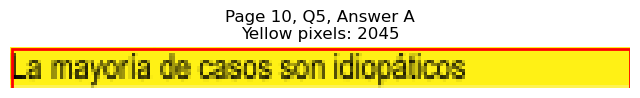

Page 10, Q5 - B: Detected box: x0=68.3, y0=379.7, x1=287.6, y1=392.4
Page 10, Q5, B: Yellow pixels: 269
Page 10, Q5, B: Total non-white pixels: 1355
Page 10, Q5, B: Yellow percentage: 19.9%


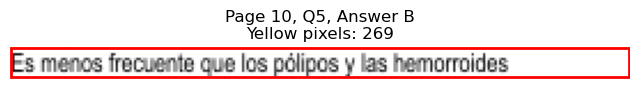

Page 10, Q5 - C: Detected box: x0=68.8, y0=392.3, x1=246.3, y1=405.0
Page 10, Q5, C: Yellow pixels: 0
Page 10, Q5, C: Total non-white pixels: 817
Page 10, Q5, C: Yellow percentage: 0.0%


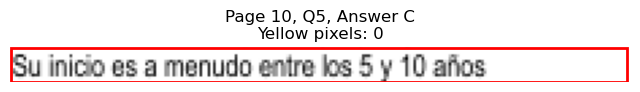

Page 10, Q5 - D: Detected box: x0=68.8, y0=404.9, x1=288.4, y1=417.6
Page 10, Q5, D: Yellow pixels: 0
Page 10, Q5, D: Total non-white pixels: 1082
Page 10, Q5, D: Yellow percentage: 0.0%


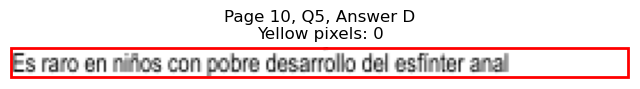


Page 10, Q5 - Selected Answer: A (based on yellow pixel count)




Page 10, Q6 - A: Detected box: x0=68.3, y0=480.8, x1=161.1, y1=493.4
Page 10, Q6, A: Yellow pixels: 1357
Page 10, Q6, A: Total non-white pixels: 2016
Page 10, Q6, A: Yellow percentage: 67.3%


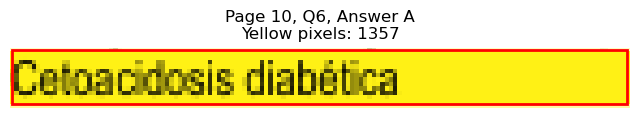

Page 10, Q6 - B: Detected box: x0=68.3, y0=493.4, x1=173.7, y1=506.0
Page 10, Q6, B: Yellow pixels: 0
Page 10, Q6, B: Total non-white pixels: 710
Page 10, Q6, B: Yellow percentage: 0.0%


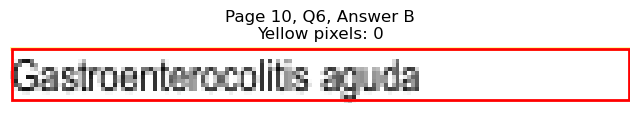

Page 10, Q6 - C: Detected box: x0=327.5, y0=480.8, x1=408.8, y1=493.4
Page 10, Q6, C: Yellow pixels: 0
Page 10, Q6, C: Total non-white pixels: 409
Page 10, Q6, C: Yellow percentage: 0.0%


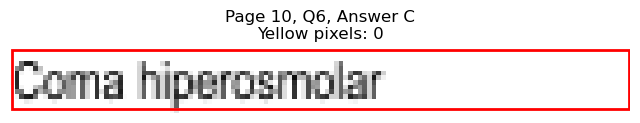

Page 10, Q6 - D: Detected box: x0=327.5, y0=493.4, x1=454.5, y1=506.0
Page 10, Q6, D: Yellow pixels: 0
Page 10, Q6, D: Total non-white pixels: 657
Page 10, Q6, D: Yellow percentage: 0.0%


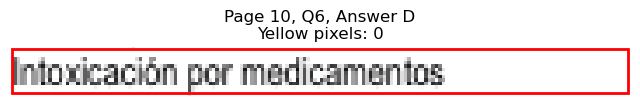


Page 10, Q6 - Selected Answer: A (based on yellow pixel count)




Page 10, Q7 - A: Detected box: x0=68.3, y0=569.1, x1=102.9, y1=581.8
Page 10, Q7, A: Yellow pixels: 961
Page 10, Q7, A: Total non-white pixels: 1105
Page 10, Q7, A: Yellow percentage: 87.0%


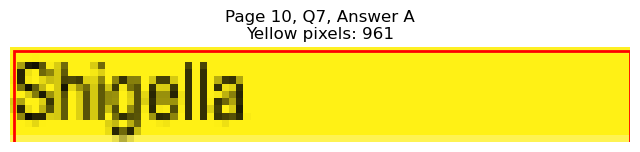

Page 10, Q7 - B: Detected box: x0=68.3, y0=581.7, x1=131.5, y1=594.4
Page 10, Q7, B: Yellow pixels: 113
Page 10, Q7, B: Total non-white pixels: 449
Page 10, Q7, B: Yellow percentage: 25.2%


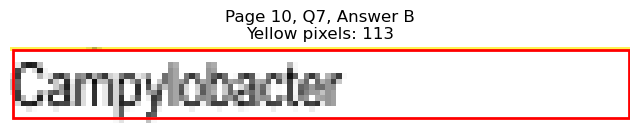

Page 10, Q7 - C: Detected box: x0=327.5, y0=569.1, x1=392.7, y1=581.8
Page 10, Q7, C: Yellow pixels: 0
Page 10, Q7, C: Total non-white pixels: 336
Page 10, Q7, C: Yellow percentage: 0.0%


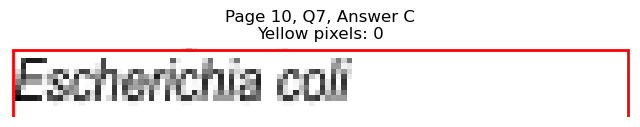

Page 10, Q7 - D: Detected box: x0=327.5, y0=581.7, x1=390.2, y1=594.4
Page 10, Q7, D: Yellow pixels: 0
Page 10, Q7, D: Total non-white pixels: 308
Page 10, Q7, D: Yellow percentage: 0.0%


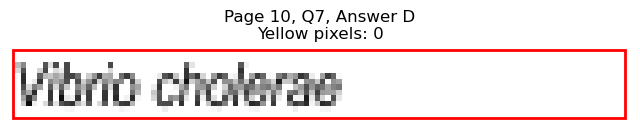


Page 10, Q7 - Selected Answer: A (based on yellow pixel count)




Page 10, Q8 - A: Detected box: x0=68.3, y0=619.6, x1=157.6, y1=632.3
Page 10, Q8, A: Yellow pixels: 0
Page 10, Q8, A: Total non-white pixels: 382
Page 10, Q8, A: Yellow percentage: 0.0%


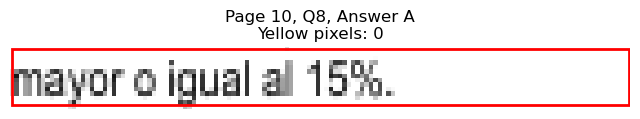

Page 10, Q8 - B: Detected box: x0=68.3, y0=632.2, x1=100.9, y1=644.9
Page 10, Q8, B: Yellow pixels: 0
Page 10, Q8, B: Total non-white pixels: 166
Page 10, Q8, B: Yellow percentage: 0.0%


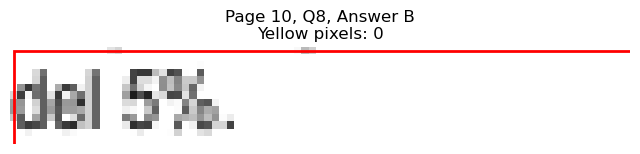

Page 10, Q8 - C: Detected box: x0=327.5, y0=619.6, x1=365.2, y1=632.3
Page 10, Q8, C: Yellow pixels: 89
Page 10, Q8, C: Total non-white pixels: 260
Page 10, Q8, C: Yellow percentage: 34.2%


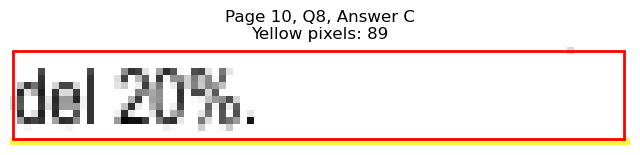

Page 10, Q8 - D: Detected box: x0=327.5, y0=632.2, x1=416.8, y1=644.9
Page 10, Q8, D: Yellow pixels: 1523
Page 10, Q8, D: Total non-white pixels: 1820
Page 10, Q8, D: Yellow percentage: 83.7%


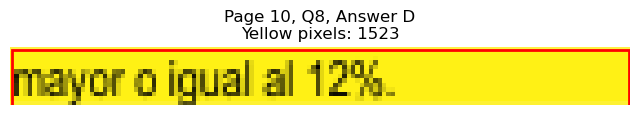


Page 10, Q8 - Selected Answer: D (based on yellow pixel count)




Page 10, Q9 - A: Detected box: x0=68.3, y0=695.4, x1=156.0, y1=708.0
Page 10, Q9, A: Yellow pixels: 0
Page 10, Q9, A: Total non-white pixels: 443
Page 10, Q9, A: Yellow percentage: 0.0%


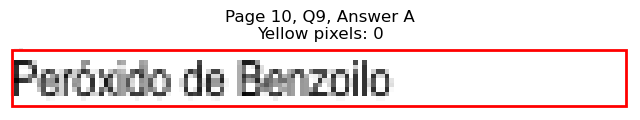

Page 10, Q9 - B: Detected box: x0=68.3, y0=708.0, x1=138.0, y1=720.6
Page 10, Q9, B: Yellow pixels: 0
Page 10, Q9, B: Total non-white pixels: 346
Page 10, Q9, B: Yellow percentage: 0.0%


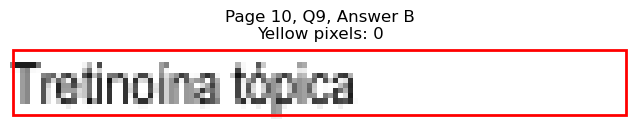

Page 10, Q9 - C: Detected box: x0=327.5, y0=695.4, x1=377.7, y1=708.0
Page 10, Q9, C: Yellow pixels: 101
Page 10, Q9, C: Total non-white pixels: 451
Page 10, Q9, C: Yellow percentage: 22.4%


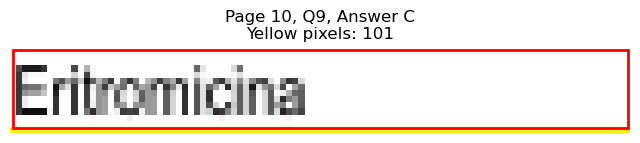

Page 10, Q9 - D: Detected box: x0=327.5, y0=708.0, x1=377.3, y1=720.6
Page 10, Q9, D: Yellow pixels: 1102
Page 10, Q9, D: Total non-white pixels: 1414
Page 10, Q9, D: Yellow percentage: 77.9%


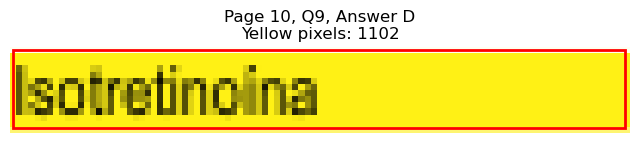


Page 10, Q9 - Selected Answer: D (based on yellow pixel count)





Page 11: Found 7 questions
Page 11, Q1 - A: Detected box: x0=68.3, y0=102.0, x1=80.9, y1=114.7
Page 11, Q1, A: Yellow pixels: 0
Page 11, Q1, A: Total non-white pixels: 52
Page 11, Q1, A: Yellow percentage: 0.0%


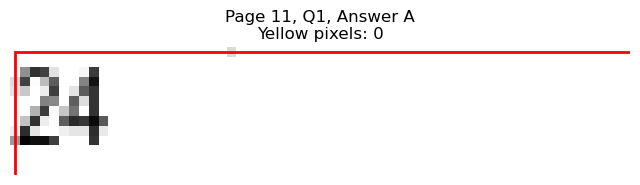

Page 11, Q1 - B: Detected box: x0=68.3, y0=114.6, x1=80.9, y1=127.3
Page 11, Q1, B: Yellow pixels: 0
Page 11, Q1, B: Total non-white pixels: 52
Page 11, Q1, B: Yellow percentage: 0.0%


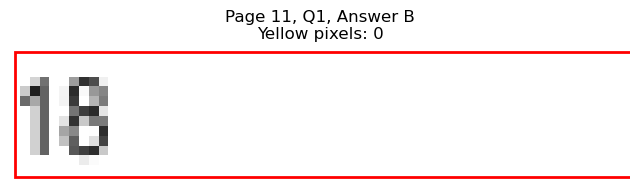

Page 11, Q1 - C: Detected box: x0=327.5, y0=102.0, x1=340.1, y1=114.7
Page 11, Q1, C: Yellow pixels: 0
Page 11, Q1, C: Total non-white pixels: 125
Page 11, Q1, C: Yellow percentage: 0.0%


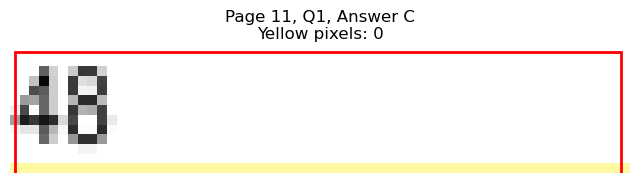

Page 11, Q1 - D: Detected box: x0=327.5, y0=114.6, x1=340.1, y1=127.3
Page 11, Q1, D: Yellow pixels: 735
Page 11, Q1, D: Total non-white pixels: 896
Page 11, Q1, D: Yellow percentage: 82.0%


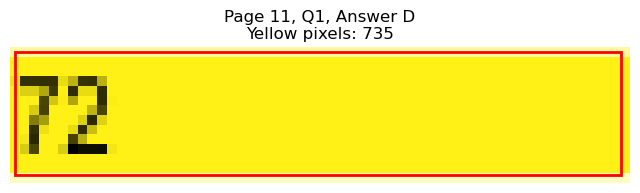


Page 11, Q1 - Selected Answer: D (based on yellow pixel count)




Page 11, Q2 - A: Detected box: x0=68.3, y0=165.1, x1=172.1, y1=177.8
Page 11, Q2, A: Yellow pixels: 0
Page 11, Q2, A: Total non-white pixels: 511
Page 11, Q2, A: Yellow percentage: 0.0%


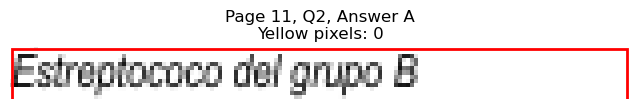

Page 11, Q2 - B: Detected box: x0=68.3, y0=177.7, x1=150.5, y1=190.4
Page 11, Q2, B: Yellow pixels: 0
Page 11, Q2, B: Total non-white pixels: 405
Page 11, Q2, B: Yellow percentage: 0.0%


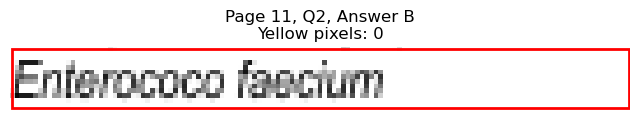

Page 11, Q2 - C: Detected box: x0=327.5, y0=165.1, x1=431.3, y1=177.8
Page 11, Q2, C: Yellow pixels: 1617
Page 11, Q2, C: Total non-white pixels: 2015
Page 11, Q2, C: Yellow percentage: 80.2%


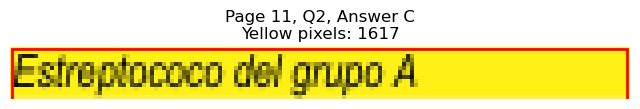

Page 11, Q2 - D: Detected box: x0=327.5, y0=177.7, x1=408.8, y1=190.4
Page 11, Q2, D: Yellow pixels: 131
Page 11, Q2, D: Total non-white pixels: 536
Page 11, Q2, D: Yellow percentage: 24.4%


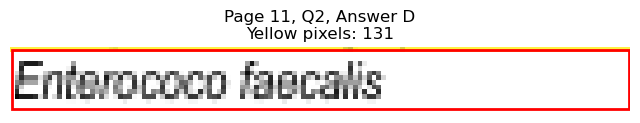


Page 11, Q2 - Selected Answer: C (based on yellow pixel count)




Page 11, Q3 - A: Detected box: x0=68.3, y0=240.9, x1=188.2, y1=253.5
Page 11, Q3, A: Yellow pixels: 171
Page 11, Q3, A: Total non-white pixels: 766
Page 11, Q3, A: Yellow percentage: 22.3%


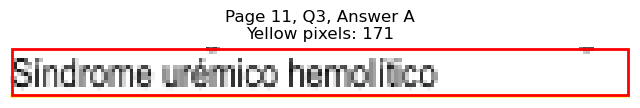

Page 11, Q3 - B: Detected box: x0=68.3, y0=253.5, x1=144.5, y1=266.1
Page 11, Q3, B: Yellow pixels: 1340
Page 11, Q3, B: Total non-white pixels: 1778
Page 11, Q3, B: Yellow percentage: 75.4%


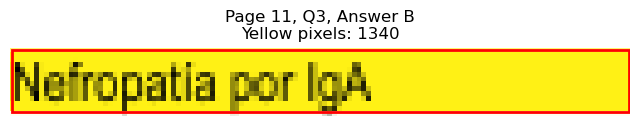

Page 11, Q3 - C: Detected box: x0=327.5, y0=240.9, x1=407.8, y1=253.5
Page 11, Q3, C: Yellow pixels: 0
Page 11, Q3, C: Total non-white pixels: 438
Page 11, Q3, C: Yellow percentage: 0.0%


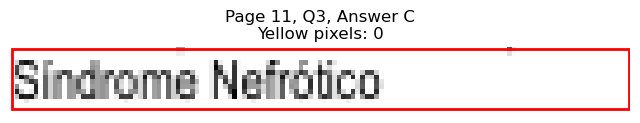

Page 11, Q3 - D: Detected box: x0=327.5, y0=253.5, x1=398.8, y1=266.1
Page 11, Q3, D: Yellow pixels: 0
Page 11, Q3, D: Total non-white pixels: 367
Page 11, Q3, D: Yellow percentage: 0.0%


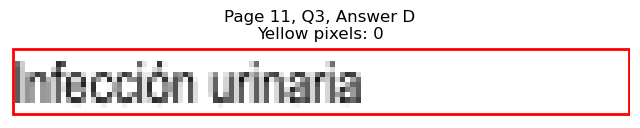


Page 11, Q3 - Selected Answer: B (based on yellow pixel count)




Page 11, Q4 - A: Detected box: x0=68.3, y0=329.2, x1=184.2, y1=341.9
Page 11, Q4, A: Yellow pixels: 0
Page 11, Q4, A: Total non-white pixels: 585
Page 11, Q4, A: Yellow percentage: 0.0%


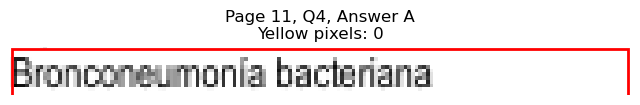

Page 11, Q4 - B: Detected box: x0=68.3, y0=341.9, x1=220.7, y1=354.6
Page 11, Q4, B: Yellow pixels: 0
Page 11, Q4, B: Total non-white pixels: 724
Page 11, Q4, B: Yellow percentage: 0.0%


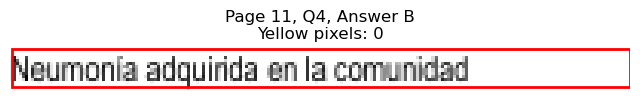

Page 11, Q4 - C: Detected box: x0=327.5, y0=329.2, x1=398.2, y1=341.9
Page 11, Q4, C: Yellow pixels: 1330
Page 11, Q4, C: Total non-white pixels: 1586
Page 11, Q4, C: Yellow percentage: 83.9%


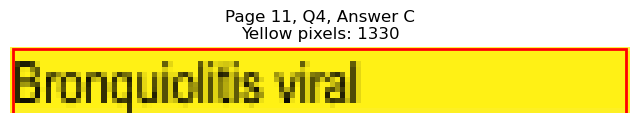

Page 11, Q4 - D: Detected box: x0=327.5, y0=341.9, x1=419.8, y1=354.6
Page 11, Q4, D: Yellow pixels: 142
Page 11, Q4, D: Total non-white pixels: 617
Page 11, Q4, D: Yellow percentage: 23.0%


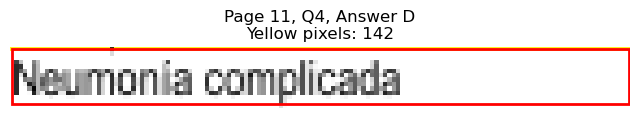


Page 11, Q4 - Selected Answer: C (based on yellow pixel count)




Page 11, Q5 - A: Detected box: x0=68.3, y0=379.7, x1=294.5, y1=392.4
Page 11, Q5, A: Yellow pixels: 277
Page 11, Q5, A: Total non-white pixels: 1345
Page 11, Q5, A: Yellow percentage: 20.6%


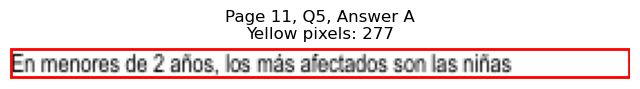

Page 11, Q5 - B: Detected box: x0=68.3, y0=392.3, x1=385.3, y1=405.0
Page 11, Q5, B: Yellow pixels: 3611
Page 11, Q5, B: Total non-white pixels: 4784
Page 11, Q5, B: Yellow percentage: 75.5%


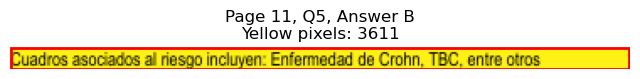

Page 11, Q5 - C: Detected box: x0=68.8, y0=404.9, x1=191.7, y1=417.6
Page 11, Q5, C: Yellow pixels: 168
Page 11, Q5, C: Total non-white pixels: 782
Page 11, Q5, C: Yellow percentage: 21.5%


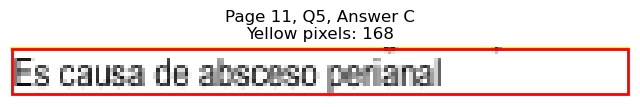

Page 11, Q5 - D: Detected box: x0=68.8, y0=417.6, x1=341.7, y1=430.3
Page 11, Q5, D: Yellow pixels: 0
Page 11, Q5, D: Total non-white pixels: 1309
Page 11, Q5, D: Yellow percentage: 0.0%


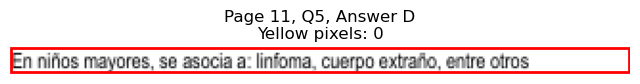


Page 11, Q5 - Selected Answer: B (based on yellow pixel count)




Page 11, Q6 - A: Detected box: x0=68.3, y0=455.5, x1=256.5, y1=468.1
Page 11, Q6, A: Yellow pixels: 239
Page 11, Q6, A: Total non-white pixels: 1178
Page 11, Q6, A: Yellow percentage: 20.3%


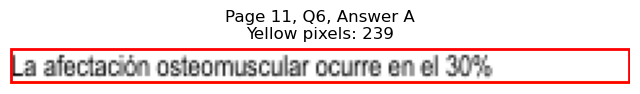

Page 11, Q6 - B: Detected box: x0=68.3, y0=468.1, x1=292.5, y1=480.7
Page 11, Q6, B: Yellow pixels: 2674
Page 11, Q6, B: Total non-white pixels: 3575
Page 11, Q6, B: Yellow percentage: 74.8%


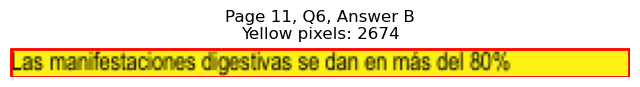

Page 11, Q6 - C: Detected box: x0=68.8, y0=480.8, x1=223.4, y1=493.4
Page 11, Q6, C: Yellow pixels: 205
Page 11, Q6, C: Total non-white pixels: 955
Page 11, Q6, C: Yellow percentage: 21.5%


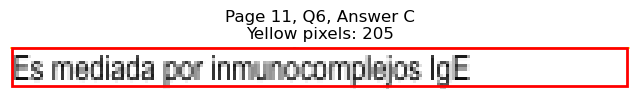

Page 11, Q6 - D: Detected box: x0=68.8, y0=493.4, x1=296.0, y1=506.0
Page 11, Q6, D: Yellow pixels: 0
Page 11, Q6, D: Total non-white pixels: 1139
Page 11, Q6, D: Yellow percentage: 0.0%


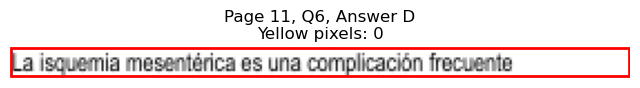


Page 11, Q6 - Selected Answer: B (based on yellow pixel count)




Page 11, Q7 - A: Detected box: x0=68.3, y0=556.5, x1=177.6, y1=569.2
Page 11, Q7, A: Yellow pixels: 160
Page 11, Q7, A: Total non-white pixels: 719
Page 11, Q7, A: Yellow percentage: 22.3%


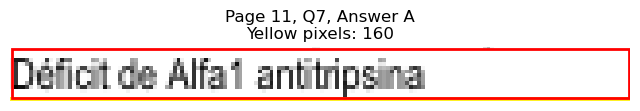

Page 11, Q7 - B: Detected box: x0=68.3, y0=569.1, x1=143.1, y1=581.8
Page 11, Q7, B: Yellow pixels: 1353
Page 11, Q7, B: Total non-white pixels: 1638
Page 11, Q7, B: Yellow percentage: 82.6%


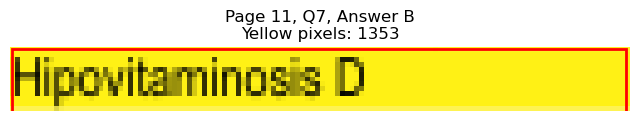

Page 11, Q7 - C: Detected box: x0=327.5, y0=556.5, x1=408.3, y1=569.2
Page 11, Q7, C: Yellow pixels: 0
Page 11, Q7, C: Total non-white pixels: 446
Page 11, Q7, C: Yellow percentage: 0.0%


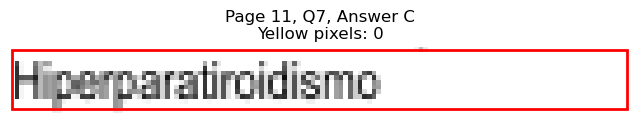

Page 11, Q7 - D: Detected box: x0=327.5, y0=569.1, x1=382.8, y1=581.8
Page 11, Q7, D: Yellow pixels: 0
Page 11, Q7, D: Total non-white pixels: 303
Page 11, Q7, D: Yellow percentage: 0.0%


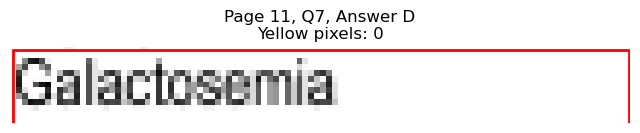


Page 11, Q7 - Selected Answer: B (based on yellow pixel count)






In [6]:
questions_df = extract_questions(pdf_path = pdf_file)
answers_df = extract_answers(pdf_path = pdf_file)
correct_answers_df = extract_correct_answers(pdf_path = pdf_file)

In [7]:
questions_df

,question
0,En la Enfermedad de Kawasaki en niños:
1,¿Cuál de los siguientes es un criterio mayor p...
2,Niño de 7 años desde hace 5 días presenta lesi...
3,Escolar de 8 años acude a emergencia por fiebr...
4,"Adolescente de 12 años, que luego de discusión..."
...,...
95,"Niña de 7 años previamente sana, refiere dolor..."
96,Lactante de 6 meses eutrófico con LME y calend...
97,En relación a la fístula anal en pediatría:
98,En relación a púrpura de Henoch-Schönlein en n...


In [8]:
answers_df

,option_A,option_B,option_C,option_D
0,La resistencia a la IGIV se presenta en un 15%...,La puntuación de Kobayashi es de aplicación mu...,La dosis de carga de IGIV es de 4 g/Kg en infu...,La dosis de carga de IGIV es de 4 g/Kg en infu...
1,Artralgia,Fiebre,Eritema marginado,Faringitis
2,Impétigo ampolloso,Eritema multiforme,Necrolisis epidérmica tóxica,Enfermedad de Ritter
3,Relapso de enfermedad,Neutropenia febril,Reacción a quimioterapicos,Síndrome de lisis tumoral
4,Naloxona,N-acetilcisteina,Dimenhidrinato,Omeprazol
...,...,...,...,...
95,Síndrome urémico hemolítico,Nefropatía por IgA,Síndrome Nefrótico,Infección urinaria
96,Bronconeumonía bacteriana,Neumonía adquirida en la comunidad,Bronquiolitis viral,Neumonía complicada
97,"En menores de 2 años, los más afectados son la...",Cuadros asociados al riesgo incluyen: Enfermed...,Es causa de absceso perianal,"En niños mayores, se asocia a: linfoma, cuerpo..."
98,La afectación osteomuscular ocurre en el 30%,Las manifestaciones digestivas se dan en más d...,Es mediada por inmunocomplejos IgE,La isquemia mesentérica es una complicación fr...


In [9]:
correct_answers_df

,correct_answer
0,A
1,C
2,D
3,B
4,B
...,...
95,B
96,C
97,B
98,B


In [10]:
total_df = pd.concat([questions_df, answers_df, correct_answers_df], ignore_index = True, axis = 1)
total_df.columns = ["questions", "option_A", "option_B", "option_C", "option_D", "correct_answer"]
total_df

,questions,option_A,option_B,option_C,option_D,correct_answer
0,En la Enfermedad de Kawasaki en niños:,La resistencia a la IGIV se presenta en un 15%...,La puntuación de Kobayashi es de aplicación mu...,La dosis de carga de IGIV es de 4 g/Kg en infu...,La dosis de carga de IGIV es de 4 g/Kg en infu...,A
1,¿Cuál de los siguientes es un criterio mayor p...,Artralgia,Fiebre,Eritema marginado,Faringitis,C
2,Niño de 7 años desde hace 5 días presenta lesi...,Impétigo ampolloso,Eritema multiforme,Necrolisis epidérmica tóxica,Enfermedad de Ritter,D
3,Escolar de 8 años acude a emergencia por fiebr...,Relapso de enfermedad,Neutropenia febril,Reacción a quimioterapicos,Síndrome de lisis tumoral,B
4,"Adolescente de 12 años, que luego de discusión...",Naloxona,N-acetilcisteina,Dimenhidrinato,Omeprazol,B
...,...,...,...,...,...,...
95,"Niña de 7 años previamente sana, refiere dolor...",Síndrome urémico hemolítico,Nefropatía por IgA,Síndrome Nefrótico,Infección urinaria,B
96,Lactante de 6 meses eutrófico con LME y calend...,Bronconeumonía bacteriana,Neumonía adquirida en la comunidad,Bronquiolitis viral,Neumonía complicada,C
97,En relación a la fístula anal en pediatría:,"En menores de 2 años, los más afectados son la...",Cuadros asociados al riesgo incluyen: Enfermed...,Es causa de absceso perianal,"En niños mayores, se asocia a: linfoma, cuerpo...",B
98,En relación a púrpura de Henoch-Schönlein en n...,La afectación osteomuscular ocurre en el 30%,Las manifestaciones digestivas se dan en más d...,Es mediada por inmunocomplejos IgE,La isquemia mesentérica es una complicación fr...,B


In [11]:
# Extract folder path
folder_path = os.path.dirname(pdf_file)  # Gets the directory path

# Extract filename without extension
file_name = os.path.splitext(os.path.basename(pdf_file))[0]  # Removes the .pdf extension

# Create CSV file path
csv_file = os.path.join(folder_path, f"{file_name}.csv")

# Save a sample DataFrame
total_df.to_csv(csv_file, index=False, encoding="utf-8-sig")
print(f"CSV saved at: {csv_file}")


CSV saved at: /Users/rodrigocarrillo/Library/CloudStorage/OneDrive-EmoryUniversity/Natural Language Processing Projects/Examen Residentado Peru/CONAREME/Year2023/PEDIATRÍA.csv
